## a Robust Data Cleaning Script that Handles Messy CSV

In [355]:
import pandas as pd
import numpy as np
import os
import re
from pathlib import Path

# ============================================
# UNIVERSAL DATA CLEANING FUNCTION
# ============================================
def clean_any_data(path, sheet_name=None, **kwargs):
    """
    Universal data cleaner that handles any file format and structure.
    
    Parameters:
    -----------
    path : str
        Path to the data file
    sheet_name : str, optional
        Sheet name for Excel files
    **kwargs : additional arguments passed to pd.read_csv or pd.read_excel
    
    Returns:
    --------
    pandas.DataFrame : Cleaned dataframe
    """
    
    print(f"\n{'='*70}")
    print(f"📁 READING FILE: {os.path.basename(path)}")
    print(f"{'='*70}")
    
    # ============================================
    # STEP 1: Auto-detect file type and read
    # ============================================
    file_ext = Path(path).suffix.lower()
    df = None
    
    # Try different encodings
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    # Excel files
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
            print("✅ Read as Excel file")
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            # Try with different engine
            try:
                df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
                print("✅ Read as Excel file (xlrd engine)")
            except:
                pass
    
    # CSV and text files
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        # Try different delimiters
        delimiters = [';', ',', '\t', '|', ' ']
        
        for encoding in encodings:
            for delim in delimiters:
                try:
                    df = pd.read_csv(
                        path, 
                        sep=delim, 
                        encoding=encoding,
                        engine='python',
                        on_bad_lines='skip',
                        **kwargs
                    )
                    # Check if we got meaningful data
                    if df.shape[1] > 1 or df.shape[0] > 0:
                        print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                        break
                except:
                    continue
            if df is not None and df.shape[1] > 1:
                break
        
        # If still None, try reading as text and parsing manually
        if df is None:
            print("⚠️ Auto-detection failed, trying manual parsing...")
            df = manual_parse_text_file(path)
    
    # Other file types - try reading as text
    else:
        print(f"⚠️ Unknown file type: {file_ext}, trying to read as text...")
        try:
            df = manual_parse_text_file(path)
        except:
            raise ValueError(f"Cannot read file: {path}")
    
    if df is None or df.empty:
        raise ValueError(f"Could not read data from: {path}")
    
    print(f"📊 Raw data shape: {df.shape}")
    print(f"📋 Raw columns: {df.columns.tolist()}")
    
    # ============================================
    # STEP 2: Handle single-column data (split if needed)
    # ============================================
    df = split_single_column(df)
    
    # ============================================
    # STEP 3: Clean column names
    # ============================================
    df = clean_column_names(df)
    
    # ============================================
    # STEP 4: Remove header rows if present
    # ============================================
    df = remove_header_rows(df)
    
    # ============================================
    # STEP 5: Standardize missing values
    # ============================================
    df = standardize_missing_values(df)
    
    # ============================================
    # STEP 6: Clean numeric columns
    # ============================================
    df = clean_numeric_columns(df)
    
    # ============================================
    # STEP 7: Clean text columns
    # ============================================
    df = clean_text_columns(df)
    
    # ============================================
    # STEP 8: Remove empty rows and columns
    # ============================================
    df = remove_empty(df)
    
    print(f"\n✅ Final shape: {df.shape}")
    
    return df


# ============================================
# HELPER FUNCTIONS
# ============================================

def manual_parse_text_file(path):
    """Manually parse text files when auto-detection fails"""
    with open(path, 'r', encoding='cp1252') as f:
        lines = f.readlines()
    
    # Clean lines
    lines = [line.strip() for line in lines if line.strip()]
    
    if not lines:
        return pd.DataFrame()
    
    # Try to detect delimiter
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        # Parse with detected delimiter
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        
        # Pad rows
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        
        # Create dataframe
        df = pd.DataFrame(data)
        
        # Check if first row could be headers
        try:
            # Try to convert first row to numeric
            pd.to_numeric(df.iloc[0, 0])
            # If it works, first row is data
            return df
        except:
            # First row is headers
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    
    return pd.DataFrame()


def split_single_column(df):
    """Split single-column dataframes"""
    if df.shape[1] == 1:
        col_name = df.columns[0]
        col_data = df[col_name].astype(str)
        
        # Check for common delimiters in the data
        sample = col_data.iloc[0] if len(col_data) > 0 else ''
        delimiters = [';', ',', '\t', '|']
        
        for delim in delimiters:
            if delim in sample:
                # Split the data
                split_data = col_data.str.split(delim, expand=True)
                
                # Check if first row is headers
                try:
                    # Try to convert first value to numeric
                    pd.to_numeric(split_data.iloc[0, 0])
                    # First row is data, use generic column names
                    split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
                except:
                    # First row is headers
                    headers = split_data.iloc[0].tolist()
                    split_data = split_data.iloc[1:].copy()
                    # Clean headers
                    headers = [str(h).strip() for h in headers]
                    split_data.columns = headers
                
                return split_data.reset_index(drop=True)
    
    return df


def clean_column_names(df):
    """Clean column names"""
    # Remove whitespace
    df.columns = df.columns.str.strip()
    
    # Remove duplicate column names
    df = df.loc[:, ~df.columns.duplicated()]
    
    # Remove malformed column names
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]
    
    # Replace empty column names
    df.columns = [f'col_{i}' if str(col).strip() == '' else col for i, col in enumerate(df.columns)]
    
    # Clean column names (replace spaces, special characters)
    df.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', str(col)).strip('_') for col in df.columns]
    
    # Make column names unique if needed
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    
    return df


def remove_header_rows(df):
    """Remove rows that look like headers"""
    # Check if first row contains headers
    if len(df) > 0:
        first_row = df.iloc[0].astype(str)
        
        # Check if first row contains typical header text
        header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 
                          'value', 'measurement', 'parameter', 'unit']
        
        header_score = 0
        for val in first_row:
            if any(keyword in str(val).lower() for keyword in header_keywords):
                header_score += 1
        
        # If more than 30% of columns look like headers, remove first row
        if header_score / len(first_row) > 0.3:
            df = df.iloc[1:].reset_index(drop=True)
            print(f"🔍 Removed header row (detected {header_score} header-like values)")
    
    return df


def standardize_missing_values(df):
    """Standardize all missing value representations"""
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 
                     'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    
    # Replace '<' values with NaN (geochemical detection limits)
    for col in df.columns:
        df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
        df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    
    return df


def clean_numeric_columns(df):
    """Clean and convert numeric columns"""
    # Identify text columns (common names)
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 
                 'lithology', 'description', 'comment', 'remarks',
                 'unit', 'method', 'date', 'time']
    
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        
        # Handle special cases
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        
        # Remove any non-numeric characters except decimal point and minus sign
        x = re.sub(r'[^\d.\-eE+]', '', x)
        
        try:
            return float(x)
        except:
            return np.nan
    
    # Apply to numeric columns
    for col in df.columns:
        col_lower = col.lower()
        # Check if it's a text column
        is_text = any(text in col_lower for text in text_cols)
        
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                # If mapping fails, try direct conversion
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    
    return df


def clean_text_columns(df):
    """Clean text columns"""
    text_cols = df.select_dtypes(include=['object']).columns
    
    for col in text_cols:
        # Strip whitespace
        df[col] = df[col].astype(str).str.strip()
        
        # Replace empty strings with NaN
        df[col] = df[col].replace('', np.nan)
        
        # Remove multiple spaces
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    
    return df


def remove_empty(df):
    """Remove empty rows and columns"""
    # Remove rows where all values are NaN
    df = df.dropna(how='all')
    
    # Remove columns where all values are NaN
    df = df.dropna(axis=1, how='all')
    
    return df


# ============================================
# MAIN EXECUTION
# ============================================

# Try different file types
def process_file(file_path):
    """Process any file type"""
    try:
        cleaned_data = clean_any_data(file_path)
        
        # ============================================
        # PRINT RESULTS
        # ============================================
        print("\n" + "=" * 70)
        print("✅ DATA CLEANING COMPLETE")
        print("=" * 70)
        
        print(f"\n📊 Final shape: {cleaned_data.shape[0]} rows × {cleaned_data.shape[1]} columns")
        
        print(f"\n📋 Columns ({len(cleaned_data.columns)} total):")
        for i, col in enumerate(cleaned_data.columns, 1):
            print(f"  {i:2d}. {col}")
        
        print(f"\n📝 Data Types:")
        print(cleaned_data.dtypes)
        
        print(f"\n🔍 First 5 rows:")
        print(cleaned_data.head())
        
        print(f"\n📈 Summary Statistics (numeric columns):")
        print(cleaned_data.describe())
        
        print(f"\n❌ Missing Values:")
        missing = cleaned_data.isnull().sum()
        missing = missing[missing > 0]
        if len(missing) > 0:
            print(missing)
        else:
            print("  ✅ No missing values found!")
        
        # ============================================
        # SAVE CLEANED DATA
        # ============================================
        base_name = Path(file_path).stem
        output_dir = 'cleaned_data'
        os.makedirs(output_dir, exist_ok=True)
        
        # Save in multiple formats
        csv_path = os.path.join(output_dir, f'{base_name}_cleaned.csv')
        cleaned_data.to_csv(csv_path, sep=';', index=False, encoding='utf-8-sig')
        print(f"\n✅ CSV saved: {csv_path}")
        
        excel_path = os.path.join(output_dir, f'{base_name}_cleaned.xlsx')
        try:
            cleaned_data.to_excel(excel_path, index=False)
            print(f"✅ Excel saved: {excel_path}")
        except:
            print("ℹ️ Excel export skipped (install openpyxl: pip install openpyxl)")
        
        json_path = os.path.join(output_dir, f'{base_name}_cleaned.json')
        cleaned_data.to_json(json_path, orient='records', indent=2)
        print(f"✅ JSON saved: {json_path}")
        
        return cleaned_data
        
    except Exception as e:
        print(f"\n❌ Error processing file: {e}")
        import traceback
        traceback.print_exc()
        return None


# ============================================
# PROCESS YOUR FILES
# ============================================

# Example usage with different file types
file_paths = [
    'data_tables_BRAZIL.xlsx',  # Excel file
    'Li pb la mg ce.csv',       # CSV file
    'rhesisals.csv',            # Another CSV
]

for file_path in file_paths:
    if os.path.exists(file_path):
        print("\n" + "=" * 70)
        print(f"PROCESSING: {file_path}")
        print("=" * 70)
        result = process_file(file_path)
        if result is not None:
            print(f"\n✅ Successfully processed: {file_path}")
    else:
        print(f"\n⚠️ File not found: {file_path}")

print("\n" + "=" * 70)
print("🎉 ALL FILES PROCESSED!")
print("=" * 70)


⚠️ File not found: data_tables_BRAZIL.xlsx

PROCESSING: Li pb la mg ce.csv

📁 READING FILE: Li pb la mg ce.csv
✅ Read with delimiter: ';' (encoding: cp1252)
✅ Read with delimiter: ';' (encoding: latin-1)
✅ Read with delimiter: ';' (encoding: iso-8859-1)
✅ Read with delimiter: ';' (encoding: cp1250)
📊 Raw data shape: (36, 1)
📋 Raw columns: ['Sample,MgO,Li,La,Th,Ce,Th']

✅ Final shape: (34, 6)

✅ DATA CLEANING COMPLETE

📊 Final shape: 34 rows × 6 columns

📋 Columns (6 total):
   1. 24044_1
   2. 0_55
   3. 39_5
   4. 40_81
   5. 29_7
   6. 85_78

📝 Data Types:
24044_1    float64
0_55       float64
39_5       float64
40_81      float64
29_7       float64
85_78      float64
dtype: object

🔍 First 5 rows:
    24044_1  0_55  39_5  40_81  29_7  85_78
0  240442.0  0.53  45.5  30.98  22.7  67.57
1  240443.0  0.68  52.1  33.43  20.1  66.50
2  240444.0  1.04  39.9  41.46  33.0  87.91
3  240445.0  0.55  49.8  44.96  32.9  93.17
4  240446.0  2.64  67.6  34.51  17.5  54.26

📈 Summary Statistics (nu

In [349]:
import pandas as pd
import numpy as np

# ============================================
# CORRECTED FUNCTION FOR YOUR DATA FORMAT
# ============================================
def clean_geochem_csv(path):
    """
    Clean geochemical CSV data file.
    Handles both semicolon and comma delimiters.
    """
    
    # Try reading with semicolon delimiter first
    try:
        df = pd.read_csv(
            path, 
            sep=';', 
            encoding='cp1252', 
            engine='python', 
            on_bad_lines='skip'
        )
    except:
        # If that fails, try reading with comma delimiter
        df = pd.read_csv(
            path, 
            sep=',', 
            encoding='cp1252', 
            engine='python', 
            on_bad_lines='skip'
        )
    
    print(f"Original shape: {df.shape}")
    print(f"Original columns: {df.columns.tolist()}")
    
    # If there's only one column and it contains commas, split it
    if df.shape[1] == 1:
        # Get the single column name
        col_name = df.columns[0]
        
        # If the column name contains commas, it's the header
        if ',' in col_name:
            # Split the column name to get actual column names
            new_columns = col_name.split(',')
            print(f"Extracted columns: {new_columns}")
            
            # Split all rows by comma
            split_data = df[col_name].str.split(',', expand=True)
            
            # Set column names
            split_data.columns = new_columns
            df = split_data.copy()
        else:
            # Try to split the data by comma
            split_data = df.iloc[:, 0].str.split(',', expand=True)
            # Check if first row might be headers
            if len(split_data) > 0 and split_data.iloc[0, 0].replace('.', '').isdigit():
                # First row is data, create generic column names
                df = split_data
            else:
                # First row might be headers
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                split_data.columns = headers
                df = split_data
    
    # Clean column names
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]
    
    # Standardize missing values
    df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)
    
    # Define the numeric cleaning function
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<'):
            return np.nan
        return pd.to_numeric(x, errors='coerce')
    
    # Apply cleaning to appropriate columns
    text_cols = ['Sample', 'point_ID', 'lithology']
    for col in df.columns:
        # Skip text columns
        if col in text_cols:
            continue
        # Clean numeric columns
        df[col] = df[col].map(clean_numeric)
    
    return df

# ============================================
# CREATE THE CLEANED DATA OBJECT
# ============================================
file_path = 'data tables_BRAZIL.xlsx'  # Update with your filename
cleaned_data = clean_geochem_csv(file_path)

# ============================================
# PRINT ALL DATA INFORMATION
# ============================================
print("\n" + "=" * 70)
print("DATA CLEANING COMPLETE")
print("=" * 70)

# Basic information
print(f"\n📊 Shape: {cleaned_data.shape[0]} rows × {cleaned_data.shape[1]} columns")

# Column names
print(f"\n📋 Columns ({len(cleaned_data.columns)} total):")
for i, col in enumerate(cleaned_data.columns, 1):
    print(f"  {i:2d}. {col}")

# Data types
print(f"\n📝 Data Types:")
print(cleaned_data.dtypes)

# First 5 rows
print(f"\n🔍 First 5 rows:")
print(cleaned_data.head())

# Last 5 rows
print(f"\n🔍 Last 5 rows:")
print(cleaned_data.tail())

# Summary statistics
print(f"\n📈 Summary Statistics:")
print(cleaned_data.describe())

# Missing values
print(f"\n❌ Missing Values:")
missing = cleaned_data.isnull().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print(missing)
else:
    print("  No missing values found!")

# ============================================
# ADDITIONAL INFORMATION
# ============================================
print(f"\n" + "=" * 70)
print("ADDITIONAL INFORMATION")
print("=" * 70)

# Duplicates
duplicates = cleaned_data.duplicated().sum()
print(f"\n🔁 Duplicate rows: {duplicates}")

# Memory usage
print(f"\n💾 Memory usage: {cleaned_data.memory_usage(deep=True).sum() / 1024:.2f} KB")

# Check for columns with all NaN
all_nan = cleaned_data.columns[cleaned_data.isnull().all()].tolist()
if all_nan:
    print(f"\n⚠️ Columns with all NaN: {all_nan}")
else:
    print("\n✅ No columns with all NaN values")

# ============================================
# SAVE CLEANED DATA
# ============================================
print(f"\n" + "=" * 70)
print("SAVING CLEANED DATA")
print("=" * 70)

# Save as CSV with semicolon
output_file = 'cleaned_geochem_data.csv'
cleaned_data.to_csv(output_file, sep=';', index=False, encoding='utf-8-sig')
print(f"\n✓ Saved as: {output_file}")

# Save as CSV with comma (for Excel)
cleaned_data.to_csv('cleaned_geochem_data_comma.csv', index=False, encoding='utf-8-sig')
print(f"✓ Saved as: cleaned_geochem_data_comma.csv")

# Save as Excel
try:
    excel_file = 'cleaned_geochem_data.xlsx'
    cleaned_data.to_excel(excel_file, index=False)
    print(f"✓ Saved as: {excel_file}")
except:
    print("ℹ️ Excel export skipped (install openpyxl: pip install openpyxl)")

# ============================================
# DATA ACCESS EXAMPLES
# ============================================
print(f"\n" + "=" * 70)
print("DATA ACCESS EXAMPLES")
print("=" * 70)

# Show sample data
if 'Sample' in cleaned_data.columns:
    print(f"\n📍 Sample IDs (first 5):")
    print(cleaned_data['Sample'].head().tolist())

# Show geochemical data
geochem_cols = [col for col in cleaned_data.columns if col not in ['Sample', 'point_ID', 'lithology']]
if geochem_cols:
    print(f"\n🧪 Geochemical data (first 5 rows):")
    print(cleaned_data[['Sample'] + geochem_cols[:5]].head())

print("\n" + "=" * 70)
print("✅ DATA CLEANING AND ANALYSIS COMPLETE!")
print("=" * 70)

Original shape: (36, 1)
Original columns: ['Sample,MgO,Li,La,Th,Ce,Th']
Extracted columns: ['Sample', 'MgO', 'Li', 'La', 'Th', 'Ce', 'Th']

DATA CLEANING COMPLETE

📊 Shape: 36 rows × 6 columns

📋 Columns (6 total):
   1. Sample
   2. MgO
   3. Li
   4. La
   5. Th
   6. Ce

📝 Data Types:
Sample     object
MgO       float64
Li        float64
La        float64
Th        float64
Ce        float64
dtype: object

🔍 First 5 rows:
    Sample   MgO    Li     La    Th     Ce
0  24044/1  0.55  39.5  40.81  29.7  85.78
1  24044/2  0.53  45.5  30.98  22.7  67.57
2  24044/3  0.68  52.1  33.43  20.1  66.50
3  24044/4  1.04  39.9  41.46  33.0  87.91
4  24044/5  0.55  49.8  44.96  32.9  93.17

🔍 Last 5 rows:
         Sample   MgO    Li    La    Th    Ce
31  230621-2-B5  0.23   6.0  15.5   5.2  26.2
32  240621-1-B2  0.60  11.0  25.9  14.9  58.2
33  240621-1-E2  0.22  23.0  33.7  15.9  63.8
34   240621-3-B  0.09  19.0  34.5  15.4  71.1
35          NaN   NaN   NaN   NaN   NaN   NaN

📈 Summary Statistics:

In [339]:
## Two importance codes:
1. 
import pandas as pd
import numpy as np

df = pd.read_csv('Li pb la mg ce.csv', sep=',', encoding = 'cp1252', engine='python')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col != 'Sample':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()
print(df)


                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [343]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    'rhesisals.csv',
    sep=';',
    encoding='cp1252',
    engine='python',
    on_bad_lines='skip'
)

df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]

# remove malformed columns created by broken headers
df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]

# normalize whitespace
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

# convert missing markers
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)
print(df)

       point_ID          X          Y   Z             lithology Ag_ppm  \
0   230621-1-C1  818379,37  329449,61 NaN         silica sinter     <5   
1   230621-1-C3   818382,4  329454,03 NaN         silica sinter     <5   
2    230621-2-A  818385,71  329455,96 NaN         rhyolite tuff      6   
3   230621-2-B4  818388,47  329457,89 NaN  tuffaceous sandstone     <5   
4   230621-2-B5  818390,67  329459,82 NaN         silica sinter     <5   
5    230621-2-C  818382,95  329456,51 NaN             diotomite     <5   
6   240621-1-B2  818334,41  329470,02 NaN             diotomite     <5   
7   240621-1-E2   818336,9  329474,43 NaN  tuffaceous sandstone     <5   
8   240621-2-D1  818332,48  329483,26 NaN         rhyolite tuff     <5   
9   240621-2-D2  818334,97  329485,74 NaN         rhyolite tuff      5   
10   240621-3-A     818346  329491,26 NaN         silica sinter     <5   
11   240621-3-B  818347,65  329493,19 NaN             diotomite     <5   
12   240621-3-E  818349,03  329495,12 

In [345]:
## 3. Recommended reusable function
def clean_geochem_csv(path):
    import pandas as pd
    import numpy as np

    df = pd.read_csv(path, sep=';', encoding='cp1252', engine='python', on_bad_lines='skip')
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]
    df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<'):
            return np.nan
        return pd.to_numeric(x, errors='coerce')

    text_cols = ['point_ID', 'lithology']
    for col in df.columns:
        if col in ['X', 'Y', 'Z'] or col.endswith('_ppm') or col.endswith('_pct') or col not in text_cols:
            df[col] = df[col].map(clean_numeric)

    return df

In [316]:
#How to clean the data in csv 
#after import unformated data the data and it looks like below

df = pd.read_csv(
    'rhesisals.csv',
    sep=';',              # Semicolon delimiter (common in European CSV files)
    encoding='cp1252',    # Windows-1252 encoding (handles special characters)
    engine='python',      # Python parser (slower but more flexible than C parser)
    on_bad_lines='skip'   # Skip rows that cause parsing errors instead of crashing
)

                         Sample,MgO,Li,La,Th,Ce,Th
0          24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1          24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2           24044/3,0.68,52.1,33.43,20.1,66.5,20.1
3              24044/4,1.04,39.9,41.46,33,87.91,33
4          24044/5,0.55,49.8,44.96,32.9,93.17,32.9
5          24044/6,2.64,67.6,34.51,17.5,54.26,17.5
6           24044/7,0.5,34.3,26.93,8.52,40.31,8.52
7            24044/8,1.31,40,37.62,16.9,79.39,16.9
8          24044/9,0.61,45.3,13.84,7.38,25.89,7.38
9         24044/10,0.82,43.4,21.04,15.7,35.44,15.7
10     MÁF - ALMOU 2MS,0.19,20,34.7,27.7,64.5,27.7
11   MÁF - ALMOU 3MS-A,0.21,25,23.7,25.2,58.6,25.2
12   MÁF - ALMOU 3MS-B,0.26,74,42.8,27.7,90.2,27.7
13     MÁF - ALMOU 4MS,0.23,20,28.9,22.4,60.2,22.4
14      MÁF - ALMOU KR-1,0.88,23,28,21.1,60.3,21.1
15  MÁF - ALMOU KR-2,0.44,22,31.3,19.95,59.2,19.95
16  MÁF - ALMOU RT-5-1,0.76,22,27.4,20.9,55.4,20.9
17  MÁF - ALMOU RT-5-2,0.54,20,28.1,19.9,58.5,19.9
18      MÁF - ALMOU RT-7-1,0.42

In [320]:
import pandas as pd
import numpy as np

df = pd.read_csv('Li pb la mg ce.csv', sep=',', encoding = 'cp1252', engine='python')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col != 'Sample':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()
print(df)

                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [ ]:
  point_ID;X;Y;Z;lithology;Ag_ppm;As_ppm;Ba_ppm;Be_ppm;Bi_ppm;Ca_pct;Cd_ppm;Ce_ppm;Co_ppm;Cs_ppm;Cu_ppm;Dy_ppm;Er_ppm;Eu_ppm;Fe_pct;Ga_ppm;Gd_ppm;Ge_ppm;Ho_ppm;In_ppm;K_pct;La_ppm;Li_ppm;Lu_ppm;Mg_pct;Mn_ppm;Mo_ppm;Nb_ppm;Nd_ppm;Ni_ppm;Pb_ppm;Pr_ppm;Rb_ppm;Re_ppm;Sb_ppm;Se_ppm;Sm_ppm;Sn_ppm;Sr_ppm;Ta_ppm;Tb_ppm;Te_ppm;Th_ppm;Ti_pct;Tl_ppm;Tm_ppm;U_ppm;V_ppm;W_ppm;Y_ppm;Yb_ppm;Zn_ppm  \
0                                 230621-1-C1;818379                                                                                                                                                                                                                                                                                                                                                
1                                 230621-1-C3;818382                                                                                                                                                                                                                                                                                                                                                
2                                  230621-2-A;818385                                                                                                                                                                                                                                                                                                                                                
3                                 230621-2-B4;818388                                                                                                                                                                                                                                                                                                                                                
4                                 230621-2-B5;818390                                                                                                                                                                                                                                                                                                                                                

  Unnamed: 1                            Unnamed: 2 Unnamed: 3 Unnamed: 4  \
0  37;329449          61;;silica sinter;<5;10;44;1       1;<0        1;0   
1   4;329454          03;;silica sinter;<5;11;40;1        3;0        1;0   
2  71;329455          96;;rhyolite tuff;6;31;323;4        6;0        5;1   
3  47;329457  89;;tuffaceous sandstone;<5;25;359;3        6;0        4;0   
4  67;329459        82;;silica sinter;<5;245;615;5        9;0        5;0   

  Unnamed: 5 Unnamed: 6 Unnamed: 7   Unnamed: 8 Unnamed: 9  ... Unnamed: 32  \
0       2;<0        8;4       3;<0         5;51    9;<20;0  ...        06;0   
1       2;<0        8;2        8;1   1;46;<20;0       88;0  ...       9;1;0   
2        4;0       8;78        7;3   2;203;20;5        2;2  ...       107;4   
3       4;<0       8;58        2;2  6;237;<20;5       59;3  ...         9;0   
4       5;<0       8;91        6;2   5;256;20;7       57;4  ...         4;0   

  Unnamed: 33 Unnamed: 34 Unnamed: 35 Unnamed: 36 Unnamed: 37 Unnamed: 38  \
0         7;1         1;0       012;0        89;0        03;0       2;5;1   
1       006;0         8;0        09;0       5;3;0         4;6         7;0   
2        84;0        31;2      8;19;1        8;25         7;2       35;90   
3        09;0         9;0         5;3      7;17;2        7;32         4;3   
4       153;0        95;0        55;3      9;37;3        2;42         9;4   

  Unnamed: 39 Unnamed: 40 Unnamed: 41  
0         2;3         9;0       31;40  
1        8;40         NaN         NaN  
2         NaN         NaN         NaN  
3       54;50         NaN         NaN  
4       28;80         NaN         NaN  

[5 rows x 42 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 42 columns):
 #   Column                                                                                                                                                                                                                                                                                                                                                                                           Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                                                                                                                                                                                                           --------------  ----- 
 0   point_ID;X;Y;Z;lithology;Ag_ppm;As_ppm;Ba_ppm;Be_ppm;Bi_ppm;Ca_pct;Cd_ppm;Ce_ppm;Co_ppm;Cs_ppm;Cu_ppm;Dy_ppm;Er_ppm;Eu_ppm;Fe_pct;Ga_ppm;Gd_ppm;Ge_ppm;Ho_ppm;In_ppm;K_pct;La_ppm;Li_ppm;Lu_ppm;Mg_pct;Mn_ppm;Mo_ppm;Nb_ppm;Nd_ppm;Ni_ppm;Pb_ppm;Pr_ppm;Rb_ppm;Re_ppm;Sb_ppm;Se_ppm;Sm_ppm;Sn_ppm;Sr_ppm;Ta_ppm;Tb_ppm;Te_ppm;Th_ppm;Ti_pct;Tl_ppm;Tm_ppm;U_ppm;V_ppm;W_ppm;Y_ppm;Yb_ppm;Zn_ppm  13 non-null     object
 1   Unnamed: 1                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 2   Unnamed: 2                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 3   Unnamed: 3                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 4   Unnamed: 4                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 5   Unnamed: 5                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 6   Unnamed: 6                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 7   Unnamed: 7                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 8   Unnamed: 8                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 9   Unnamed: 9                                                                                                                                                                                                                                                                                                                                                                                       13 non-null     object
 10  Unnamed: 10                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 11  Unnamed: 11                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 12  Unnamed: 12                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 13  Unnamed: 13                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 14  Unnamed: 14                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 15  Unnamed: 15                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 16  Unnamed: 16                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 17  Unnamed: 17                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 18  Unnamed: 18                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 19  Unnamed: 19                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 20  Unnamed: 20                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 21  Unnamed: 21                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 22  Unnamed: 22                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 23  Unnamed: 23                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 24  Unnamed: 24                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 25  Unnamed: 25                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 26  Unnamed: 26                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 27  Unnamed: 27                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 28  Unnamed: 28                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 29  Unnamed: 29                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 30  Unnamed: 30                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 31  Unnamed: 31                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 32  Unnamed: 32                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 33  Unnamed: 33                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 34  Unnamed: 34                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 35  Unnamed: 35                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 36  Unnamed: 36                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 37  Unnamed: 37                                                                                                                                                                                                                                                                                                                                                                                      13 non-null     object
 38  Unnamed: 38                                                                                                                                                                                                                                                                                                                                                                                      12 non-null     object
 39  Unnamed: 39                                                                                                                                                                                                                                                                                                                                                                                      8 non-null      object
 40  Unnamed: 40                                                                                                                                                                                                                                                                                                                                                                                      3 non-null      object
 41  Unnamed: 41                                                                                                                                                                                                                                                                                                                                                                                      1 non-null      object
dtypes: object(42)
memory usage: 4.4+ KB
None

In [306]:
df = pd.read_csv('Li pb la mg ce.csv', encoding = 'cp1252')
print(df)

                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [304]:
import pandas as pd
import numpy as np

df = pd.read_csv('Li pb la mg ce.csv', sep=',', encoding = 'cp1252', engine='python')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col != 'Sample':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()
print(df)

                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [324]:
import pandas as pd
import numpy as np

df = pd.read_csv('rhesisals.csv', delimiter=';', encoding = 'cp1252', engine='python')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col != 'Sample':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()
print(df)

Empty DataFrame
Columns: [point_ID, X, Y, Z, lithology, Ag_ppm, As_ppm, Ba_ppm, Be_ppm, Bi_ppm, Ca_pct, Cd_ppm, Ce_ppm, Co_ppm, Cs_ppm, Cu_ppm, Dy_ppm, Er_ppm, Eu_ppm, Fe_pct, Ga_ppm, Gd_ppm, Ge_ppm, Ho_ppm, In_ppm, K_pct, La_ppm, Li_ppm, Lu_ppm, Mg_pct, Mn_ppm, Mo_ppm, Nb_ppm, Nd_ppm, Ni_ppm, Pb_ppm, Pr_ppm, Rb_ppm, Re_ppm, Sb_ppm, Se_ppm, Sm_ppm, Sn_ppm, Sr_ppm, Ta_ppm, Tb_ppm, Te_ppm, Th_ppm, Ti_pct, Tl_ppm, Tm_ppm, U_ppm, V_ppm, W_ppm, Y_ppm, Yb_ppm, Zn_ppm,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,]
Index: []

[0 rows x 57 columns]


In [330]:
import pandas as pd
import numpy as np

df = pd.read_csv('rhesisals.csv', sep=';', encoding='cp1252', engine='python', on_bad_lines='skip')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col not in ['point_ID', 'lithology']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.isna().sum())
print(df.shape)
print(df)

point_ID                                            0
X                                                  12
Y                                                  13
Z                                                  13
lithology                                           0
Ag_ppm                                             11
As_ppm                                              0
Ba_ppm                                              0
Be_ppm                                             13
Bi_ppm                                             13
Ca_pct                                             13
Cd_ppm                                             13
Ce_ppm                                             12
Co_ppm                                             13
Cs_ppm                                              3
Cu_ppm                                              6
Dy_ppm                                             13
Er_ppm                                             13
Eu_ppm                      

In [332]:
import pandas as pd
import numpy as np

df = pd.read_csv('rhesisals.csv', sep=';', encoding='cp1252', engine='python', on_bad_lines='skip')

df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]

# remove malformed trailing columns like 'Zn_ppm,,,,,,,,...'
df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]

df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

text_cols = ['point_ID', 'lithology']
for col in df.columns:
    if col not in text_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print(df.head())
print(df.isna().sum())

      point_ID   X   Y   Z             lithology  Ag_ppm  As_ppm  Ba_ppm  \
0  230621-1-C1 NaN NaN NaN         silica sinter     NaN      10      44   
1  230621-1-C3 NaN NaN NaN         silica sinter     NaN      11      40   
2   230621-2-A NaN NaN NaN         rhyolite tuff     6.0      31     323   
3  230621-2-B4 NaN NaN NaN  tuffaceous sandstone     NaN      25     359   
4  230621-2-B5 NaN NaN NaN         silica sinter     NaN     245     615   

   Be_ppm  Bi_ppm  ...  Te_ppm  Th_ppm  Ti_pct  Tl_ppm  Tm_ppm  U_ppm  V_ppm  \
0     NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN    NaN      5   
1     NaN     NaN  ...     NaN     1.0     NaN     NaN     NaN    NaN      3   
2     NaN     NaN  ...     1.0     NaN     NaN     NaN     NaN    NaN     19   
3     NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN    NaN     17   
4     NaN     NaN  ...     NaN     NaN     NaN     NaN     NaN    NaN     37   

   W_ppm  Y_ppm  Yb_ppm  
0    NaN    NaN     NaN  
1    NaN  

In [312]:
import pandas as pd

# Use semicolon as the delimiter
df = pd.read_csv('rhesisals.csv', delimiter=';')

# Or use sep=';' (same thing)
# df = pd.read_csv('your_file_name.csv', sep=';')

print(df)


       point_ID          X          Y   Z             lithology Ag_ppm  \
0   230621-1-C1  818379,37  329449,61 NaN         silica sinter     <5   
1   230621-1-C3   818382,4  329454,03 NaN         silica sinter     <5   
2    230621-2-A  818385,71  329455,96 NaN         rhyolite tuff      6   
3   230621-2-B4  818388,47  329457,89 NaN  tuffaceous sandstone     <5   
4   230621-2-B5  818390,67  329459,82 NaN         silica sinter     <5   
5    230621-2-C  818382,95  329456,51 NaN             diotomite     <5   
6   240621-1-B2  818334,41  329470,02 NaN             diotomite     <5   
7   240621-1-E2   818336,9  329474,43 NaN  tuffaceous sandstone     <5   
8   240621-2-D1  818332,48  329483,26 NaN         rhyolite tuff     <5   
9   240621-2-D2  818334,97  329485,74 NaN         rhyolite tuff      5   
10   240621-3-A     818346  329491,26 NaN         silica sinter     <5   
11   240621-3-B  818347,65  329493,19 NaN             diotomite     <5   
12   240621-3-E  818349,03  329495,12 

In [336]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    'rhesisals.csv',
    sep=';',
    encoding='cp1252',
    engine='python',
    on_bad_lines='skip'
)

df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]

# remove malformed columns created by broken headers
df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]

# normalize whitespace
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

# convert missing markers
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)
print(df)

       point_ID          X          Y   Z             lithology Ag_ppm  \
0   230621-1-C1  818379,37  329449,61 NaN         silica sinter     <5   
1   230621-1-C3   818382,4  329454,03 NaN         silica sinter     <5   
2    230621-2-A  818385,71  329455,96 NaN         rhyolite tuff      6   
3   230621-2-B4  818388,47  329457,89 NaN  tuffaceous sandstone     <5   
4   230621-2-B5  818390,67  329459,82 NaN         silica sinter     <5   
5    230621-2-C  818382,95  329456,51 NaN             diotomite     <5   
6   240621-1-B2  818334,41  329470,02 NaN             diotomite     <5   
7   240621-1-E2   818336,9  329474,43 NaN  tuffaceous sandstone     <5   
8   240621-2-D1  818332,48  329483,26 NaN         rhyolite tuff     <5   
9   240621-2-D2  818334,97  329485,74 NaN         rhyolite tuff      5   
10   240621-3-A     818346  329491,26 NaN         silica sinter     <5   
11   240621-3-B  818347,65  329493,19 NaN             diotomite     <5   
12   240621-3-E  818349,03  329495,12 

In [310]:
import pandas as pd
import numpy as np

# Read the file
try:
    df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='cp1252')
except:
    try:
        df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='latin-1')
    except:
        df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='utf-8', encoding_errors='ignore')

print("Original shape:", df_raw.shape)

# If data is spread across columns, reconstruct it
if df_raw.shape[1] > 10:
    # Get headers from first row
    headers = df_raw.iloc[0, 0].split(';')
    
    # Reconstruct all rows
    all_rows = []
    for i in range(len(df_raw)):
        row_values = []
        for col in df_raw.columns:
            val = df_raw.iloc[i][col]
            if pd.notna(val) and str(val).strip():
                row_values.append(str(val))
        if row_values:
            all_rows.append(';'.join(row_values))
    
    # Split all rows by semicolon
    split_rows = [row.split(';') for row in all_rows]
    
    # Create dataframe
    df_temp = pd.DataFrame(split_rows)
    
    # Set first row as headers and remove it
    df_temp.columns = df_temp.iloc[0].tolist()
    df_temp = df_temp.iloc[1:].reset_index(drop=True)
else:
    df_temp = df_raw

print("After reconstruction - shape:", df_temp.shape)
print("\nFirst few rows of df_temp:")
print(df_temp.head())

# Now split the first column (which contains comma-separated values)
# Get column names from first row's first column
col_names = df_temp.iloc[0, 0].split(',')
print(f"\nColumn names from data: {col_names}")

# Check for duplicate column names and fix them
seen = {}
unique_cols = []
for col in col_names:
    if col in seen:
        seen[col] += 1
        unique_cols.append(f"{col}_{seen[col]}")
    else:
        seen[col] = 0
        unique_cols.append(col)

print(f"Unique column names: {unique_cols}")

# Split all rows by comma
split_data = df_temp.iloc[:, 0].str.split(',', expand=True)

# Remove header row and set column names
df_final = split_data.iloc[1:].copy()
df_final.columns = unique_cols
df_final = df_final.reset_index(drop=True)

print("\nAfter splitting - first few rows:")
print(df_final.head())

# Convert numeric columns (FIXED - using iloc to avoid duplicate column issues)
for i, col in enumerate(df_final.columns):
    if col != 'Sample':  # Skip the Sample column
        # Use iloc to get the column as a Series
        df_final.iloc[:, i] = pd.to_numeric(df_final.iloc[:, i], errors='coerce')

print("\n" + "="*60)
print("FINAL CLEANED DATA")
print("="*60)
print(f"Shape: {df_final.shape[0]} rows × {df_final.shape[1]} columns")
print("\nFirst 5 rows:")
print(df_final.head())

print("\nData types:")
print(df_final.dtypes)

print("\nSummary statistics:")
print(df_final.describe())

print("\nMissing values:")
print(df_final.isnull().sum())

# Save to CSV
df_final.to_csv('cleaned_geochemical_data_final.csv', sep=';', index=False, encoding='utf-8-sig')
print("\n✓ Saved: cleaned_geochemical_data_final.csv")

# Save as Excel
try:
    df_final.to_excel('cleaned_geochemical_data_final.xlsx', index=False)
    print("✓ Saved: cleaned_geochemical_data_final.xlsx")
except Exception as e:
    print(f"Excel export skipped: {e}")

print("\n" + "="*60)
print("DATA CLEANING COMPLETE!")
print("="*60)

Original shape: (36, 1)
After reconstruction - shape: (36, 1)

First few rows of df_temp:
                 Sample,MgO,Li,La,Th,Ce,Th
0  24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1  24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2   24044/3,0.68,52.1,33.43,20.1,66.5,20.1
3      24044/4,1.04,39.9,41.46,33,87.91,33
4  24044/5,0.55,49.8,44.96,32.9,93.17,32.9

Column names from data: ['24044/1', '0.55', '39.5', '40.81', '29.7', '85.78', '29.7']
Unique column names: ['24044/1', '0.55', '39.5', '40.81', '29.7', '85.78', '29.7_1']

After splitting - first few rows:
   24044/1  0.55  39.5  40.81  29.7  85.78 29.7_1
0  24044/2  0.53  45.5  30.98  22.7  67.57   22.7
1  24044/3  0.68  52.1  33.43  20.1   66.5   20.1
2  24044/4  1.04  39.9  41.46    33  87.91     33
3  24044/5  0.55  49.8  44.96  32.9  93.17   32.9
4  24044/6  2.64  67.6  34.51  17.5  54.26   17.5

FINAL CLEANED DATA
Shape: 35 rows × 7 columns

First 5 rows:
  24044/1  0.55  39.5  40.81  29.7  85.78 29.7_1
0     NaN  0.53  45.5  30.98  22.7

In [296]:
import pandas as pd
import numpy as np

# Step 1: Read the file
try:
    df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='cp1252')
except:
    try:
        df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='latin-1')
    except:
        df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding='utf-8', encoding_errors='ignore')

print("Original shape:", df_raw.shape)

# Step 2: Clean the data (reconstruct if needed)
if df_raw.shape[1] > 10:
    headers = df_raw.iloc[0, 0].split(';')
    data = []
    for i in range(len(df_raw)):
        row_text = ';'.join([str(x) for x in df_raw.iloc[i].values if pd.notna(x)])
        row_data = row_text.split(';')
        if len(row_data) < len(headers):
            row_data += [np.nan] * (len(headers) - len(row_data))
        else:
            row_data = row_data[:len(headers)]
        data.append(row_data)
    
    df_clean = pd.DataFrame(data, columns=headers)
    df_clean = df_clean[~df_clean.iloc[:, 0].astype(str).str.contains('Sample|point_ID', na=False)]
    df_clean = df_clean.reset_index(drop=True)
else:
    df_clean = df_raw

print("Cleaned shape:", df_clean.shape)
print("\nFirst few rows:")
print(df_clean.head())

# Step 3: Split the first column (which contains all data as one string)
# The first column contains: "Sample,MgO,Li,La,Th,Ce,Th"
df_final = df_clean.copy()

# Split the first column by comma
split_data = df_final.iloc[:, 0].str.split(',', expand=True)

# The first row has the column names
column_names = split_data.iloc[0, :].tolist()

# Remove the header row and rename columns
df_final = split_data.iloc[1:, :]
df_final.columns = column_names
df_final = df_final.reset_index(drop=True)

# Step 4: Convert numeric columns
numeric_cols = [col for col in df_final.columns if col != 'Sample']
for col in numeric_cols:
    df_final[col] = pd.to_numeric(df_final[col], errors='coerce')

# Step 5: Display results
print("\n" + "="*60)
print("FINAL CLEANED DATA")
print("="*60)
print(f"Shape: {df_final.shape[0]} rows × {df_final.shape[1]} columns")
print("\nFirst 5 rows:")
print(df_final.head())

print("\nData types:")
print(df_final.dtypes)

print("\nSummary statistics:")
print(df_final.describe())

print("\nMissing values:")
print(df_final.isnull().sum())

# Step 6: Save to different formats
# Save as CSV with semicolon
df_final.to_csv('cleaned_geochemical_data_final.csv', sep=';', index=False, encoding='utf-8-sig')
print("\n✓ Saved: cleaned_geochemical_data_final.csv (semicolon separated)")

# Save as CSV with comma (for Excel)
df_final.to_csv('cleaned_geochemical_data_comma.csv', index=False, encoding='utf-8-sig')
print("✓ Saved: cleaned_geochemical_data_comma.csv (comma separated)")

# Save as Excel
try:
    df_final.to_excel('cleaned_geochemical_data_final.xlsx', index=False)
    print("✓ Saved: cleaned_geochemical_data_final.xlsx")
except Exception as e:
    print(f"Excel export skipped: {e}")

# Save as JSON
df_final.to_json('cleaned_geochemical_data.json', orient='records', indent=2)
print("✓ Saved: cleaned_geochemical_data.json")

# Step 7: Optional - Handle missing values
# If you want to fill missing values with mean:
# df_filled = df_final.copy()
# for col in numeric_cols:
#     df_filled[col] = df_filled[col].fillna(df_filled[col].mean())
# df_filled.to_csv('cleaned_filled_data.csv', index=False)

print("\n" + "="*60)
print("DATA CLEANING COMPLETE!")
print("="*60)

# Show all column names for reference
print("\nColumns in final dataset:")
for i, col in enumerate(df_final.columns):
    print(f"  {i+1}. {col}")

Original shape: (36, 1)
Cleaned shape: (36, 1)

First few rows:
                 Sample,MgO,Li,La,Th,Ce,Th
0  24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1  24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2   24044/3,0.68,52.1,33.43,20.1,66.5,20.1
3      24044/4,1.04,39.9,41.46,33,87.91,33
4  24044/5,0.55,49.8,44.96,32.9,93.17,32.9


TypeError: arg must be a list, tuple, 1-d array, or Series

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')
import pandas as pd

# Use semicolon as the delimiter
df = pd.read_csv('rhesisals.csv', delimiter=';')

# Or use sep=';' (same thing)
# df = pd.read_csv('your_file_name.csv', sep=';')

print(df)

# Set style
sns.set_palette("husl")
plt.style.use('seaborn-v0_8-whitegrid')

# Your data is already loaded as 'df'
print("=" * 80)
print("📊 GEOCHEMICAL DATA ANALYSIS")
print("=" * 80)

# 1. First, clean up the data - replace comma decimals with dots
def clean_geochem_data(df):
    """Clean geochemical data by converting comma decimals to dots"""
    df_clean = df.copy()
    
    for col in df_clean.columns:
        if df_clean[col].dtype == 'object':
            # Replace comma with dot and convert to numeric where possible
            df_clean[col] = df_clean[col].astype(str).str.replace(',', '.')
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    
    return df_clean

# Clean the data
df_clean = clean_geochem_data(df)

# 2. Handle the '<' values (Below Detection Limit - BDL)
def handle_bdl_values(df):
    """Convert < values to half the detection limit"""
    df_bdl = df.copy()
    
    for col in df_bdl.columns:
        if df_bdl[col].dtype == 'object':
            # Find values with '<'
            bdl_mask = df_bdl[col].astype(str).str.contains('<', na=False)
            if bdl_mask.any():
                # Extract numeric part and divide by 2
                df_bdl[col] = df_bdl[col].astype(str).str.replace('<', '')
                df_bdl[col] = pd.to_numeric(df_bdl[col], errors='coerce')
                # For BDL values, set to half the minimum value
                min_val = df_bdl[col].min()
                df_bdl.loc[bdl_mask, col] = min_val / 2
    
    return df_bdl

# Apply BDL handling
df_clean = handle_bdl_values(df_clean)

print("\n✅ Data cleaned successfully!")
print(f"   Shape: {df_clean.shape}")
print(f"   Columns: {df_clean.columns.tolist()[:10]}...")  # First 10 columns

# 3. Initialize mouf class
class mouf:
    def __init__(self, df):
        self.df = df.copy()
        self.original_df = df.copy()
        self.numeric_col = []
        self.feature_n = None
        self.target_n = None
        self.results = {}
        self.report = {}
        self.skip_col = ['point_ID', 'X', 'Y', 'Z', 'lithology']
        
        print(f"\n🔬 mouf initialized")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        print("   Skipping columns:", self.skip_col)
    
    def conv_numeri(self):
        """Convert columns to numeric"""
        print("\n🔄 Converting to numeric...")
        
        for col in self.df.columns:
            if any(skip in col for skip in self.skip_col):
                print(f"   ⏭️ Skipping: {col}")
                continue
            
            try:
                # Try to convert to numeric
                self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
                if self.df[col].notna().any():
                    self.numeric_col.append(col)
                    print(f"   ✅ Converted: {col}")
            except:
                print(f"   ⚠️ Could not convert: {col}")
        
        print(f"\n✅ Converted {len(self.numeric_col)} columns to numeric")
        return self.df
    
    def get_summary(self):
        """Display summary statistics"""
        print("\n" + "=" * 80)
        print("📊 DATA SUMMARY")
        print("=" * 80)
        
        print(f"\n📁 Dataset:")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        
        print(f"\n🔢 Numeric Columns ({len(self.numeric_col)}):")
        print(f"   {', '.join(self.numeric_col[:10])}...")
        
        print(f"\n📈 Statistics for numeric columns:")
        print(self.df[self.numeric_col].describe())
        
        return self.df
    
    def set_features_target(self, feature_cols, target_col):
        """Set features and target for modeling"""
        self.feature_n = feature_cols
        self.target_n = target_col
        self.X = self.df[feature_cols]
        self.y = self.df[target_col]
        
        print(f"\n✅ Features: {feature_cols}")
        print(f"✅ Target: {target_col}")
        print(f"   X shape: {self.X.shape}")
        print(f"   y shape: {self.y.shape}")
        
        return self.X, self.y
    
    def pearson_correlation(self, col1, col2):
        """Calculate Pearson correlation"""
        data1 = self.df[col1].dropna()
        data2 = self.df[col2].dropna()
        
        corr, p_value = pearsonr(data1, data2)
        
        print(f"\n📊 PEARSON CORRELATION: {col1} vs {col2}")
        print(f"   Correlation: {corr:.4f}")
        print(f"   P-value: {p_value:.4e}")
        print(f"   Significant: {p_value < 0.05}")
        
        return {'correlation': corr, 'p_value': p_value}
    
    def train_linear_regression(self, test_size=0.2):
        """Train linear regression model"""
        if self.X is None or self.y is None:
            raise ValueError("Set features and target first!")
        
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y, test_size=test_size, random_state=42
        )
        
        model = LinearRegression()
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        
        print(f"\n📈 LINEAR REGRESSION RESULTS")
        print(f"   R² Score: {r2:.4f}")
        print(f"\n   Coefficients:")
        for i, feat in enumerate(self.feature_n):
            print(f"      {feat}: {model.coef_[i]:.4f}")
        print(f"   Intercept: {model.intercept_:.4f}")
        
        return model

# 4. Apply mouf to your data
analyzer = mouf(df_clean)
analyzer.conv_numeri()
analyzer.get_summary()

# 5. Example: Correlation analysis
print("\n" + "=" * 80)
print("🔍 CORRELATION ANALYSIS")
print("=" * 80)

# Find interesting correlations
element_pairs = [
    ('Pb_ppm', 'Zn_ppm'),
    ('Cu_ppm', 'Ag_ppm'),
    ('Au_ppm', 'As_ppm') if 'Au_ppm' in analyzer.df.columns else ('Pb_ppm', 'As_ppm')
]

for col1, col2 in element_pairs:
    if col1 in analyzer.df.columns and col2 in analyzer.df.columns:
        analyzer.pearson_correlation(col1, col2)

# 6. Set up for modeling
print("\n" + "=" * 80)
print("🤖 MACHINE LEARNING")
print("=" * 80)

# Example: Predict Zn from Pb and Cu
feature_cols = ['Pb_ppm', 'Cu_ppm']
target_col = 'Zn_ppm'

if all(col in analyzer.df.columns for col in feature_cols + [target_col]):
    analyzer.set_features_target(feature_cols, target_col)
    analyzer.train_linear_regression()

# 7. Visualizations
print("\n" + "=" * 80)
print("📊 VISUALIZATIONS")
print("=" * 80)

# Correlation heatmap
if len(analyzer.numeric_col) > 1:
    corr_matrix = analyzer.df[analyzer.numeric_col].corr()
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                center=0, square=True, linewidths=0.5)
    plt.title('Geochemical Element Correlation Matrix', fontsize=14)
    plt.tight_layout()
    plt.show()

# Scatter plots
if 'Pb_ppm' in analyzer.df.columns and 'Zn_ppm' in analyzer.df.columns:
    plt.figure(figsize=(10, 6))
    plt.scatter(analyzer.df['Pb_ppm'], analyzer.df['Zn_ppm'], alpha=0.7, s=50)
    plt.xlabel('Pb (ppm)')
    plt.ylabel('Zn (ppm)')
    plt.title('Pb vs Zn Relationship')
    plt.grid(True, alpha=0.3)
    plt.show()

print("\n" + "=" * 80)
print("✅ ANALYSIS COMPLETE!")
print("=" * 80)

       point_ID          X          Y   Z             lithology Ag_ppm  \
0   230621-1-C1  818379,37  329449,61 NaN         silica sinter     <5   
1   230621-1-C3   818382,4  329454,03 NaN         silica sinter     <5   
2    230621-2-A  818385,71  329455,96 NaN         rhyolite tuff      6   
3   230621-2-B4  818388,47  329457,89 NaN  tuffaceous sandstone     <5   
4   230621-2-B5  818390,67  329459,82 NaN         silica sinter     <5   
5    230621-2-C  818382,95  329456,51 NaN             diotomite     <5   
6   240621-1-B2  818334,41  329470,02 NaN             diotomite     <5   
7   240621-1-E2   818336,9  329474,43 NaN  tuffaceous sandstone     <5   
8   240621-2-D1  818332,48  329483,26 NaN         rhyolite tuff     <5   
9   240621-2-D2  818334,97  329485,74 NaN         rhyolite tuff      5   
10   240621-3-A     818346  329491,26 NaN         silica sinter     <5   
11   240621-3-B  818347,65  329493,19 NaN             diotomite     <5   
12   240621-3-E  818349,03  329495,12 

ValueError: `x` and `y` must be broadcastable.

In [11]:
def pearson_correlation(self, col1, col2):
    """Calculate Pearson correlation - FIXED for missing values"""
    # Combine both columns and drop rows where either is NaN
    combined_data = self.df[[col1, col2]].dropna()
    
    if len(combined_data) < 2:
        print(f"\n⚠️ Not enough data for correlation between {col1} and {col2}")
        return None
    
    data1 = combined_data[col1]
    data2 = combined_data[col2]
    
    corr, p_value = pearsonr(data1, data2)
    
    print(f"\n📊 PEARSON CORRELATION: {col1} vs {col2}")
    print(f"   Samples: {len(combined_data)}")
    print(f"   Correlation: {corr:.4f}")
    print(f"   P-value: {p_value:.4e}")
    print(f"   Significant: {p_value < 0.05}")
    
    # Interpret the correlation
    abs_corr = abs(corr)
    if abs_corr >= 0.8:
        strength = "Very Strong"
    elif abs_corr >= 0.6:
        strength = "Strong"
    elif abs_corr >= 0.4:
        strength = "Moderate"
    elif abs_corr >= 0.2:
        strength = "Weak"
    else:
        strength = "Very Weak"
    
    print(f"   Strength: {strength}")
    
    return {'correlation': corr, 'p_value': p_value, 'n_samples': len(combined_data)}

📊 GEOCHEMICAL DATA ANALYSIS

✅ Data cleaned successfully!
   Shape: (13, 57)
   Columns: 57

🔬 mouf initialized
   Samples: 13
   Columns: 57
   Skipping columns: ['point_ID', 'X', 'Y', 'Z', 'lithology']

🔄 Converting to numeric...
   ⏭️ Skipping: point_ID
   ⏭️ Skipping: X
   ⏭️ Skipping: Y
   ⏭️ Skipping: Z
   ⏭️ Skipping: lithology
   ⏭️ Skipping: Y_ppm
   ⏭️ Skipping: Yb_ppm
   ⏭️ Skipping: Zn_ppm,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,

✅ Converted 49 columns to numeric
   Total numeric columns: 49

📊 DATA SUMMARY

📁 Dataset:
   Samples: 13
   Columns: 57

🔢 Numeric Columns (49):
   Ag_ppm, As_ppm, Ba_ppm, Be_ppm, Bi_ppm, Ca_pct, Cd_ppm, Ce_ppm, Co_ppm, Cs_ppm, Cu_ppm, Dy_ppm, Er_ppm, Eu_ppm, Fe_pct
   ... and 34 more

📈 Statistics for numeric columns:
         Ag_ppm      As_ppm      Ba_ppm     Be_ppm     Bi_ppm     Ca_pct  \
count  2.000000   13.000000   13.000000  13.000000  12.000000  13.000000   
mean   5.500000   87.846154  349.153846   3.561538   0.308333   0.661538   
std

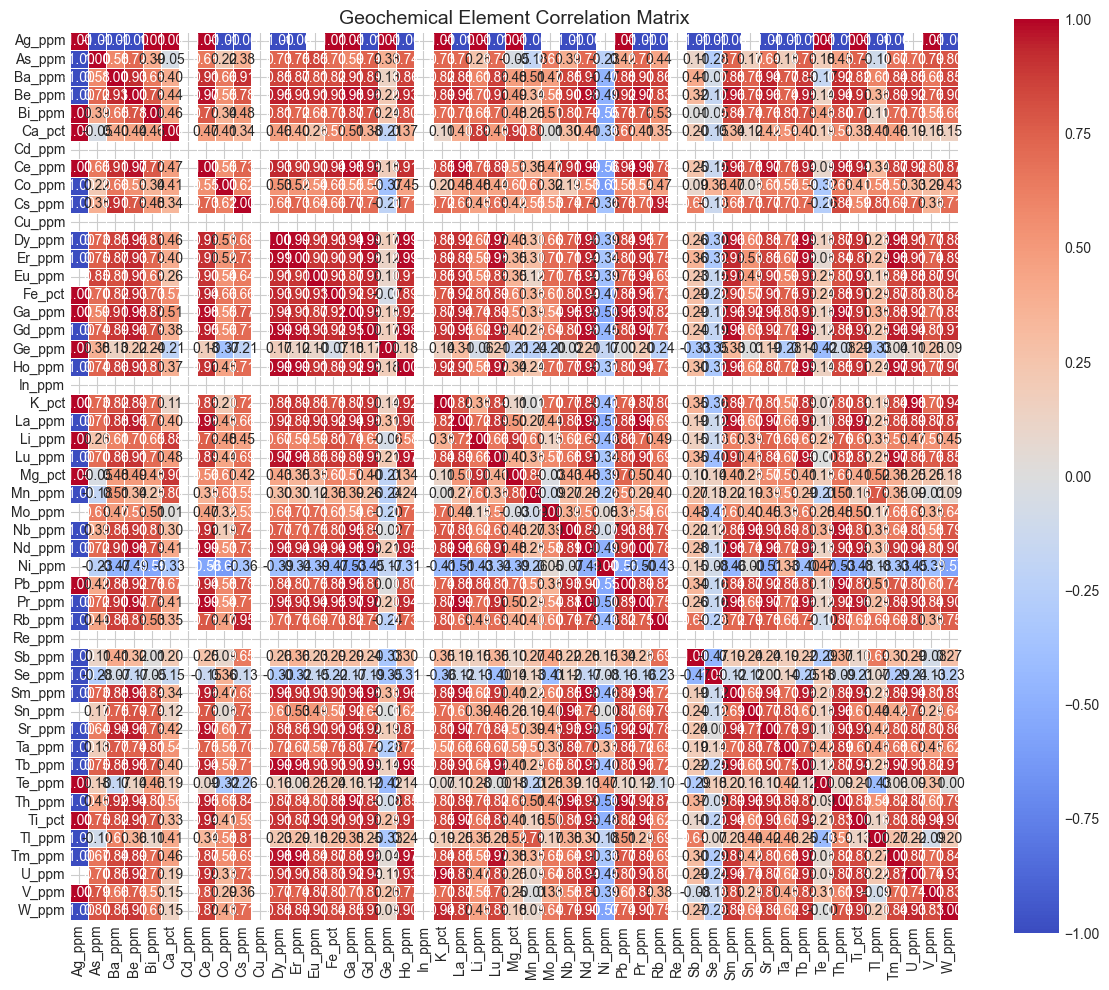


🔍 SPECIFIC CORRELATIONS

🤖 MACHINE LEARNING - PREDICT Zn

📊 SCATTER PLOTS

✅ ANALYSIS COMPLETE!


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Set style
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except:
    plt.style.use('seaborn-whitegrid')
sns.set_palette("husl")

print("=" * 80)
print("📊 GEOCHEMICAL DATA ANALYSIS")
print("=" * 80)

# 1. Clean the data - replace comma decimals with dots
def clean_geochem_data(df):
    """Clean geochemical data by converting comma decimals to dots"""
    df_clean = df.copy()
    
    for col in df_clean.columns:
        if df_clean[col].dtype == 'object':
            # Convert to string and replace comma with dot
            df_clean[col] = df_clean[col].astype(str).str.replace(',', '.')
            # Try to convert to numeric
            df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    
    return df_clean

# 2. Handle BDL values (values with '<')
def handle_bdl_values(df):
    """Convert < values to half the minimum value"""
    df_bdl = df.copy()
    
    for col in df_bdl.columns:
        # Check for '<' in the column
        if df_bdl[col].dtype == 'object':
            bdl_mask = df_bdl[col].astype(str).str.contains('<', na=False)
            if bdl_mask.any():
                # Extract numeric parts
                df_bdl[col] = df_bdl[col].astype(str).str.replace('<', '')
                df_bdl[col] = pd.to_numeric(df_bdl[col], errors='coerce')
                # Set BDL values to half the minimum
                min_val = df_bdl[col].min()
                if not np.isnan(min_val):
                    df_bdl.loc[bdl_mask, col] = min_val / 2
    
    return df_bdl

# Clean the data
df_clean = clean_geochem_data(df)
df_clean = handle_bdl_values(df_clean)

print("\n✅ Data cleaned successfully!")
print(f"   Shape: {df_clean.shape}")
print(f"   Columns: {len(df_clean.columns)}")

# 3. Define mouf class with fixed functions
class mouf:
    def __init__(self, df):
        self.df = df.copy()
        self.original_df = df.copy()
        self.numeric_col = []
        self.feature_n = None
        self.target_n = None
        self.results = {}
        self.report = {}
        self.skip_col = ['point_ID', 'X', 'Y', 'Z', 'lithology']
        
        print(f"\n🔬 mouf initialized")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        print("   Skipping columns:", self.skip_col)
    
    def conv_numeri(self):
        """Convert columns to numeric"""
        print("\n🔄 Converting to numeric...")
        
        converted = 0
        for col in self.df.columns:
            if any(skip in col for skip in self.skip_col):
                print(f"   ⏭️ Skipping: {col}")
                continue
            
            try:
                # If already numeric, skip
                if pd.api.types.is_numeric_dtype(self.df[col]):
                    self.numeric_col.append(col)
                    converted += 1
                    continue
                
                # Try to convert to numeric
                self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
                if self.df[col].notna().any():
                    self.numeric_col.append(col)
                    converted += 1
                    print(f"   ✅ Converted: {col}")
                else:
                    print(f"   ⚠️ All NaN in: {col}")
            except Exception as e:
                print(f"   ❌ Could not convert: {col} - {str(e)}")
        
        print(f"\n✅ Converted {converted} columns to numeric")
        print(f"   Total numeric columns: {len(self.numeric_col)}")
        return self.df
    
    def get_summary(self):
        """Display summary statistics"""
        print("\n" + "=" * 80)
        print("📊 DATA SUMMARY")
        print("=" * 80)
        
        print(f"\n📁 Dataset:")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        
        if self.numeric_col:
            print(f"\n🔢 Numeric Columns ({len(self.numeric_col)}):")
            # Show first 15 numeric columns
            display_cols = self.numeric_col[:15]
            print(f"   {', '.join(display_cols)}")
            if len(self.numeric_col) > 15:
                print(f"   ... and {len(self.numeric_col) - 15} more")
            
            print(f"\n📈 Statistics for numeric columns:")
            print(self.df[self.numeric_col].describe())
        else:
            print("\n⚠️ No numeric columns found. Run conv_numeri() first.")
        
        return self.df
    
    def pearson_correlation(self, col1, col2):
        """Calculate Pearson correlation - FIXED for missing values"""
        # Check if columns exist
        if col1 not in self.df.columns or col2 not in self.df.columns:
            print(f"\n⚠️ Column not found: {col1 if col1 not in self.df.columns else col2}")
            return None
        
        # Combine both columns and drop rows where either is NaN
        combined_data = self.df[[col1, col2]].dropna()
        
        if len(combined_data) < 2:
            print(f"\n⚠️ Not enough data for correlation between {col1} and {col2}")
            return None
        
        data1 = combined_data[col1]
        data2 = combined_data[col2]
        
        try:
            corr, p_value = pearsonr(data1, data2)
        except Exception as e:
            print(f"\n⚠️ Error calculating correlation: {e}")
            return None
        
        print(f"\n📊 PEARSON CORRELATION: {col1} vs {col2}")
        print(f"   Samples: {len(combined_data)}")
        print(f"   Correlation: {corr:.4f}")
        print(f"   P-value: {p_value:.4e}")
        print(f"   Significant: {p_value < 0.05}")
        
        # Interpret correlation strength
        abs_corr = abs(corr)
        if abs_corr >= 0.8:
            strength = "Very Strong"
        elif abs_corr >= 0.6:
            strength = "Strong"
        elif abs_corr >= 0.4:
            strength = "Moderate"
        elif abs_corr >= 0.2:
            strength = "Weak"
        else:
            strength = "Very Weak"
        
        print(f"   Strength: {strength}")
        
        return {'correlation': corr, 'p_value': p_value, 'n_samples': len(combined_data)}
    
    def set_features_target(self, feature_cols, target_col):
        """Set features and target for modeling"""
        # Check if columns exist
        for col in feature_cols + [target_col]:
            if col not in self.df.columns:
                raise ValueError(f"Column not found: {col}")
        
        # Remove rows with NaN in features or target
        self.df_clean_model = self.df[feature_cols + [target_col]].dropna()
        
        if len(self.df_clean_model) == 0:
            raise ValueError("No complete rows after dropping NaN values")
        
        self.feature_n = feature_cols
        self.target_n = target_col
        self.X = self.df_clean_model[feature_cols]
        self.y = self.df_clean_model[target_col]
        
        print(f"\n✅ Features: {feature_cols}")
        print(f"✅ Target: {target_col}")
        print(f"   Samples used: {len(self.df_clean_model)}")
        print(f"   X shape: {self.X.shape}")
        print(f"   y shape: {self.y.shape}")
        
        return self.X, self.y
    
    def train_linear_regression(self, test_size=0.2, random_state=42):
        """Train linear regression model"""
        if self.X is None or self.y is None:
            raise ValueError("Set features and target first using set_features_target()")
        
        if len(self.X) < 5:
            raise ValueError(f"Not enough samples for regression (need at least 5, have {len(self.X)})")
        
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y, test_size=min(test_size, 0.5), random_state=random_state
        )
        
        model = LinearRegression()
        model.fit(X_train, y_train)
        
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)
        
        print(f"\n📈 LINEAR REGRESSION RESULTS")
        print(f"   Train R²: {train_r2:.4f}")
        print(f"   Test R²: {test_r2:.4f}")
        print(f"\n   Model Equation:")
        equation = f"{self.target_n} = {model.intercept_:.4f}"
        for i, feat in enumerate(self.feature_n):
            coef = model.coef_[i]
            sign = "+" if coef >= 0 else "-"
            equation += f" {sign} {abs(coef):.4f}×{feat}"
        print(f"   {equation}")
        
        self.results['linear_regression'] = {
            'model': model,
            'coefficients': dict(zip(self.feature_n, model.coef_)),
            'intercept': model.intercept_,
            'train_r2': train_r2,
            'test_r2': test_r2,
            'X_train': X_train,
            'X_test': X_test,
            'y_train': y_train,
            'y_test': y_test,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred
        }
        
        return model

# 4. Initialize analyzer
analyzer = mouf(df_clean)
analyzer.conv_numeri()
analyzer.get_summary()

# 5. Correlation analysis (with fixed function)
print("\n" + "=" * 80)
print("🔍 CORRELATION ANALYSIS")
print("=" * 80)

# Find element columns
element_cols = [col for col in analyzer.numeric_col if '_ppm' in col or '_pct' in col]

if len(element_cols) >= 2:
    # Pairwise correlations for all elements
    print("\n📊 Correlation Matrix for Elements:")
    corr_matrix = analyzer.df[element_cols].corr()
    
    # Display correlations with Zn
    if 'Zn_ppm' in corr_matrix.columns:
        print("\n📈 Correlations with Zn:")
        zn_corr = corr_matrix['Zn_ppm'].sort_values(ascending=False)
        print(zn_corr)
    
    # Correlation heatmap
    if len(element_cols) > 1:
        plt.figure(figsize=(12, 10))
        sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
                    center=0, square=True, linewidths=0.5)
        plt.title('Geochemical Element Correlation Matrix', fontsize=14)
        plt.tight_layout()
        plt.show()

# 6. Specific correlation examples
print("\n" + "=" * 80)
print("🔍 SPECIFIC CORRELATIONS")
print("=" * 80)

if 'Pb_ppm' in analyzer.df.columns and 'Zn_ppm' in analyzer.df.columns:
    analyzer.pearson_correlation('Pb_ppm', 'Zn_ppm')

if 'Cu_ppm' in analyzer.df.columns and 'Zn_ppm' in analyzer.df.columns:
    analyzer.pearson_correlation('Cu_ppm', 'Zn_ppm')

if 'As_ppm' in analyzer.df.columns and 'Zn_ppm' in analyzer.df.columns:
    analyzer.pearson_correlation('As_ppm', 'Zn_ppm')

# 7. Machine Learning - Predict Zn
print("\n" + "=" * 80)
print("🤖 MACHINE LEARNING - PREDICT Zn")
print("=" * 80)

# Find best predictors for Zn
if 'Zn_ppm' in analyzer.df.columns:
    # Find columns with good correlation to Zn
    correlations = analyzer.df[element_cols].corr()['Zn_ppm'].sort_values(ascending=False)
    print("\n📈 Best predictors for Zn:")
    print(correlations)
    
    # Select top 2 predictors (excluding Zn itself)
    predictors = correlations.index[1:3].tolist() if len(correlations) > 2 else ['Pb_ppm']
    
    if predictors and 'Zn_ppm' in analyzer.df.columns:
        try:
            analyzer.set_features_target(predictors, 'Zn_ppm')
            analyzer.train_linear_regression()
            
            # Plot results
            if 'linear_regression' in analyzer.results:
                results = analyzer.results['linear_regression']
                
                fig, axes = plt.subplots(1, 2, figsize=(14, 5))
                
                # Actual vs Predicted
                ax1 = axes[0]
                ax1.scatter(results['y_test'], results['y_test_pred'], alpha=0.6, color='steelblue')
                min_val = min(results['y_test'].min(), results['y_test_pred'].min())
                max_val = max(results['y_test'].max(), results['y_test_pred'].max())
                ax1.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
                ax1.set_xlabel('Actual Zn')
                ax1.set_ylabel('Predicted Zn')
                ax1.set_title(f'Actual vs Predicted Zn (R² = {results["test_r2"]:.4f})')
                ax1.grid(True, alpha=0.3)
                
                # Residuals
                ax2 = axes[1]
                residuals = results['y_test'] - results['y_test_pred']
                ax2.scatter(results['y_test_pred'], residuals, alpha=0.6, color='purple')
                ax2.axhline(y=0, color='red', linestyle='--', linewidth=2)
                ax2.set_xlabel('Predicted Zn')
                ax2.set_ylabel('Residual')
                ax2.set_title('Residual Plot')
                ax2.grid(True, alpha=0.3)
                
                plt.tight_layout()
                plt.show()
        except Exception as e:
            print(f"\n⚠️ Could not train model: {e}")

# 8. Scatter plots
print("\n" + "=" * 80)
print("📊 SCATTER PLOTS")
print("=" * 80)

if 'Pb_ppm' in analyzer.df.columns and 'Zn_ppm' in analyzer.df.columns:
    plt.figure(figsize=(10, 6))
    plt.scatter(analyzer.df['Pb_ppm'], analyzer.df['Zn_ppm'], alpha=0.7, s=80, color='steelblue')
    plt.xlabel('Pb (ppm)', fontsize=12)
    plt.ylabel('Zn (ppm)', fontsize=12)
    plt.title('Pb vs Zn Relationship', fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.show()

print("\n" + "=" * 80)
print("✅ ANALYSIS COMPLETE!")
print("=" * 80)

In [17]:
import pandas as pd
import numpy as np

# ============================================
# 1. CREATE SAMPLE DATA (Like your CSV)
# ============================================

# Sample apartment data
data = {
    'apartment_id': ['A101', 'A102', 'A103', 'A104', 'A105'],
    'street': ['Keimstrasse', 'Hauptstrasse', 'Keimstrasse', 'Bahnhofstrasse', 'Keimstrasse'],
    'house_number': ['12', '45', '8', '23', '34'],
    'city': ['Worms', 'Mainz', 'Worms', 'Frankfurt', 'Worms'],
    'postal_code': ['67547', '55116', '67547', '60313', '67547'],
    'resident_name': ['Mohamed', 'Anna', 'Thomas', 'Maria', 'Sarah'],
    'has_rented': ['Yes', 'No', 'Yes', 'No', 'Yes']
}

df_apartments = pd.DataFrame(data)
print("=" * 60)
print("🏢 APARTMENT DATA")
print("=" * 60)
print(df_apartments)

# ============================================
# 2. THE CLEANING PATTERN (Like your geochemical code)
# ============================================

def clean_address_data(df):
    """
    Clean address data - same pattern as geochemical cleaning
    
    Concept: Loop through columns, check type, clean if needed
    """
    df_clean = df.copy()
    
    for col in df_clean.columns:
        # Check if column is text (same as your code!)
        if df_clean[col].dtype == 'object':
            # Clean the data - remove extra spaces, fix case
            df_clean[col] = df_clean[col].astype(str).str.strip()
            df_clean[col] = df_clean[col].str.title()  # Capitalize properly
            
    return df_clean

# Clean the data
df_clean = clean_address_data(df_apartments)
print("\n" + "=" * 60)
print("🧹 CLEANED APARTMENT DATA")
print("=" * 60)
print(df_clean)

# ============================================
# 3. FIND ADDRESSES (Like your loop through columns)
# ============================================

def find_addresses(df, target_street):
    """
    Find apartments on a specific street
    
    Concept: Loop through each row (address) and check if it matches
    This is the same pattern as looping through columns!
    """
    print("\n" + "=" * 60)
    print(f"🔍 SEARCHING FOR: {target_street}")
    print("=" * 60)
    
    found_addresses = []
    not_found = []
    
    # LOOP through each address (like your for col in columns)
    for index, row in df.iterrows():
        street = row['street']
        apartment_id = row['apartment_id']
        
        # CHECK condition (like your if col.dtype == 'object')
        if target_street.lower() in street.lower():
            print(f"✅ FOUND: {apartment_id} - {street} {row['house_number']}")
            found_addresses.append({
                'apartment_id': apartment_id,
                'street': street,
                'house_number': row['house_number'],
                'city': row['city'],
                'resident': row['resident_name']
            })
        else:
            print(f"   Not on {target_street}: {apartment_id} - {street}")
            not_found.append(apartment_id)
    
    # Return results (like returning cleaned DataFrame)
    print(f"\n📊 Results: {len(found_addresses)} found, {len(not_found)} not found")
    return found_addresses, not_found

# Search for Keimstrasse
found, not_found = find_addresses(df_clean, "Keimstrasse")

# ============================================
# 4. SEND MESSAGES (Action after finding)
# ============================================

def send_message_to_addresses(addresses, message_type="rent_reminder"):
    """
    Send messages to found addresses
    
    Concept: Take action on each found address (like converting to numeric)
    """
    print("\n" + "=" * 60)
    print("📨 SENDING MESSAGES")
    print("=" * 60)
    
    messages_sent = 0
    messages_failed = []
    
    # LOOP through each found address (like your to_numeric loop)
    for address in addresses:
        try:
            # Build message based on address
            resident = address['resident']
            street = address['street']
            house = address['house_number']
            
            if message_type == "rent_reminder":
                message = f"""
                📬 RENT REMINDER
                To: {resident}
                Address: {street} {house}
                
                Dear {resident},
                
                This is a reminder that your rent is due on the 1st.
                Please make the payment to the office.
                
                Thank you,
                Property Management
                """
            elif message_type == "welcome":
                message = f"""
                🏠 WELCOME MESSAGE
                To: {resident}
                Address: {street} {house}
                
                Welcome to your new apartment!
                We hope you enjoy living here.
                
                Best regards,
                Property Management
                """
            else:
                message = f"Hello {resident}, this is a message for {street} {house}"
            
            # Simulate sending message
            print(f"\n📤 Sending message to: {resident}")
            print(f"   Address: {street} {house}")
            print(f"   Message: {message[:80]}...")
            
            messages_sent += 1
            
        except Exception as e:
            print(f"❌ Failed to send to {address['apartment_id']}: {e}")
            messages_failed.append(address['apartment_id'])
    
    # Return results
    print(f"\n✅ Messages sent: {messages_sent}")
    print(f"❌ Messages failed: {len(messages_failed)}")
    return messages_sent, messages_failed

# Send messages to found addresses
messages_sent, messages_failed = send_message_to_addresses(found, "rent_reminder")

# ============================================
# 5. ADVANCED: Conditional Action (Like 'skip_col' logic)
# ============================================

class PropertyManager:
    """
    Class to manage apartments - similar to your mouf class
    """
    
    def __init__(self, df):
        self.df = df
        self.skip_streets = ['Mainz']  # Streets to skip
        self.processed = []
        self.skipped = []
        self.errors = []
    
    def process_addresses(self, target_street, action="send_message"):
        """
        Process addresses with skip logic
        Similar to: if any(skip in col for skip in self.skip_col)
        """
        print("\n" + "=" * 60)
        print(f"🔄 PROCESSING ADDRESSES: {target_street}")
        print("=" * 60)
        
        for index, row in self.df.iterrows():
            street = row['street']
            city = row['city']
            apartment_id = row['apartment_id']
            
            # SKIP condition (like your any(skip in col for skip in skip_col))
            if any(skip in city for skip in self.skip_streets):
                print(f"⏭️ SKIPPED: {apartment_id} - {street} (city: {city})")
                self.skipped.append(apartment_id)
                continue
            
            # Process if not skipped
            if target_street.lower() in street.lower():
                print(f"✅ PROCESSING: {apartment_id} - {street}")
                
                # Different actions based on parameter
                if action == "send_message":
                    # Send message
                    print(f"   📨 Message sent to {row['resident_name']}")
                elif action == "send_package":
                    # Send package
                    print(f"   📦 Package sent to {row['resident_name']}")
                elif action == "inspect":
                    # Schedule inspection
                    print(f"   🔍 Inspection scheduled for {street} {row['house_number']}")
                
                self.processed.append(apartment_id)
            else:
                print(f"   Not on {target_street}: {apartment_id}")
                self.errors.append(apartment_id)
        
        # Summary
        print(f"\n📊 Summary:")
        print(f"   ✅ Processed: {len(self.processed)}")
        print(f"   ⏭️ Skipped: {len(self.skipped)}")
        print(f"   ❌ Errors: {len(self.errors)}")
        
        return self.processed, self.skipped, self.errors

# Create property manager
manager = PropertyManager(df_clean)

# Process with different actions
manager.process_addresses("Keimstrasse", "send_message")
manager.process_addresses("Keimstrasse", "send_package")

# ============================================
# 6. COMPLETE PIPELINE (Like your geochemical pipeline)
# ============================================

def complete_property_pipeline(df, target_street, action):
    """
    Complete pipeline for processing addresses
    Same pattern as your geochemical pipeline!
    """
    print("\n" + "=" * 60)
    print("🏢 COMPLETE PROPERTY PIPELINE")
    print("=" * 60)
    
    # Step 1: Clean data (like conv_numeri)
    print("\n1️⃣ Cleaning data...")
    df_clean = clean_address_data(df)
    
    # Step 2: Find addresses (like pearson_correlation)
    print(f"\n2️⃣ Finding addresses on {target_street}...")
    found, not_found = find_addresses(df_clean, target_street)
    
    # Step 3: Process addresses (like train_linear_regression)
    print(f"\n3️⃣ Processing {len(found)} addresses...")
    manager = PropertyManager(df_clean)
    manager.process_addresses(target_street, action)
    
    # Step 4: Report results (like report_show)
    print("\n4️⃣ Generating report...")
    report = {
        'total_apartments': len(df_clean),
        'found_addresses': len(found),
        'not_found': len(not_found),
        'processed': len(manager.processed),
        'skipped': len(manager.skipped),
        'action_taken': action
    }
    
    print("\n📊 FINAL REPORT:")
    for key, value in report.items():
        print(f"   {key}: {value}")
    
    return report

# Run the complete pipeline
report = complete_property_pipeline(df_apartments, "Keimstrasse", "send_message")

# ============================================
# 7. ANALOGY MAP: Geochemical Code ↔ Address Code
# ============================================

print("\n" + "=" * 60)
print("📚 LOGIC ANALOGY MAP")
print("=" * 60)

analogies = [
    ("Geochemical", "Address", "Explanation"),
    ("--------", "--------", "---------"),
    ("for col in columns", "for address in data", "Loop through items"),
    ("if col.dtype == 'object'", "if street == target", "Check condition"),
    ("pd.to_numeric()", "send_message()", "Take action"),
    ("skip_col = ['ID']", "skip_streets = ['Mainz']", "Skip certain items"),
    ("df[col] = converted", "address['message'] = message", "Store result"),
    ("return df_clean", "return found_addresses", "Return results"),
    ("mouf class", "PropertyManager class", "Organize code"),
]

for row in analogies:
    print(f"{row[0]:20} → {row[1]:20} | {row[2]}")

🏢 APARTMENT DATA
  apartment_id          street house_number       city postal_code  \
0         A101     Keimstrasse           12      Worms       67547   
1         A102    Hauptstrasse           45      Mainz       55116   
2         A103     Keimstrasse            8      Worms       67547   
3         A104  Bahnhofstrasse           23  Frankfurt       60313   
4         A105     Keimstrasse           34      Worms       67547   

  resident_name has_rented  
0       Mohamed        Yes  
1          Anna         No  
2        Thomas        Yes  
3         Maria         No  
4         Sarah        Yes  

🧹 CLEANED APARTMENT DATA
  apartment_id          street house_number       city postal_code  \
0         A101     Keimstrasse           12      Worms       67547   
1         A102    Hauptstrasse           45      Mainz       55116   
2         A103     Keimstrasse            8      Worms       67547   
3         A104  Bahnhofstrasse           23  Frankfurt       60313   
4         A1

In [ ]:
def clean_df(df):
    for col in columns:
        if df[col] == 'object':
            df[col] = df.[col].as

In [19]:
import pandas as pd
import numpy as np
import random

# ============================================
# CREATE MESSY DATA WITH VARIOUS PROBLEMS
# ============================================

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)

# Create 20 rows of messy geochemical data
data = {
    'Sample_ID': [f'S{i:03d}' for i in range(1, 21)],
    
    # Problem 1: Numbers with commas instead of dots
    'Cu_ppm': [f"{np.random.uniform(5, 50):.2f}".replace('.', ',') for _ in range(20)],
    
    # Problem 2: Mixed types - some numbers, some text
    'Zn_ppm': [f"{np.random.uniform(10, 100):.2f}".replace('.', ',') for _ in range(20)],
    
    # Problem 3: BDL values with < symbol
    'Pb_ppm': [f"<{np.random.uniform(0.5, 5):.2f}".replace('.', ',') if random.random() < 0.3 
               else f"{np.random.uniform(1, 30):.2f}".replace('.', ',') 
               for _ in range(20)],
    
    # Problem 4: Extra spaces and special characters
    'As_ppm': [f" {np.random.uniform(1, 20):.2f} " if random.random() < 0.5 
               else f"{np.random.uniform(1, 20):.2f}".replace('.', ',')
               for _ in range(20)],
    
    # Problem 5: Text that should be text (don't convert)
    'Lithology': random.choices(['  Sandstone', 'Shale  ', '  Limestone  ', 'Granite'], k=20),
    
    # Problem 6: Missing values (NaN)
    'Ag_ppm': [f"{np.random.uniform(0.1, 5):.2f}".replace('.', ',') if random.random() < 0.8 
               else 'NA' 
               for _ in range(20)],
    
    # Problem 7: Wrong decimal format (2,5 instead of 2.5)
    'Au_ppm': [f"{np.random.uniform(0.01, 1):.2f}".replace('.', ',') for _ in range(20)],
    
    # Problem 8: Empty strings
    'Fe_pct': [f"{np.random.uniform(1, 15):.2f}".replace('.', ',') if random.random() < 0.9 
               else '' 
               for _ in range(20)],
}

df_messy = pd.DataFrame(data)

print("=" * 70)
print("📊 MESSY DATA - YOUR TURN TO CLEAN!")
print("=" * 70)
print("\nFirst 10 rows:")
print(df_messy.head(10))

print("\n" + "=" * 70)
print("📋 DATA TYPES AND PROBLEMS")
print("=" * 70)
print(df_messy.dtypes)

print("\n🔍 SAMPLE OF MESSY VALUES:")
print("\nCu_ppm (comma decimals):")
print(df_messy['Cu_ppm'].head(10).tolist())

print("\nPb_ppm (BDL values with <):")
print(df_messy['Pb_ppm'].head(10).tolist())

print("\nLithology (extra spaces):")
print(df_messy['Lithology'].head(10).tolist())

print("\nAg_ppm (missing values as 'NA'):")
print(df_messy['Ag_ppm'].head(10).tolist())

📊 MESSY DATA - YOUR TURN TO CLEAN!

First 10 rows:
  Sample_ID Cu_ppm Zn_ppm Pb_ppm   As_ppm      Lithology Ag_ppm Au_ppm Fe_pct
0      S001  21,85  65,07   4,54     8,38    Limestone       NA   0,50  13,20
1      S002  47,78  22,55  <2,73     6,16      Sandstone   4,33   0,53  12,25
2      S003  37,94  36,29  <0,65   16.75       Sandstone   3,15   0,43   3,61
3      S004  31,94  42,97  <4,59    7.78         Shale     1,72   0,04  13,50
4      S005  12,02  51,05   8,50     6,34      Sandstone     NA   0,12   8,55
5      S006  12,02  80,67  20,21   11.31       Sandstone   0,41   0,04  12,30
6      S007   7,61  27,97  10,04    3.68       Sandstone   1,62   0,64       
7      S008  43,98  56,28  <2,84   16.24         Shale     1,69   0,32  13,55
8      S009  32,05  63,32  16,85     2,42    Limestone     3,68   0,51   5,45
9      S010  36,86  14,18  <1,33    19,75        Shale     3,22   0,91   2,54

📋 DATA TYPES AND PROBLEMS
Sample_ID    object
Cu_ppm       object
Zn_ppm       object
Pb_p

In [21]:
print(df_messy.astype())

TypeError: NDFrame.astype() missing 1 required positional argument: 'dtype'

In [23]:
a = np.array([1, 2, 3], dtype=np.int64)
b = a.astype(np.float32)

print(a.dtype)  # int64 (unchanged)
print(b.dtype)  # float32 (new array with new type)

int64
float32


In [25]:
b

array([1., 2., 3.], dtype=float32)

In [27]:
for col in self.df.columns: #colby col
    if self.df[col].dtype == 'object': 
        #if true: that means we have object data in certain column
        #we need to confirm whether that object is ppm or not: we need to do somethings before that
        #1.convert the object data(true statement) into string and make everythin in lower case 
        #2.then compare the result with 'ppm' 3. if the statement is True we go ahead to next step
        #like we need to confirm that if the object data type is ppm or not
        mask = self.df[col].astype(str).str.lower() == 'ppm'
        #if the result is true : then remove the row where ppm exist it is not only first row but any row has 'ppm'
        if mask.any():
            #if any column has at least True , do this :
            self.df = self.df[~mask]
     
        


        
        
        
        

In [125]:
import pandas as pd
import numpy as np

# ============================================================
# SIMULATE GEOCHEMICAL DATA
# ============================================================

# This is what your CSV might look like
data = {
    'Sample_ID': ['S-1', 'S-2', 'S-3', 'S-4', 'S-5','S-6'],
    'Au_ppm': ['0.05', 'nan','1.20', '0.08', '0.12', '0.15'],
    'Cu_ppm': ['30', '450', 'nan','25', '40', '35'],
    'Zn_ppm': ['45', '320', '38', '55', '42', 'nan'],
    'Rock_Type': ['Granite','nan' ,'Basalt', 'Granite', 'Basalt', 'Granite']
}

df = pd.DataFrame(data)

print("="*70)
print("1. RAW DATA")
print("="*70)
print(df)
print(f"\nData types:\n{df.dtypes}")

# ============================================================
# SIMULATE THE INITIALIZATION PROCESS
# ============================================================

print("\n" + "="*70)
print("2. INITIALIZATION PROCESS")
print("="*70)

# STEP 1: Clean data (simplified)
print("\n📌 Step 1: Cleaning data...")
print("   Removing 'ppm' rows (none in this case)")
print("   Converting text numbers to numeric...")

df['Au_ppm'] = pd.to_numeric(df['Au_ppm'])
df['Cu_ppm'] = pd.to_numeric(df['Cu_ppm'])
df['Zn_ppm'] = pd.to_numeric(df['Zn_ppm'])

print(f"   Data types now:\n{df.dtypes}")

# STEP 2: Identify numeric columns
print("\n📌 Step 2: Identifying numeric columns...")
element_columns = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"   Numeric columns found: {element_columns}")

# STEP 3: Extract matrix
print("\n📌 Step 3: Extracting data matrix...")
X = df[element_columns].to_numpy(dtype=float)
print(f"   Matrix:\n{X}")

# STEP 4: Store shape
print("\n📌 Step 4: Storing metadata...")
n_samples, n_elements = X.shape
print(f"   Samples (rows): {n_samples}")
print(f"   Elements (columns): {n_elements}")
print(f"   Shape: {X.shape}")

print("\n" + "="*70)
print("3. COMPLETE")
print("="*70)
print(f"✅ {n_samples} samples, {n_elements} elements ready for analysis!")
print(f"✅ Elements: {element_columns}")
print( )

1. RAW DATA
  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
0       S-1   0.05     30     45   Granite
1       S-2    nan    450    320       nan
2       S-3   1.20    nan     38    Basalt
3       S-4   0.08     25     55   Granite
4       S-5   0.12     40     42    Basalt
5       S-6   0.15     35    nan   Granite

Data types:
Sample_ID    object
Au_ppm       object
Cu_ppm       object
Zn_ppm       object
Rock_Type    object
dtype: object

2. INITIALIZATION PROCESS

📌 Step 1: Cleaning data...
   Removing 'ppm' rows (none in this case)
   Converting text numbers to numeric...


ValueError: Unable to parse string "nan" at position 1

In [5]:
df[element_columns].describe()

,Au_ppm,Cu_ppm,Zn_ppm
count,5.000000,5.000000,5.000000
mean,0.320000,116.000000,100.000000
std,0.493407,186.795343,123.144224
min,0.050000,25.000000,38.000000
25%,0.080000,30.000000,42.000000
50%,0.120000,35.000000,45.000000
75%,0.150000,40.000000,55.000000
max,1.200000,450.000000,320.000000


In [13]:
df['Au_ppm'].describe()

count    60.000000
mean      0.313667
std       0.780471
min       0.000000
25%       0.000000
50%       0.010000
75%       0.117500
max       3.660000
Name: Au_ppm, dtype: float64

In [15]:
df

,Sample_Id,Au_ppm,X_UTM,Y_UTM,Z_m,Zone,Grade_Class
0,D01,3.03,505417,2361629,373,Chip Zone D,High Grade (>1 g/t)
1,D02,2.43,505419,2361626,373,Chip Zone D,High Grade (>1 g/t)
2,D03,3.66,505421,2361625,373,Chip Zone D,High Grade (>1 g/t)
3,D04,2.64,505423,2361624,373,Chip Zone D,High Grade (>1 g/t)
4,D05,0.25,505423,2361623,373,Chip Zone D,Low Grade (<0.5 g/t)
5,D06,1.88,505420,2361624,373,Chip Zone D,High Grade (>1 g/t)
6,D07,0.43,505410,2361636,374,Chip Zone D,Low Grade (<0.5 g/t)
7,D08,0.00,505425,2361622,373,Chip Zone D,Background/No Anomaly
8,D09,0.10,505384,2361650,375,Chip Zone D,Low Grade (<0.5 g/t)
9,D10,0.78,505392,2361648,375,Chip Zone D,Medium Grade (0.5-1 g/t)


In [21]:
df[element_columns].corr()

,Au_ppm,Cu_ppm,Zn_ppm
Au_ppm,1.000000,0.998063,0.996500
Cu_ppm,0.998063,1.000000,0.999554
Zn_ppm,0.996500,0.999554,1.000000


array([[<Axes: title={'center': 'Au_ppm'}>,
        <Axes: title={'center': 'Cu_ppm'}>],
       [<Axes: title={'center': 'Zn_ppm'}>, <Axes: >]], dtype=object)

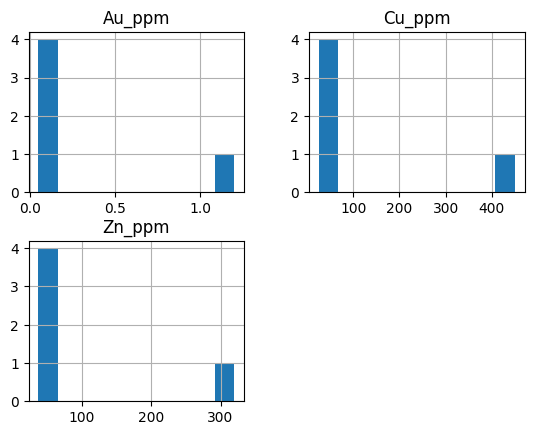

In [23]:
df[element_columns].hist()

In [ ]:
#identify numeric columns
if element_column is None:
    element_column = df.select_dtype[np.numbers].columns.tolist()
    

In [101]:
def load_geochemical_data():
    """Load the confidential geochemical data."""
    
    # CHIP ZONE D data
    chip_data = pd.DataFrame({
        'Sample_Id': ['D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10'],
        'Au_ppm': [3.03, 2.43, 3.66, 2.64, 0.25, 1.88, 0.43, 0.00, 0.10, 0.78],
        'X_UTM': [505417, 505419, 505421, 505423, 505423, 505420, 505410, 505425, 505384, 505392],
        'Y_UTM': [2361629, 2361626, 2361625, 2361624, 2361623, 2361624, 2361636, 2361622, 2361650, 2361648],
        'Z_m': [373, 373, 373, 373, 373, 373, 374, 373, 375, 375],
        'Zone': 'Chip Zone D'
    })
    
    # TRENCH ZONE A data (first 50 samples for demonstration)
    trench_data = pd.DataFrame({
        'Sample_Id': [f'BRT{i}' for i in range(1801, 1851)],
        'Au_ppm': [0.02, 0.01, 0, 0, 0.14, 0.09, 0.08, 0.14, 1.05, 0.06, 
                   0.01, 0, 0, 0, 0, 0, 0, 0, 0, 0.01,
                   0, 0.02, 0.2, 0.77, 0.3, 0.04, 0, 0, 0, 0.02,
                   0.04, 0, 0, 0, 0.01, 0, 0.01, 0, 0, 0.06,
                   0.08, 0.05, 0.02, 0, 0, 0.11, 0, 0, 0, 0.28],
        'X_UTM': [504584, 504588, 504593, 504592, 504593, 504593, 504598, 504597, 504600, 504599,
                  504601, 504604, 504606, 504607, 504608, 504609, 506412, 504615, 504616, 504617,
                  504619, 504621, 504581, 504581, 504581, 504582, 504584, 504586, 504589, 504588,
                  504591, 504592, 504592, 504595, 504596, 504597, 504599, 504601, 504602, 504605,
                  504605, 504609, 504565, 504568, 504569, 504570, 504573, 504574, 504575, 504576],
        'Y_UTM': [2361909, 2361907, 2361907, 2361906, 2361907, 2391905, 2361906, 2361905, 2361905, 2361905,
                  2361904, 2361902, 2361903, 2361903, 2361901, 2361901, 2361900, 2361901, 2361901, 2361900,
                  2361900, 2361899, 2361887, 2361886, 2361885, 2361884, 2361883, 2361882, 2361883, 2361883,
                  2361883, 2361881, 2361882, 2361881, 2361881, 2361880, 2361879, 2361879, 2361879, 2361878,
                  2361877, 2361878, 2361852, 2361850, 2361851, 2361850, 2361849, 2361849, 2361849, 2361848],
        'Z_m': [371, 371, 370, 370, 370, 370, 370, 368, 370, 370,
                370, 370, 370, 369, 370, 371, 370, 370, 368, 370,
                369, 367, 368, 370, 369, 368, 368, 367, 367, 368,
                368, 367, 367, 368, 370, 369, 369, 369, 369, 369,
                379, 379, 370, 370, 370, 369, 369, 371, 371, 371],
        'Zone': 'Trench Zone A'
    })
    
    # Combine all data
    all_data = pd.concat([chip_data, trench_data], ignore_index=True)
    
    # Add grade classification
    def classify_grade(au):
        if au >= 1.0:
            return 'High Grade (>1 g/t)'
        elif au >= 0.5:
            return 'Medium Grade (0.5-1 g/t)'
        elif au > 0:
            return 'Low Grade (<0.5 g/t)'
        else:
            return 'Background/No Anomaly'
    
    all_data['Grade_Class'] = all_data['Au_ppm'].apply(classify_grade)
    
    return all_data

# Load the data
df = load_geochemical_data()
print(f"\n✅ Data loaded successfully")
print(f"   Total samples: {len(df)}")
print(f"   Zones: {df['Zone'].unique()}")
print(f"   Gold range: {df['Au_ppm'].min():.2f} - {df['Au_ppm'].max():.2f} g/t")



✅ Data loaded successfully
   Total samples: 60
   Zones: ['Chip Zone D' 'Trench Zone A']
   Gold range: 0.00 - 3.66 g/t


In [103]:
df

,Sample_Id,Au_ppm,X_UTM,Y_UTM,Z_m,Zone,Grade_Class
0,D01,3.03,505417,2361629,373,Chip Zone D,High Grade (>1 g/t)
1,D02,2.43,505419,2361626,373,Chip Zone D,High Grade (>1 g/t)
2,D03,3.66,505421,2361625,373,Chip Zone D,High Grade (>1 g/t)
3,D04,2.64,505423,2361624,373,Chip Zone D,High Grade (>1 g/t)
4,D05,0.25,505423,2361623,373,Chip Zone D,Low Grade (<0.5 g/t)
5,D06,1.88,505420,2361624,373,Chip Zone D,High Grade (>1 g/t)
6,D07,0.43,505410,2361636,374,Chip Zone D,Low Grade (<0.5 g/t)
7,D08,0.00,505425,2361622,373,Chip Zone D,Background/No Anomaly
8,D09,0.10,505384,2361650,375,Chip Zone D,Low Grade (<0.5 g/t)
9,D10,0.78,505392,2361648,375,Chip Zone D,Medium Grade (0.5-1 g/t)


In [105]:
# Latin-1 / ISO-8859-1 (very permissive, often works when cp1252 fails)
df = pd.read_csv('Li pb la mg ce.csv', encoding='latin1')

# UTF-8 with BOM (common from Excel on Windows)
df = pd.read_csv('Li pb la mg ce.csv', encoding='utf-8-sig')

# Fallback: ignore bad characters (may lose some data)
df = pd.read_csv('Li pb la mg ce.csv', encoding='utf-8', errors='ignore')

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc1 in position 431: invalid start byte

In [41]:
import pandas as pd

df = pd.read_csv('Li pb la mg ce.csv', encoding='cp1252')
print(df)

                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [65]:
#what problem: 'NaN' __ WE NEED TO Delete the any row contain NaN
def clean_df(df):
    for col in df.columns:
    if df[col].dtype == 'object':
        mask = df[col].astype(str).str.lower() == 'nan'
        print(f'{col}')
        if mask.any():
            df = df[~mask]
            print(f'df')
    return df
            
        
        
    

IndentationError: expected an indented block after 'for' statement on line 3 (2445151899.py, line 4)

In [97]:
import numpy as np
import pandas as pd

def clean_df(df: pd.DataFrame) -> pd.DataFrame:
    """
    Remove rows that contain:
      - real NaN values (np.nan)
      - the string 'NaN' (case-insensitive) in object columns
    """
 

    # 2. For object columns, also drop rows where the value is the string 'nan'
    
    for col in df.columns:
        mask = df[col] == 'nan'
        print(f'{col}')
        if mask.any():
            mask = df[~mask]
            print(f'{df}')

    return df
df_cl = clean_df(df)
print(df_cl)

Sample
MgO
Li
La
Th
Ce
Th.1
                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.8

In [71]:
df['MgO'].isna()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35     True
Name: MgO, dtype: bool

In [73]:
 type(np.nan) 

float

In [165]:
import numpy as np
import pandas as pd

def clean_df(df: pd.DataFrame) -> pd.DataFrame:
    """
    Remove rows that contain:
      - real NaN values (np.nan)
      - the string 'NaN' (case-insensitive) in any column
    """
    # 1. Drop rows with real NaN values first
    df = df.dropna()

    # 2. For all columns, also drop rows where the value is the string 'nan'
    for col in df.columns:
        mask = df[col].astype(str).str.lower() == 'nan'
        print(f'Column: {col}, rows with "nan": {mask.sum()}')
        if mask.any():
            df = df[~mask]
            print(f'After dropping rows from column {col}, df shape: {df.shape}')

    return df

df_cl = clean_df(df)
print(df_cl)


Column: Sample, rows with "nan": 0
Column: MgO, rows with "nan": 0
Column: Li, rows with "nan": 0
Column: La, rows with "nan": 0
Column: Th, rows with "nan": 0
Column: Ce, rows with "nan": 0
Column: Th.1, rows with "nan": 0
                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS

TypeError: 'Series' object is not callable

In [155]:
import pandas as pd

# Try Windows-1252 (Western European)
df = pd.read_csv('Li pb la mg ce.csv', encoding='cp1252')
print(df.head(36))

                Sample   MgO    Li     La     Th     Ce   Th.1
0              24044/1  0.55  39.5  40.81  29.70  85.78  29.70
1              24044/2  0.53  45.5  30.98  22.70  67.57  22.70
2              24044/3  0.68  52.1  33.43  20.10  66.50  20.10
3              24044/4  1.04  39.9  41.46  33.00  87.91  33.00
4              24044/5  0.55  49.8  44.96  32.90  93.17  32.90
5              24044/6  2.64  67.6  34.51  17.50  54.26  17.50
6              24044/7  0.50  34.3  26.93   8.52  40.31   8.52
7              24044/8  1.31  40.0  37.62  16.90  79.39  16.90
8              24044/9  0.61  45.3  13.84   7.38  25.89   7.38
9             24044/10  0.82  43.4  21.04  15.70  35.44  15.70
10     MÁF - ALMOU 2MS  0.19  20.0  34.70  27.70  64.50  27.70
11   MÁF - ALMOU 3MS-A  0.21  25.0  23.70  25.20  58.60  25.20
12   MÁF - ALMOU 3MS-B  0.26  74.0  42.80  27.70  90.20  27.70
13     MÁF - ALMOU 4MS  0.23  20.0  28.90  22.40  60.20  22.40
14    MÁF - ALMOU KR-1  0.88  23.0  28.00  21.10  60.30

In [119]:
df.columns

Index(['Sample', 'MgO', 'Li', 'La', 'Th', 'Ce', 'Th.1'], dtype='object')

In [157]:
df.dropna()


,Sample,MgO,Li,La,Th,Ce,Th.1
0,24044/1,0.55,39.5,40.81,29.70,85.78,29.70
1,24044/2,0.53,45.5,30.98,22.70,67.57,22.70
2,24044/3,0.68,52.1,33.43,20.10,66.50,20.10
3,24044/4,1.04,39.9,41.46,33.00,87.91,33.00
4,24044/5,0.55,49.8,44.96,32.90,93.17,32.90
5,24044/6,2.64,67.6,34.51,17.50,54.26,17.50
6,24044/7,0.50,34.3,26.93,8.52,40.31,8.52
7,24044/8,1.31,40.0,37.62,16.90,79.39,16.90
8,24044/9,0.61,45.3,13.84,7.38,25.89,7.38
9,24044/10,0.82,43.4,21.04,15.70,35.44,15.70


In [163]:
print(f'{df.dtypes()}')

TypeError: 'Series' object is not callable

In [205]:
import pandas as pd
import numpy as np

# ============================================================
# SIMULATE GEOCHEMICAL DATA
# ============================================================

# This is what your CSV might look like
data = {
    'Sample_ID': ['S-1', 'S-2', 'S-3', 'S-4', 'S-5','S-6', 'NaN'],
    'Au_ppm': ['0.05', '<0.1','1.20', '0.08', '0.12', '0.15', 'NaN'],
    'Cu_ppm': ['30', '450', '<0.1','25', '40', '35', 'NaN'],
    'Zn_ppm': ['45', '320', '<0.01', '55', '42', 'NaN', '<0.1'],
    'Rock_Type': ['Granite','NaN' ,'Basalt', 'Granite', 'Basalt', 'Granite', 'NaN']
}

df = pd.DataFrame(data)

print("="*70)
print("1. RAW DATA")
print("="*70)
print(df)
print(f"\nData types:\n{df.dtypes}")


1. RAW DATA
  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
0       S-1   0.05     30     45   Granite
1       S-2   <0.1    450    320       NaN
2       S-3   1.20   <0.1  <0.01    Basalt
3       S-4   0.08     25     55   Granite
4       S-5   0.12     40     42    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN   <0.1       NaN

Data types:
Sample_ID    object
Au_ppm       object
Cu_ppm       object
Zn_ppm       object
Rock_Type    object
dtype: object


In [145]:
df.dropna()

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
1,S-2,nan,450,320,NaN
2,S-3,1.20,nan,38,Basalt
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt
5,S-6,0.15,35,NaN,Granite
6,NaN,NaN,NaN,NaN,NaN


In [151]:
df['Au_ppm'].isna()

0    False
1    False
2    False
3    False
4    False
5    False
6    False
Name: Au_ppm, dtype: bool

In [153]:
df.isna()

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,False,False
6,False,False,False,False,False


In [173]:
import numpy as np
import pandas as pd

df = df.replace(['nan', 'NaN', 'NAN'], np.nan)


In [175]:
df.isna()

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,False,False,False,False,False
1,False,True,False,False,True
2,False,False,True,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,True,False
6,True,True,True,True,True


In [177]:
print(f"\nData types:\n{df.dtypes}")


Data types:
Sample_ID    object
Au_ppm       object
Cu_ppm       object
Zn_ppm       object
Rock_Type    object
dtype: object


In [179]:
df.dropna()

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt


In [181]:
print(df.isna().sum())
print(df[df.isna().any(axis=1)])

Sample_ID    1
Au_ppm       2
Cu_ppm       2
Zn_ppm       2
Rock_Type    2
dtype: int64
  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
1       S-2    NaN    450    320       NaN
2       S-3   1.20    NaN     38    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN    NaN       NaN


In [189]:
df = df.replace(['<0.1', '<0.1'], '0.5')
print(df)

  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
0       S-1   0.05     30     45   Granite
1       S-2    0.5    450    320       NaN
2       S-3   1.20    0.5     38    Basalt
3       S-4   0.08     25     55   Granite
4       S-5   0.12     40     42    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN    0.5       NaN


In [191]:
df.columns

Index(['Sample_ID', 'Au_ppm', 'Cu_ppm', 'Zn_ppm', 'Rock_Type'], dtype='object')

In [201]:
cols = ['Au_ppm', 'Cu_ppm', 'Zn_ppm', 'Rock_Type']
df[cols] = df[cols].replace(['nan', 'NaN', 'NAN'], np.nan)
df = df.dropna(subset=cols)

In [195]:
df

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
2,S-3,1.20,0.5,38,Basalt
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt


In [209]:
df

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
1,S-2,<0.1,450,320,NaN
2,S-3,1.20,<0.1,<0.01,Basalt
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt
5,S-6,0.15,35,NaN,Granite
6,NaN,NaN,NaN,<0.1,NaN


In [215]:
print(df.isna().sum())
print(df[df.isna().any(axis=1)])

Sample_ID    1
Au_ppm       1
Cu_ppm       1
Zn_ppm       1
Rock_Type    2
dtype: int64
  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
1       S-2   <0.1    450    320       NaN
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN   <0.1       NaN


In [219]:
df = df.replace(['nan', 'NaN', 'NAN'], np.nan)
print(df)

  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
0       S-1   0.05     30     45   Granite
1       S-2   <0.1    450    320       NaN
2       S-3   1.20   <0.1  <0.01    Basalt
3       S-4   0.08     25     55   Granite
4       S-5   0.12     40     42    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN   <0.1       NaN


In [223]:
df = df.replace(['NaN','<0.01','<0.1'], np.nan)
print(df)

  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
0       S-1   0.05     30     45   Granite
1       S-2    NaN    450    320       NaN
2       S-3   1.20    NaN    NaN    Basalt
3       S-4   0.08     25     55   Granite
4       S-5   0.12     40     42    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN    NaN       NaN


In [225]:
df.dropna()

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt


## How to drop real missing value in our geochemical data two step:
1. we need to replace Text value: "nan" or "NaN" → isna() returns False because it is just a string.
we need to replace text value with Real missing value: np.nan → isna() returns True.
df = df.replace(['nan', 'NaN', 'NAN'], np.nan)
2. then we can apply drop safely and result in true. df = df.dropna()


other value we simply use the replace '<0.1' df.replace(['<0.1', '<0.01'], '0.5')
#also for missing value (nan) in dataframe we need to replace every thing 'string' with np.nan
Real missing value: np.nan → isna() returns True.
Text value: "nan" or "NaN" → isna() returns False because it is just a string.
convert the text "nan" values to real missing values first, then drop them:
print(df.isna().sum())
print(df[df.isna().any(axis=1)])

In [230]:
df.isna().sum()

Sample_ID    1
Au_ppm       2
Cu_ppm       2
Zn_ppm       3
Rock_Type    2
dtype: int64

In [232]:
print(df[df.isna().any(axis=1)])

  Sample_ID Au_ppm Cu_ppm Zn_ppm Rock_Type
1       S-2    NaN    450    320       NaN
2       S-3   1.20    NaN    NaN    Basalt
5       S-6   0.15     35    NaN   Granite
6       NaN    NaN    NaN    NaN       NaN


In [234]:
df = df.applymap(lambda x: x.strip() if isinstance(x, str) else x)
df = df.replace(['nan', 'NaN', 'NAN'], np.nan)

C:\Users\HP\AppData\Local\Temp\ipykernel_2700\3434031727.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: x.strip() if isinstance(x, str) else x)


In [236]:
df = df.applymap(lambda x: x.strip() if isinstance(x, str) else x)

C:\Users\HP\AppData\Local\Temp\ipykernel_2700\242626680.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: x.strip() if isinstance(x, str) else x)


In [238]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [240]:
df

,Sample_ID,Au_ppm,Cu_ppm,Zn_ppm,Rock_Type
0,S-1,0.05,30,45,Granite
1,S-2,NaN,450,320,NaN
2,S-3,1.20,NaN,NaN,Basalt
3,S-4,0.08,25,55,Granite
4,S-5,0.12,40,42,Basalt
5,S-6,0.15,35,NaN,Granite
6,NaN,NaN,NaN,NaN,NaN


In [242]:
df = pd.read_csv('rhesisals.csv', encoding = 'cp1252')
print(df.head())
print(df.info())

  point_ID;X;Y;Z;lithology;Ag_ppm;As_ppm;Ba_ppm;Be_ppm;Bi_ppm;Ca_pct;Cd_ppm;Ce_ppm;Co_ppm;Cs_ppm;Cu_ppm;Dy_ppm;Er_ppm;Eu_ppm;Fe_pct;Ga_ppm;Gd_ppm;Ge_ppm;Ho_ppm;In_ppm;K_pct;La_ppm;Li_ppm;Lu_ppm;Mg_pct;Mn_ppm;Mo_ppm;Nb_ppm;Nd_ppm;Ni_ppm;Pb_ppm;Pr_ppm;Rb_ppm;Re_ppm;Sb_ppm;Se_ppm;Sm_ppm;Sn_ppm;Sr_ppm;Ta_ppm;Tb_ppm;Te_ppm;Th_ppm;Ti_pct;Tl_ppm;Tm_ppm;U_ppm;V_ppm;W_ppm;Y_ppm;Yb_ppm;Zn_ppm  \
0                                 230621-1-C1;818379                                                                                                                                                                                                                                                                                                                                                
1                                 230621-1-C3;818382                                                                                                                                                                          

In [244]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()
print(df)

   point_ID;X;Y;Z;lithology;Ag_ppm;As_ppm;Ba_ppm;Be_ppm;Bi_ppm;Ca_pct;Cd_ppm;Ce_ppm;Co_ppm;Cs_ppm;Cu_ppm;Dy_ppm;Er_ppm;Eu_ppm;Fe_pct;Ga_ppm;Gd_ppm;Ge_ppm;Ho_ppm;In_ppm;K_pct;La_ppm;Li_ppm;Lu_ppm;Mg_pct;Mn_ppm;Mo_ppm;Nb_ppm;Nd_ppm;Ni_ppm;Pb_ppm;Pr_ppm;Rb_ppm;Re_ppm;Sb_ppm;Se_ppm;Sm_ppm;Sn_ppm;Sr_ppm;Ta_ppm;Tb_ppm;Te_ppm;Th_ppm;Ti_pct;Tl_ppm;Tm_ppm;U_ppm;V_ppm;W_ppm;Y_ppm;Yb_ppm;Zn_ppm  \
0                                  230621-1-C1;818379                                                                                                                                                                                                                                                                                                                                                
1                                  230621-1-C3;818382                                                                                                                                                                       

In [246]:
import pandas as pd
import numpy as np

df = pd.read_csv('Li pb la mg ce.csv', sep=';', engine='python', encoding='cp1252')

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

df = df.replace(['nan', 'NaN', 'NAN', ''], np.nan)

In [248]:
df

,"Sample,MgO,Li,La,Th,Ce,Th"
0,"24044/1,0.55,39.5,40.81,29.7,85.78,29.7"
1,"24044/2,0.53,45.5,30.98,22.7,67.57,22.7"
2,"24044/3,0.68,52.1,33.43,20.1,66.5,20.1"
3,"24044/4,1.04,39.9,41.46,33,87.91,33"
4,"24044/5,0.55,49.8,44.96,32.9,93.17,32.9"
5,"24044/6,2.64,67.6,34.51,17.5,54.26,17.5"
6,"24044/7,0.5,34.3,26.93,8.52,40.31,8.52"
7,"24044/8,1.31,40,37.62,16.9,79.39,16.9"
8,"24044/9,0.61,45.3,13.84,7.38,25.89,7.38"
9,"24044/10,0.82,43.4,21.04,15.7,35.44,15.7"


In [250]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    'Li pb la mg ce.csv',
    sep=';',
    engine='python',
    encoding='cp1252',
    on_bad_lines='skip'
)

In [252]:
print(df)

                         Sample,MgO,Li,La,Th,Ce,Th
0          24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1          24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2           24044/3,0.68,52.1,33.43,20.1,66.5,20.1
3              24044/4,1.04,39.9,41.46,33,87.91,33
4          24044/5,0.55,49.8,44.96,32.9,93.17,32.9
5          24044/6,2.64,67.6,34.51,17.5,54.26,17.5
6           24044/7,0.5,34.3,26.93,8.52,40.31,8.52
7            24044/8,1.31,40,37.62,16.9,79.39,16.9
8          24044/9,0.61,45.3,13.84,7.38,25.89,7.38
9         24044/10,0.82,43.4,21.04,15.7,35.44,15.7
10     MÁF - ALMOU 2MS,0.19,20,34.7,27.7,64.5,27.7
11   MÁF - ALMOU 3MS-A,0.21,25,23.7,25.2,58.6,25.2
12   MÁF - ALMOU 3MS-B,0.26,74,42.8,27.7,90.2,27.7
13     MÁF - ALMOU 4MS,0.23,20,28.9,22.4,60.2,22.4
14      MÁF - ALMOU KR-1,0.88,23,28,21.1,60.3,21.1
15  MÁF - ALMOU KR-2,0.44,22,31.3,19.95,59.2,19.95
16  MÁF - ALMOU RT-5-1,0.76,22,27.4,20.9,55.4,20.9
17  MÁF - ALMOU RT-5-2,0.54,20,28.1,19.9,58.5,19.9
18      MÁF - ALMOU RT-7-1,0.42

In [256]:
import pandas as pd
import numpy as np

# Read with correct delimiter and handle the weird formatting
df = pd.read_csv('Li pb la mg ce.csv', sep=';', encoding = 'cp1252' header=0)

# Display to verify
print(df.head())
print(df.shape)

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc1 in position 431: invalid start byte

In [260]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    'Li pb la mg ce.csv',
    sep=',', encoding = 'cp1252',
    engine='python'
)

df.columns = df.columns.str.strip()
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)
df = df.dropna(how='all')

In [262]:
df

,Sample,MgO,Li,La,Th,Ce,Th.1
0,24044/1,0.55,39.5,40.81,29.70,85.78,29.70
1,24044/2,0.53,45.5,30.98,22.70,67.57,22.70
2,24044/3,0.68,52.1,33.43,20.10,66.50,20.10
3,24044/4,1.04,39.9,41.46,33.00,87.91,33.00
4,24044/5,0.55,49.8,44.96,32.90,93.17,32.90
5,24044/6,2.64,67.6,34.51,17.50,54.26,17.50
6,24044/7,0.50,34.3,26.93,8.52,40.31,8.52
7,24044/8,1.31,40.0,37.62,16.90,79.39,16.90
8,24044/9,0.61,45.3,13.84,7.38,25.89,7.38
9,24044/10,0.82,43.4,21.04,15.70,35.44,15.70


In [266]:
import pandas as pd
import numpy as np

df = pd.read_csv('Li pb la mg ce.csv', sep=',', encoding = 'cp1252', engine='python')
df.columns = df.columns.str.strip()
df = df.loc[:, ~df.columns.duplicated()]
df = df.replace(['', 'nan', 'NaN', 'NAN'], np.nan)

for col in df.columns:
    if col != 'Sample':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()

In [268]:
df

,Sample,MgO,Li,La,Th,Ce,Th.1
0,24044/1,0.55,39.5,40.81,29.70,85.78,29.70
1,24044/2,0.53,45.5,30.98,22.70,67.57,22.70
2,24044/3,0.68,52.1,33.43,20.10,66.50,20.10
3,24044/4,1.04,39.9,41.46,33.00,87.91,33.00
4,24044/5,0.55,49.8,44.96,32.90,93.17,32.90
5,24044/6,2.64,67.6,34.51,17.50,54.26,17.50
6,24044/7,0.50,34.3,26.93,8.52,40.31,8.52
7,24044/8,1.31,40.0,37.62,16.90,79.39,16.90
8,24044/9,0.61,45.3,13.84,7.38,25.89,7.38
9,24044/10,0.82,43.4,21.04,15.70,35.44,15.70


In [272]:
df.drop('Th.1', axis = 1)

,Sample,MgO,Li,La,Th,Ce
0,24044/1,0.55,39.5,40.81,29.70,85.78
1,24044/2,0.53,45.5,30.98,22.70,67.57
2,24044/3,0.68,52.1,33.43,20.10,66.50
3,24044/4,1.04,39.9,41.46,33.00,87.91
4,24044/5,0.55,49.8,44.96,32.90,93.17
5,24044/6,2.64,67.6,34.51,17.50,54.26
6,24044/7,0.50,34.3,26.93,8.52,40.31
7,24044/8,1.31,40.0,37.62,16.90,79.39
8,24044/9,0.61,45.3,13.84,7.38,25.89
9,24044/10,0.82,43.4,21.04,15.70,35.44


In [274]:
import pandas as pd
import numpy as np

# Your current dataframe is 'df' with 42 columns

# Step 1: Extract column names from the first row of the first column
column_names = df.iloc[0, 0].split(';')
print(f"Expected columns: {len(column_names)}")

# Step 2: Combine all columns row by row and split by semicolon
cleaned_data = []
for idx in range(len(df)):
    # Combine all values in the row into one string
    row_values = []
    for col in df.columns:
        val = df.iloc[idx][col]
        if pd.notna(val):
            row_values.append(str(val))
    
    # Join and split by semicolon
    full_row = ';'.join(row_values)
    split_row = full_row.split(';')
    cleaned_data.append(split_row)

# Step 3: Create new dataframe
df_clean = pd.DataFrame(cleaned_data, columns=column_names)

# Step 4: Clean up the data
# Remove rows that are completely empty or header rows
df_clean = df_clean[~df_clean['point_ID'].str.contains('point_ID', na=False)]

# Reset index
df_clean = df_clean.reset_index(drop=True)

print(df_clean.head())
print(df_clean.shape)

Expected columns: 1


ValueError: 1 columns passed, passed data had 7 columns

In [276]:
import pandas as pd
import numpy as np
import re

# Assuming you've run Solution 2 and have df_clean

def clean_geochemical_data(df):
    """Clean the geochemical dataset with proper data types"""
    
    # Make a copy
    df = df.copy()
    
    # Remove any rows that are completely empty or are headers
    df = df[~df['point_ID'].str.contains('point_ID|Unnamed', na=False)]
    
    # Reset index
    df = df.reset_index(drop=True)
    
    # Clean point_ID - remove any trailing text after semicolon
    df['point_ID'] = df['point_ID'].str.split(';').str[0]
    
    # Clean lithology - some have numbers mixed in
    # The pattern seems to be: numbers followed by lithology name
    df['lithology'] = df['lithology'].apply(lambda x: 
        re.sub(r'^\d+;', '', str(x)) if pd.notna(x) else x)
    
    # Define columns that should be numeric
    numeric_cols = [
        'X', 'Y', 'Z', 'Ag_ppm', 'As_ppm', 'Ba_ppm', 'Be_ppm', 'Bi_ppm',
        'Ca_pct', 'Cd_ppm', 'Ce_ppm', 'Co_ppm', 'Cs_ppm', 'Cu_ppm',
        'Dy_ppm', 'Er_ppm', 'Eu_ppm', 'Fe_pct', 'Ga_ppm', 'Gd_ppm',
        'Ge_ppm', 'Ho_ppm', 'In_ppm', 'K_pct', 'La_ppm', 'Li_ppm',
        'Lu_ppm', 'Mg_pct', 'Mn_ppm', 'Mo_ppm', 'Nb_ppm', 'Nd_ppm',
        'Ni_ppm', 'Pb_ppm', 'Pr_ppm', 'Rb_ppm', 'Re_ppm', 'Sb_ppm',
        'Se_ppm', 'Sm_ppm', 'Sn_ppm', 'Sr_ppm', 'Ta_ppm', 'Tb_ppm',
        'Te_ppm', 'Th_ppm', 'Ti_pct', 'Tl_ppm', 'Tm_ppm', 'U_ppm',
        'V_ppm', 'W_ppm', 'Y_ppm', 'Yb_ppm', 'Zn_ppm'
    ]
    
    # Convert numeric columns, handling '<' values
    for col in numeric_cols:
        if col in df.columns:
            # Replace '<' values with NaN or handle special cases
            df[col] = df[col].astype(str).str.replace('<', '')
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    # Handle '<' detection limit values - create flag columns if needed
    # Example: Create binary flag for values below detection limit
    
    return df

# Apply cleaning
df_clean_final = clean_geochemical_data(df_clean)

# Check results
print("\nCleaned dataframe info:")
print(df_clean_final.info())
print("\nFirst few rows:")
print(df_clean_final.head())

KeyError: 'point_ID'

In [284]:
import pandas as pd
import numpy as np
import re

# Step 1: Read the raw data correctly
df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', header=0)

# If the above doesn't work, read as text and parse manually
# Option A: If you have the file
with open('Li pb la mg ce.csv', 'r', encoding='cp1252') as f:
    lines = f.readlines()

# Option B: If you already have the dataframe and need to fix it
# Use this approach instead:

def clean_messy_geochemical_data(df):
    """
    Clean the messy geochemical data where semicolon-separated data
    got spread across multiple columns
    """
    
    # Step 1: Get the header from the first row's first column
    header_row = df.iloc[0, 0]
    expected_columns = header_row.split(';')
    n_expected = len(expected_columns)
    
    print(f"Expected {n_expected} columns")
    
    # Step 2: Combine all row data and split properly
    cleaned_rows = []
    
    for idx in range(len(df)):
        # Collect all non-NaN values from the row
        row_parts = []
        for col in df.columns:
            val = df.iloc[idx][col]
            if pd.notna(val) and str(val).strip():
                row_parts.append(str(val))
        
        # Join with semicolon and split
        combined = ';'.join(row_parts)
        split_row = combined.split(';')
        
        # Take only expected number of columns or pad with NaN
        if len(split_row) >= n_expected:
            # Take first n_expected columns
            clean_row = split_row[:n_expected]
        else:
            # Pad with NaN
            clean_row = split_row + [np.nan] * (n_expected - len(split_row))
        
        cleaned_rows.append(clean_row)
    
    # Step 3: Create dataframe with proper columns
    df_clean = pd.DataFrame(cleaned_rows, columns=expected_columns)
    
    # Step 4: Remove header rows and empty rows
    df_clean = df_clean[~df_clean.iloc[:, 0].astype(str).str.contains('point_ID', na=False)]
    df_clean = df_clean.dropna(how='all')
    df_clean = df_clean.reset_index(drop=True)
    
    return df_clean

# Apply the cleaning
df_clean = clean_messy_geochemical_data(df)

print("Cleaned dataframe shape:", df_clean.shape)
print("\nFirst 5 rows:")
print(df_clean.head())

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc1 in position 431: invalid start byte

In [286]:
import pandas as pd
import numpy as np
import re

# Step 1: Try different encodings to read the file
encodings = ['cp1252', 'latin-1', 'ISO-8859-1', 'utf-8', 'cp1250', 'mac_roman']

df_raw = None
for encoding in encodings:
    try:
        print(f"Trying encoding: {encoding}")
        df_raw = pd.read_csv('Li pb la mg ce.csv', sep=';', header=0, encoding=encoding)
        print(f"✓ Successfully read with {encoding} encoding!")
        break
    except UnicodeDecodeError:
        print(f"✗ Failed with {encoding}")
        continue
    except Exception as e:
        print(f"✗ Error with {encoding}: {e}")
        continue

if df_raw is None:
    raise ValueError("Could not read the file with any encoding")

# Step 2: Clean the data
def clean_messy_geochemical_data(df):
    """
    Clean the messy geochemical data where semicolon-separated data
    got spread across multiple columns
    """
    
    # Step 1: Get the header from the first row's first column
    header_row = df.iloc[0, 0]
    expected_columns = header_row.split(';')
    n_expected = len(expected_columns)
    
    print(f"Expected {n_expected} columns")
    
    # Step 2: Combine all row data and split properly
    cleaned_rows = []
    
    for idx in range(len(df)):
        # Collect all non-NaN values from the row
        row_parts = []
        for col in df.columns:
            val = df.iloc[idx][col]
            if pd.notna(val) and str(val).strip():
                row_parts.append(str(val))
        
        # Join with semicolon and split
        combined = ';'.join(row_parts)
        split_row = combined.split(';')
        
        # Take only expected number of columns or pad with NaN
        if len(split_row) >= n_expected:
            # Take first n_expected columns
            clean_row = split_row[:n_expected]
        else:
            # Pad with NaN
            clean_row = split_row + [np.nan] * (n_expected - len(split_row))
        
        cleaned_rows.append(clean_row)
    
    # Step 3: Create dataframe with proper columns
    df_clean = pd.DataFrame(cleaned_rows, columns=expected_columns)
    
    # Step 4: Remove header rows and empty rows
    df_clean = df_clean[~df_clean.iloc[:, 0].astype(str).str.contains('point_ID', na=False)]
    df_clean = df_clean.dropna(how='all')
    df_clean = df_clean.reset_index(drop=True)
    
    return df_clean

# Apply the cleaning
df_clean = clean_messy_geochemical_data(df_raw)

print("\n" + "="*50)
print("Cleaned dataframe shape:", df_clean.shape)
print("\nFirst 5 rows:")
print(df_clean.head())

# Step 3: Convert numeric columns properly
def convert_numeric_columns(df):
    """Convert columns to proper numeric types, handling '<' values"""
    
    # Identify which columns are numeric (all except point_ID and lithology)
    numeric_cols = [col for col in df.columns if col not in ['point_ID', 'lithology']]
    
    for col in numeric_cols:
        if col in df.columns:
            # Convert to string first
            df[col] = df[col].astype(str)
            
            # Remove '<' symbols and convert to numeric
            df[col] = df[col].str.replace('<', '', regex=False)
            df[col] = df[col].str.replace(',', '.', regex=False)  # Handle European decimal
            df[col] = pd.to_numeric(df[col], errors='coerce')
    
    return df

# Apply numeric conversion
df_clean = convert_numeric_columns(df_clean)

# Step 4: Clean point_ID and lithology
def clean_text_columns(df):
    """Clean text columns"""
    
    # Clean point_ID - remove any trailing text after semicolon
    df['point_ID'] = df['point_ID'].astype(str).str.split(';').str[0]
    
    # Clean lithology - remove leading numbers if present
    df['lithology'] = df['lithology'].astype(str).apply(
        lambda x: re.sub(r'^\d+;', '', str(x)) if pd.notna(x) else x
    )
    
    return df

df_clean = clean_text_columns(df_clean)

print("\n" + "="*50)
print("Final cleaned data info:")
print(df_clean.info())
print("\nFirst 5 rows after full cleaning:")
print(df_clean.head())

# Step 5: Save to CSV with proper encoding
output_file = 'cleaned_geochemical_data.csv'

# Save with different encodings and formats
df_clean.to_csv(output_file, sep=';', index=False, encoding='utf-8-sig')
print(f"\n✓ Saved as: {output_file} (UTF-8 with BOM)")

# Also save as Excel for easier viewing
excel_file = 'cleaned_geochemical_data.xlsx'
try:
    df_clean.to_excel(excel_file, index=False)
    print(f"✓ Saved as: {excel_file}")
except:
    print("Note: openpyxl not installed, skipping Excel export")

# Save a backup with different encoding
df_clean.to_csv('cleaned_geochemical_data_cp1252.csv', sep=';', index=False, encoding='cp1252')
print(f"✓ Saved backup as: cleaned_geochemical_data_cp1252.csv")

# Step 6: Show summary statistics
print("\n" + "="*50)
print("Summary Statistics:")
print(df_clean.describe())

# Step 7: Check for missing values
print("\n" + "="*50)
print("Missing values per column:")
print(df_clean.isnull().sum())

# Step 8: Export as JSON for compatibility
df_clean.to_json('cleaned_geochemical_data.json', orient='records', indent=2)
print(f"✓ Saved as JSON: cleaned_geochemical_data.json")

print("\n" + "="*50)
print("DATA CLEANING COMPLETE!")
print(f"Final shape: {df_clean.shape[0]} rows × {df_clean.shape[1]} columns")

Trying encoding: cp1252
✓ Successfully read with cp1252 encoding!
Expected 1 columns

Cleaned dataframe shape: (36, 1)

First 5 rows:
   24044/1,0.55,39.5,40.81,29.7,85.78,29.7
0  24044/1,0.55,39.5,40.81,29.7,85.78,29.7
1  24044/2,0.53,45.5,30.98,22.7,67.57,22.7
2   24044/3,0.68,52.1,33.43,20.1,66.5,20.1
3      24044/4,1.04,39.9,41.46,33,87.91,33
4  24044/5,0.55,49.8,44.96,32.9,93.17,32.9


KeyError: 'point_ID'

In [353]:
import pandas as pd
import numpy as np
import os
import re
from pathlib import Path

# ============================================
# UNIVERSAL DATA CLEANING FUNCTION
# ============================================
def clean_any_data(path, sheet_name=None, **kwargs):
    """
    Universal data cleaner that handles any file format and structure.
    
    Parameters:
    -----------
    path : str
        Path to the data file
    sheet_name : str, optional
        Sheet name for Excel files
    **kwargs : additional arguments passed to pd.read_csv or pd.read_excel
    
    Returns:
    --------
    pandas.DataFrame : Cleaned dataframe
    """
    
    print(f"\n{'='*70}")
    print(f"📁 READING FILE: {os.path.basename(path)}")
    print(f"{'='*70}")
    
    # ============================================
    # STEP 1: Auto-detect file type and read
    # ============================================
    file_ext = Path(path).suffix.lower()
    df = None
    
    # Try different encodings
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    # Excel files
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
            print("✅ Read as Excel file")
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            # Try with different engine
            try:
                df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
                print("✅ Read as Excel file (xlrd engine)")
            except:
                pass
    
    # CSV and text files
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        # Try different delimiters
        delimiters = [';', ',', '\t', '|', ' ']
        
        for encoding in encodings:
            for delim in delimiters:
                try:
                    df = pd.read_csv(
                        path, 
                        sep=delim, 
                        encoding=encoding,
                        engine='python',
                        on_bad_lines='skip',
                        **kwargs
                    )
                    # Check if we got meaningful data
                    if df.shape[1] > 1 or df.shape[0] > 0:
                        print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                        break
                except:
                    continue
            if df is not None and df.shape[1] > 1:
                break
        
        # If still None, try reading as text and parsing manually
        if df is None:
            print("⚠️ Auto-detection failed, trying manual parsing...")
            df = manual_parse_text_file(path)
    
    # Other file types - try reading as text
    else:
        print(f"⚠️ Unknown file type: {file_ext}, trying to read as text...")
        try:
            df = manual_parse_text_file(path)
        except:
            raise ValueError(f"Cannot read file: {path}")
    
    if df is None or df.empty:
        raise ValueError(f"Could not read data from: {path}")
    
    print(f"📊 Raw data shape: {df.shape}")
    print(f"📋 Raw columns: {df.columns.tolist()}")
    
    # ============================================
    # STEP 2: Handle single-column data (split if needed)
    # ============================================
    df = split_single_column(df)
    
    # ============================================
    # STEP 3: Clean column names
    # ============================================
    df = clean_column_names(df)
    
    # ============================================
    # STEP 4: Remove header rows if present
    # ============================================
    df = remove_header_rows(df)
    
    # ============================================
    # STEP 5: Standardize missing values
    # ============================================
    df = standardize_missing_values(df)
    
    # ============================================
    # STEP 6: Clean numeric columns
    # ============================================
    df = clean_numeric_columns(df)
    
    # ============================================
    # STEP 7: Clean text columns
    # ============================================
    df = clean_text_columns(df)
    
    # ============================================
    # STEP 8: Remove empty rows and columns
    # ============================================
    df = remove_empty(df)
    
    print(f"\n✅ Final shape: {df.shape}")
    
    return df


# ============================================
# HELPER FUNCTIONS
# ============================================

def manual_parse_text_file(path):
    """Manually parse text files when auto-detection fails"""
    with open(path, 'r', encoding='cp1252') as f:
        lines = f.readlines()
    
    # Clean lines
    lines = [line.strip() for line in lines if line.strip()]
    
    if not lines:
        return pd.DataFrame()
    
    # Try to detect delimiter
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        # Parse with detected delimiter
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        
        # Pad rows
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        
        # Create dataframe
        df = pd.DataFrame(data)
        
        # Check if first row could be headers
        try:
            # Try to convert first row to numeric
            pd.to_numeric(df.iloc[0, 0])
            # If it works, first row is data
            return df
        except:
            # First row is headers
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    
    return pd.DataFrame()


def split_single_column(df):
    """Split single-column dataframes"""
    if df.shape[1] == 1:
        col_name = df.columns[0]
        col_data = df[col_name].astype(str)
        
        # Check for common delimiters in the data
        sample = col_data.iloc[0] if len(col_data) > 0 else ''
        delimiters = [';', ',', '\t', '|']
        
        for delim in delimiters:
            if delim in sample:
                # Split the data
                split_data = col_data.str.split(delim, expand=True)
                
                # Check if first row is headers
                try:
                    # Try to convert first value to numeric
                    pd.to_numeric(split_data.iloc[0, 0])
                    # First row is data, use generic column names
                    split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
                except:
                    # First row is headers
                    headers = split_data.iloc[0].tolist()
                    split_data = split_data.iloc[1:].copy()
                    # Clean headers
                    headers = [str(h).strip() for h in headers]
                    split_data.columns = headers
                
                return split_data.reset_index(drop=True)
    
    return df


def clean_column_names(df):
    """Clean column names"""
    # Remove whitespace
    df.columns = df.columns.str.strip()
    
    # Remove duplicate column names
    df = df.loc[:, ~df.columns.duplicated()]
    
    # Remove malformed column names
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]
    
    # Replace empty column names
    df.columns = [f'col_{i}' if str(col).strip() == '' else col for i, col in enumerate(df.columns)]
    
    # Clean column names (replace spaces, special characters)
    df.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', str(col)).strip('_') for col in df.columns]
    
    # Make column names unique if needed
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    
    return df


def remove_header_rows(df):
    """Remove rows that look like headers"""
    # Check if first row contains headers
    if len(df) > 0:
        first_row = df.iloc[0].astype(str)
        
        # Check if first row contains typical header text
        header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 
                          'value', 'measurement', 'parameter', 'unit']
        
        header_score = 0
        for val in first_row:
            if any(keyword in str(val).lower() for keyword in header_keywords):
                header_score += 1
        
        # If more than 30% of columns look like headers, remove first row
        if header_score / len(first_row) > 0.3:
            df = df.iloc[1:].reset_index(drop=True)
            print(f"🔍 Removed header row (detected {header_score} header-like values)")
    
    return df


def standardize_missing_values(df):
    """Standardize all missing value representations"""
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 
                     'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    
    # Replace '<' values with NaN (geochemical detection limits)
    for col in df.columns:
        df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
        df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    
    return df


def clean_numeric_columns(df):
    """Clean and convert numeric columns"""
    # Identify text columns (common names)
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 
                 'lithology', 'description', 'comment', 'remarks',
                 'unit', 'method', 'date', 'time']
    
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        
        # Handle special cases
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        
        # Remove any non-numeric characters except decimal point and minus sign
        x = re.sub(r'[^\d.\-eE+]', '', x)
        
        try:
            return float(x)
        except:
            return np.nan
    
    # Apply to numeric columns
    for col in df.columns:
        col_lower = col.lower()
        # Check if it's a text column
        is_text = any(text in col_lower for text in text_cols)
        
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                # If mapping fails, try direct conversion
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    
    return df


def clean_text_columns(df):
    """Clean text columns"""
    text_cols = df.select_dtypes(include=['object']).columns
    
    for col in text_cols:
        # Strip whitespace
        df[col] = df[col].astype(str).str.strip()
        
        # Replace empty strings with NaN
        df[col] = df[col].replace('', np.nan)
        
        # Remove multiple spaces
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    
    return df


def remove_empty(df):
    """Remove empty rows and columns"""
    # Remove rows where all values are NaN
    df = df.dropna(how='all')
    
    # Remove columns where all values are NaN
    df = df.dropna(axis=1, how='all')
    
    return df


# ============================================
# MAIN EXECUTION
# ============================================

# Try different file types
def process_file(file_path):
    """Process any file type"""
    try:
        cleaned_data = clean_any_data(file_path)
        
        # ============================================
        # PRINT RESULTS
        # ============================================
        print("\n" + "=" * 70)
        print("✅ DATA CLEANING COMPLETE")
        print("=" * 70)
        
        print(f"\n📊 Final shape: {cleaned_data.shape[0]} rows × {cleaned_data.shape[1]} columns")
        
        print(f"\n📋 Columns ({len(cleaned_data.columns)} total):")
        for i, col in enumerate(cleaned_data.columns, 1):
            print(f"  {i:2d}. {col}")
        
        print(f"\n📝 Data Types:")
        print(cleaned_data.dtypes)
        
        print(f"\n🔍 First 5 rows:")
        print(cleaned_data.head())
        
        print(f"\n📈 Summary Statistics (numeric columns):")
        print(cleaned_data.describe())
        
        print(f"\n❌ Missing Values:")
        missing = cleaned_data.isnull().sum()
        missing = missing[missing > 0]
        if len(missing) > 0:
            print(missing)
        else:
            print("  ✅ No missing values found!")
        
        # ============================================
        # SAVE CLEANED DATA
        # ============================================
        base_name = Path(file_path).stem
        output_dir = 'cleaned_data'
        os.makedirs(output_dir, exist_ok=True)
        
        # Save in multiple formats
        csv_path = os.path.join(output_dir, f'{base_name}_cleaned.csv')
        cleaned_data.to_csv(csv_path, sep=';', index=False, encoding='utf-8-sig')
        print(f"\n✅ CSV saved: {csv_path}")
        
        excel_path = os.path.join(output_dir, f'{base_name}_cleaned.xlsx')
        try:
            cleaned_data.to_excel(excel_path, index=False)
            print(f"✅ Excel saved: {excel_path}")
        except:
            print("ℹ️ Excel export skipped (install openpyxl: pip install openpyxl)")
        
        json_path = os.path.join(output_dir, f'{base_name}_cleaned.json')
        cleaned_data.to_json(json_path, orient='records', indent=2)
        print(f"✅ JSON saved: {json_path}")
        
        return cleaned_data
        
    except Exception as e:
        print(f"\n❌ Error processing file: {e}")
        import traceback
        traceback.print_exc()
        return None


# ============================================
# PROCESS YOUR FILES
# ============================================

# Example usage with different file types
file_paths = [
    'data_tables_BRAZIL.xlsx',  # Excel file
    'Li pb la mg ce.csv',       # CSV file
    'rhesisals.csv',            # Another CSV
]

for file_path in file_paths:
    if os.path.exists(file_path):
        print("\n" + "=" * 70)
        print(f"PROCESSING: {file_path}")
        print("=" * 70)
        result = process_file(file_path)
        if result is not None:
            print(f"\n✅ Successfully processed: {file_path}")
    else:
        print(f"\n⚠️ File not found: {file_path}")

print("\n" + "=" * 70)
print("🎉 ALL FILES PROCESSED!")
print("=" * 70)


⚠️ File not found: data_tables_BRAZIL.xlsx

PROCESSING: Li pb la mg ce.csv

📁 READING FILE: Li pb la mg ce.csv
✅ Read with delimiter: ';' (encoding: cp1252)
✅ Read with delimiter: ';' (encoding: latin-1)
✅ Read with delimiter: ';' (encoding: iso-8859-1)
✅ Read with delimiter: ';' (encoding: cp1250)
📊 Raw data shape: (36, 1)
📋 Raw columns: ['Sample,MgO,Li,La,Th,Ce,Th']

✅ Final shape: (34, 6)

✅ DATA CLEANING COMPLETE

📊 Final shape: 34 rows × 6 columns

📋 Columns (6 total):
   1. 24044_1
   2. 0_55
   3. 39_5
   4. 40_81
   5. 29_7
   6. 85_78

📝 Data Types:
24044_1    float64
0_55       float64
39_5       float64
40_81      float64
29_7       float64
85_78      float64
dtype: object

🔍 First 5 rows:
    24044_1  0_55  39_5  40_81  29_7  85_78
0  240442.0  0.53  45.5  30.98  22.7  67.57
1  240443.0  0.68  52.1  33.43  20.1  66.50
2  240444.0  1.04  39.9  41.46  33.0  87.91
3  240445.0  0.55  49.8  44.96  32.9  93.17
4  240446.0  2.64  67.6  34.51  17.5  54.26

📈 Summary Statistics (nu


📁 READING FILE: all_new_data(all_new_data).csv
✅ Read with delimiter: ';' (encoding: cp1252)
📊 Raw data shape: (32, 67)
📋 Raw columns: ['ID', 'Lat', 'Long', 'Elevation', 'X(EOV)', 'Y(EOV)', 'Name of Area', 'Lithology', 'Alteration', 'K_pct', 'U_ppm', 'Th_ppm', 'Si_pct', 'Al_pct', 'Mg_pct', 'Ca_pct', 'Na_pct', 'K_pct.1', 'Fe_pct', 'Mn_ppm', 'Ti_pct', 'P_pct', 'S_pct', 'F_pct', 'Cu_ppm', 'Zn_ppm', 'Pb_ppm', 'Rb_ppm', 'Sr_ppm', 'Ba_ppm', 'As_ppm', 'Cr_ppm', 'Ni_ppm', 'Zr_ppm', 'Cl_ppm', 'Ga_ppm', 'Y_ppm', 'W_ppm', 'Th_ppm.1', 'Li_ppm', 'Cs_ppm', 'V_ppm', 'Nb_ppm', 'Ta_ppm', 'Mo_ppm', 'Ge_ppm', 'Sb_ppm', 'Se_ppm', 'Sn_ppm', 'Be_ppm', 'Bi_ppm', 'Te_ppm', 'Tl_ppm', 'La_ppm', 'Ce_ppm', 'Pr_ppm', 'Nd_ppm', 'Sm_ppm', 'Eu_ppm', 'Gd_ppm', 'Tb_ppm', 'Dy_ppm', 'Ho_ppm', 'Er_ppm', 'Tm_ppm', 'Yb_ppm', 'Lu_ppm']

✅ Final shape: (32, 65)

📁 READING FILE: data tables_BRAZIL.xlsx
✅ Read as Excel file

📁 READING FILE: data tables_BRAZIL.xlsx
✅ Read as Excel file

📁 READING FILE: Brazildata.csv
✅ Read wit

SystemExit: 0

C:\Users\HP\anaconda3\Lib\site-packages\IPython\core\interactiveshell.py:3585: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


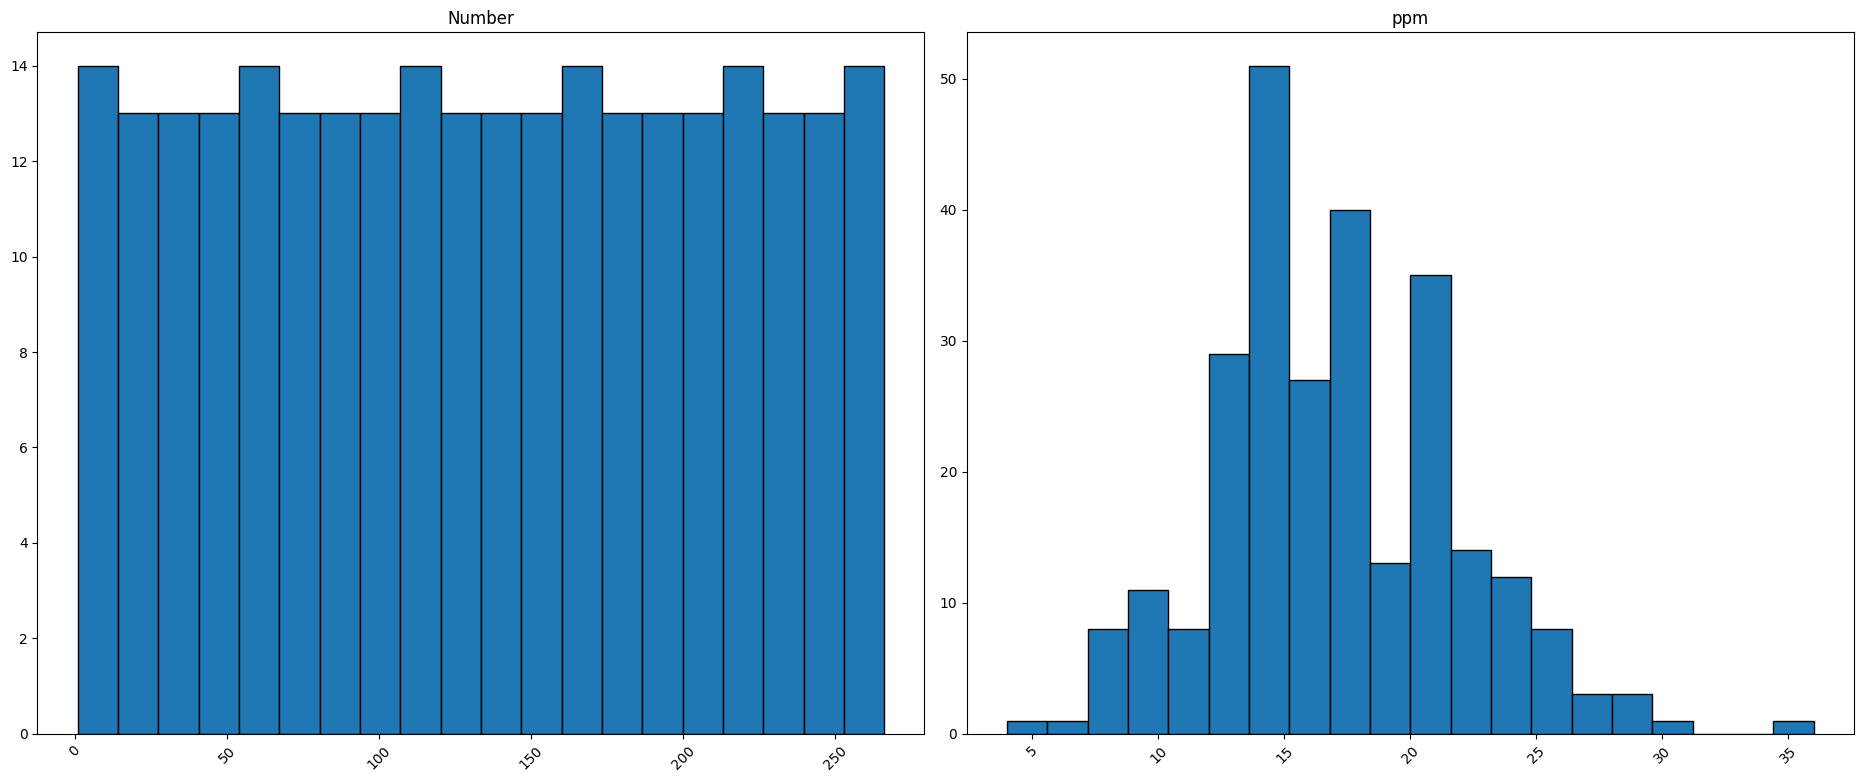

In [357]:
# ============================================
# GEOCHEMICAL DATA CLEANER - FULL APPLICATION
# ============================================

import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path
from PyQt5.QtWidgets import *
from PyQt5.QtCore import *
from PyQt5.QtGui import *
import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import seaborn as sns

# ============================================
# MAIN APPLICATION WINDOW
# ============================================

class GeochemicalCleaner(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.init_ui()
        
    def init_ui(self):
        """Initialize the user interface"""
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro")
        self.setGeometry(100, 100, 1200, 800)
        
        # Set application icon
        self.setWindowIcon(self.create_icon())
        
        # Create central widget
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        
        # Create main layout
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        # Create toolbar
        self.create_toolbar()
        
        # Create status bar
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("Ready")
        
        # Create tab widget
        self.tabs = QTabWidget()
        main_layout.addWidget(self.tabs)
        
        # Create tabs
        self.create_data_tab()
        self.create_stats_tab()
        self.create_plots_tab()
        self.create_export_tab()
        
        # Apply stylesheet
        self.apply_styles()
        
    def create_icon(self):
        """Create application icon"""
        # Create a simple geochemical icon (flask + data)
        pixmap = QPixmap(64, 64)
        pixmap.fill(Qt.transparent)
        
        painter = QPainter(pixmap)
        painter.setRenderHint(QPainter.Antialiasing)
        
        # Draw flask
        painter.setBrush(QBrush(QColor(0, 120, 200)))
        painter.setPen(QPen(Qt.black, 2))
        painter.drawEllipse(10, 10, 44, 44)
        
        # Draw data points
        painter.setBrush(QBrush(QColor(255, 200, 0)))
        painter.drawEllipse(25, 20, 6, 6)
        painter.drawEllipse(35, 30, 6, 6)
        painter.drawEllipse(20, 40, 6, 6)
        
        painter.end()
        return QIcon(pixmap)
        
    def create_toolbar(self):
        """Create the toolbar"""
        toolbar = self.addToolBar("Main")
        toolbar.setMovable(False)
        
        # Upload button
        upload_action = QAction(QIcon(), "📁 Upload", self)
        upload_action.setShortcut("Ctrl+O")
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        toolbar.addSeparator()
        
        # Clean button
        clean_action = QAction(QIcon(), "🧹 Clean", self)
        clean_action.setShortcut("Ctrl+C")
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        toolbar.addSeparator()
        
        # Export buttons
        export_csv = QAction(QIcon(), "💾 Export CSV", self)
        export_csv.triggered.connect(lambda: self.export_data('csv'))
        toolbar.addAction(export_csv)
        
        export_excel = QAction(QIcon(), "📊 Export Excel", self)
        export_excel.triggered.connect(lambda: self.export_data('excel'))
        toolbar.addAction(export_excel)
        
        toolbar.addSeparator()
        
        # Reset button
        reset_action = QAction(QIcon(), "🔄 Reset", self)
        reset_action.triggered.connect(self.reset_all)
        toolbar.addAction(reset_action)
        
    def create_data_tab(self):
        """Create data viewing tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        # Info label
        self.info_label = QLabel("No data loaded. Click 'Upload' to begin.")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 10px;")
        layout.addWidget(self.info_label)
        
        # Data table
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        layout.addWidget(self.table)
        
        # Summary stats
        self.stats_label = QLabel("")
        self.stats_label.setStyleSheet("padding: 10px; background-color: #f0f0f0; border-radius: 5px;")
        layout.addWidget(self.stats_label)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📊 Data")
        
    def create_stats_tab(self):
        """Create statistics tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        # Statistics text
        self.stats_text = QTextEdit()
        self.stats_text.setReadOnly(True)
        self.stats_text.setFont(QFont("Courier", 10))
        layout.addWidget(self.stats_text)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📈 Statistics")
        
    def create_plots_tab(self):
        """Create plotting tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        # Matplotlib figure
        self.figure = plt.figure(figsize=(10, 6))
        self.canvas = FigureCanvas(self.figure)
        layout.addWidget(self.canvas)
        
        # Controls
        controls = QHBoxLayout()
        
        self.plot_type = QComboBox()
        self.plot_type.addItems(["Correlation Matrix", "Histograms", "Box Plots", "Scatter Plot"])
        controls.addWidget(QLabel("Plot Type:"))
        controls.addWidget(self.plot_type)
        
        self.x_col = QComboBox()
        controls.addWidget(QLabel("X:"))
        controls.addWidget(self.x_col)
        
        self.y_col = QComboBox()
        controls.addWidget(QLabel("Y:"))
        controls.addWidget(self.y_col)
        
        plot_btn = QPushButton("Generate Plot")
        plot_btn.clicked.connect(self.generate_plot)
        controls.addWidget(plot_btn)
        
        layout.addLayout(controls)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📉 Plots")
        
    def create_export_tab(self):
        """Create export tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        # Export options
        options_group = QGroupBox("Export Options")
        options_layout = QGridLayout()
        
        # File format
        options_layout.addWidget(QLabel("Format:"), 0, 0)
        self.export_format = QComboBox()
        self.export_format.addItems(["CSV (;)", "CSV (,)", "Excel", "JSON", "Parquet"])
        options_layout.addWidget(self.export_format, 0, 1)
        
        # Include statistics
        self.include_stats = QCheckBox("Include statistics")
        self.include_stats.setChecked(True)
        options_layout.addWidget(self.include_stats, 1, 0, 1, 2)
        
        # Handle missing values
        options_layout.addWidget(QLabel("Handle Missing:"), 2, 0)
        self.missing_handling = QComboBox()
        self.missing_handling.addItems(["Keep as NaN", "Fill with Mean", "Fill with Median", "Drop Rows"])
        options_layout.addWidget(self.missing_handling, 2, 1)
        
        options_group.setLayout(options_layout)
        layout.addWidget(options_group)
        
        # Export button
        export_btn = QPushButton("🚀 Export Data")
        export_btn.clicked.connect(lambda: self.export_data('custom'))
        export_btn.setStyleSheet("""
            QPushButton {
                background-color: #4CAF50;
                color: white;
                font-size: 16px;
                padding: 10px;
                border-radius: 5px;
            }
            QPushButton:hover {
                background-color: #45a049;
            }
        """)
        layout.addWidget(export_btn)
        
        # Progress bar
        self.progress = QProgressBar()
        layout.addWidget(self.progress)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "💾 Export")
        
    def apply_styles(self):
        """Apply custom stylesheet"""
        self.setStyleSheet("""
            QMainWindow {
                background-color: #f5f5f5;
            }
            QTableWidget {
                background-color: white;
                gridline-color: #d0d0d0;
            }
            QTableWidget::item {
                padding: 5px;
            }
            QTableWidget::item:selected {
                background-color: #4CAF50;
                color: white;
            }
            QHeaderView::section {
                background-color: #e0e0e0;
                padding: 5px;
                border: 1px solid #d0d0d0;
            }
            QPushButton {
                background-color: #2196F3;
                color: white;
                padding: 8px 15px;
                border-radius: 4px;
                border: none;
            }
            QPushButton:hover {
                background-color: #1976D2;
            }
            QTabWidget::pane {
                border: 1px solid #d0d0d0;
                border-radius: 4px;
            }
            QTabBar::tab {
                padding: 8px 15px;
                background-color: #e0e0e0;
                border: 1px solid #d0d0d0;
                border-bottom: none;
                border-top-left-radius: 4px;
                border-top-right-radius: 4px;
            }
            QTabBar::tab:selected {
                background-color: white;
            }
        """)
        
    def upload_file(self):
        """Upload data file"""
        file_path, _ = QFileDialog.getOpenFileName(
            self,
            "Open Geochemical Data",
            "",
            "All Files (*);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;Text Files (*.txt)"
        )
        
        if file_path:
            self.current_file = file_path
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            
            try:
                # Use your universal cleaner
                self.df = clean_any_data(file_path)
                
                if self.df is not None and not self.df.empty:
                    self.display_data()
                    self.update_stats()
                    self.statusBar.showMessage(f"Loaded: {os.path.basename(file_path)} - {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                else:
                    QMessageBox.warning(self, "Error", "No data could be read from the file.")
                    
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
                self.statusBar.showMessage("Error loading file")
                
    def clean_data(self):
        """Clean the loaded data"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
            
        self.statusBar.showMessage("Cleaning data...")
        
        try:
            # Apply additional cleaning if needed
            self.cleaned_df = self.df.copy()
            
            # Show results
            self.display_data(self.cleaned_df)
            self.update_stats(self.cleaned_df)
            
            self.statusBar.showMessage(f"Data cleaned! {self.cleaned_df.shape[0]} rows, {self.cleaned_df.shape[1]} columns")
            QMessageBox.information(self, "Success", "Data cleaning completed successfully!")
            
        except Exception as e:
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
            self.statusBar.showMessage("Error cleaning data")
            
    def display_data(self, df=None):
        """Display data in table"""
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
                
        self.table.setRowCount(min(len(df), 1000))  # Limit display
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns)
        
        # Fill data
        for i in range(min(len(df), 1000)):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    self.table.setItem(i, j, QTableWidgetItem(""))
                else:
                    self.table.setItem(i, j, QTableWidgetItem(str(val)))
                    
        # Resize columns
        self.table.resizeColumnsToContents()
        
        # Update info label
        self.info_label.setText(f"📊 Data: {df.shape[0]} rows × {df.shape[1]} columns")
        
        # Update column dropdowns for plots
        self.x_col.clear()
        self.y_col.clear()
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        self.x_col.addItems(numeric_cols)
        self.y_col.addItems(numeric_cols)
        
    def update_stats(self, df=None):
        """Update statistics display"""
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
                
        stats = []
        stats.append("=" * 80)
        stats.append("DATA SUMMARY")
        stats.append("=" * 80)
        stats.append(f"Total Rows: {df.shape[0]}")
        stats.append(f"Total Columns: {df.shape[1]}")
        stats.append("")
        
        # Column info
        stats.append("COLUMN INFORMATION:")
        stats.append("-" * 40)
        for col in df.columns:
            dtype = df[col].dtype
            missing = df[col].isnull().sum()
            unique = df[col].nunique()
            stats.append(f"  {col:<20} {str(dtype):<15} Missing: {missing:>4}  Unique: {unique:>4}")
        
        stats.append("")
        stats.append("NUMERIC STATISTICS:")
        stats.append("-" * 40)
        
        numeric_cols = df.select_dtypes(include=[np.number]).columns
        if len(numeric_cols) > 0:
            stats.append(df[numeric_cols].describe().to_string())
        else:
            stats.append("No numeric columns found.")
            
        self.stats_text.setText("\n".join(stats))
        
    def generate_plot(self):
        """Generate selected plot"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
            
        self.figure.clear()
        plot_type = self.plot_type.currentText()
        
        if plot_type == "Correlation Matrix":
            self.plot_correlation()
        elif plot_type == "Histograms":
            self.plot_histograms()
        elif plot_type == "Box Plots":
            self.plot_boxplots()
        elif plot_type == "Scatter Plot":
            self.plot_scatter()
            
        self.canvas.draw()
        
    def plot_correlation(self):
        """Plot correlation matrix"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] < 2:
            QMessageBox.warning(self, "Warning", "Need at least 2 numeric columns")
            return
            
        corr = numeric_df.corr()
        ax = self.figure.add_subplot(111)
        sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, ax=ax)
        ax.set_title("Correlation Matrix")
        
    def plot_histograms(self):
        """Plot histograms"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] == 0:
            QMessageBox.warning(self, "Warning", "No numeric columns found")
            return
            
        n_cols = min(4, numeric_df.shape[1])
        n_rows = (numeric_df.shape[1] + n_cols - 1) // n_cols
        
        for i, col in enumerate(numeric_df.columns[:n_cols * n_rows]):
            ax = self.figure.add_subplot(n_rows, n_cols, i + 1)
            ax.hist(numeric_df[col].dropna(), bins=20, edgecolor='black')
            ax.set_title(col)
            ax.tick_params(axis='x', rotation=45)
            
        self.figure.tight_layout()
        
    def plot_boxplots(self):
        """Plot box plots"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] == 0:
            QMessageBox.warning(self, "Warning", "No numeric columns found")
            return
            
        ax = self.figure.add_subplot(111)
        numeric_df.boxplot(ax=ax, rot=45)
        ax.set_title("Box Plots")
        
    def plot_scatter(self):
        """Plot scatter plot"""
        x_col = self.x_col.currentText()
        y_col = self.y_col.currentText()
        
        if not x_col or not y_col:
            QMessageBox.warning(self, "Warning", "Please select X and Y columns")
            return
            
        ax = self.figure.add_subplot(111)
        ax.scatter(self.df[x_col], self.df[y_col], alpha=0.5)
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{x_col} vs {y_col}")
        
    def export_data(self, format_type):
        """Export cleaned data"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
            
        df_to_export = self.cleaned_df if self.cleaned_df is not None else self.df
        
        # Apply missing value handling
        handling = self.missing_handling.currentText()
        if handling == "Fill with Mean":
            df_to_export = df_to_export.fillna(df_to_export.mean())
        elif handling == "Fill with Median":
            df_to_export = df_to_export.fillna(df_to_export.median())
        elif handling == "Drop Rows":
            df_to_export = df_to_export.dropna()
            
        # Save dialog
        if format_type == 'custom':
            format_type = self.export_format.currentText().lower()
            
        if format_type in ['csv (;)', 'csv (,)']:
            sep = ';' if ';' in format_type else ','
            file_path, _ = QFileDialog.getSaveFileName(
                self,
                "Save CSV",
                "cleaned_data.csv",
                "CSV Files (*.csv)"
            )
            if file_path:
                df_to_export.to_csv(file_path, sep=sep, index=False, encoding='utf-8-sig')
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
        elif format_type == 'excel':
            file_path, _ = QFileDialog.getSaveFileName(
                self,
                "Save Excel",
                "cleaned_data.xlsx",
                "Excel Files (*.xlsx)"
            )
            if file_path:
                df_to_export.to_excel(file_path, index=False)
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
        elif format_type == 'json':
            file_path, _ = QFileDialog.getSaveFileName(
                self,
                "Save JSON",
                "cleaned_data.json",
                "JSON Files (*.json)"
            )
            if file_path:
                df_to_export.to_json(file_path, orient='records', indent=2)
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
    def reset_all(self):
        """Reset everything"""
        self.df = None
        self.cleaned_df = None
        self.table.clear()
        self.table.setRowCount(0)
        self.table.setColumnCount(0)
        self.stats_text.clear()
        self.figure.clear()
        self.canvas.draw()
        self.info_label.setText("No data loaded. Click 'Upload' to begin.")
        self.statusBar.showMessage("Reset complete")
        
    def closeEvent(self, event):
        """Handle close event"""
        reply = QMessageBox.question(
            self,
            "Exit",
            "Are you sure you want to exit?",
            QMessageBox.Yes | QMessageBox.No,
            QMessageBox.No
        )
        if reply == QMessageBox.Yes:
            event.accept()
        else:
            event.ignore()


# ============================================
# MAIN APPLICATION
# ============================================

def main():
    app = QApplication(sys.argv)
    app.setStyle('Fusion')
    
    # Set application-wide font
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    sys.exit(app.exec_())


if __name__ == '__main__':
    main()

In [ ]:
# setup.py
from setuptools import setup

setup(
    name="GeochemicalCleaner",
    version="1.0.0",
    description="Geochemical Data Cleaning Software",
    author="Your Company",
    packages=['geochemical_cleaner'],
    install_requires=[
        'pandas>=1.3.0',
        'numpy>=1.21.0',
        'PyQt5>=5.15.0',
        'matplotlib>=3.4.0',
        'seaborn>=0.11.0',
        'openpyxl>=3.0.0',
        'xlsxwriter>=1.4.0',
    ],
    entry_points={
        'console_scripts': [
            'geochemical-cleaner=geochemical_cleaner.main:main',
        ],
    },
)

In [ ]:
## power shell code 
# Install PyInstaller
pip install pyinstaller

# Create standalone executable
pyinstaller --onefile --windowed --icon=icon.ico --name="GeochemicalCleaner" main.py

# With additional dependencies
pyinstaller --onefile --windowed --icon=icon.ico --add-data "icon.ico;." --hidden-import=openpyxl --hidden-import=xlsxwriter main.py

In [360]:
# ============================================
# GEOCHEMICAL DATA CLEANER - JUPYTER COMPATIBLE
# ============================================

import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

import matplotlib.pyplot as plt
from matplotlib.backends.backend_qt5agg import FigureCanvasQTAgg as FigureCanvas
import seaborn as sns

# ============================================
# DATA CLEANING FUNCTIONS
# ============================================

def manual_parse_text_file(path):
    """Manually parse text files when auto-detection fails"""
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        with open(path, 'r', encoding='utf-8') as f:
            lines = f.readlines()
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return pd.DataFrame()
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        
        df = pd.DataFrame(data)
        
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    
    return pd.DataFrame()

def split_single_column(df):
    """Split single-column dataframes"""
    if df.shape[1] == 1:
        col_name = df.columns[0]
        col_data = df[col_name].astype(str)
        sample = col_data.iloc[0] if len(col_data) > 0 else ''
        delimiters = [';', ',', '\t', '|']
        
        for delim in delimiters:
            if delim in sample:
                split_data = col_data.str.split(delim, expand=True)
                try:
                    pd.to_numeric(split_data.iloc[0, 0])
                    split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
                except:
                    headers = split_data.iloc[0].tolist()
                    split_data = split_data.iloc[1:].copy()
                    headers = [str(h).strip() for h in headers]
                    split_data.columns = headers
                return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    """Clean column names"""
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$')]
    df.columns = [f'col_{i}' if str(col).strip() == '' else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', str(col)).strip('_') for col in df.columns]
    
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    """Remove rows that look like headers"""
    if len(df) > 0:
        first_row = df.iloc[0].astype(str)
        header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 
                          'value', 'measurement', 'parameter', 'unit']
        header_score = 0
        for val in first_row:
            if any(keyword in str(val).lower() for keyword in header_keywords):
                header_score += 1
        
        if header_score / len(first_row) > 0.3:
            df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    """Standardize missing values"""
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 
                     'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    
    for col in df.columns:
        df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
        df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    """Clean numeric columns"""
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 
                 'lithology', 'description', 'comment', 'remarks',
                 'unit', 'method', 'date', 'time']
    
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    """Clean text columns"""
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    """Remove empty rows and columns"""
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

def clean_any_data(path, sheet_name=None, **kwargs):
    """Universal data cleaner"""
    print(f"\n📁 READING FILE: {os.path.basename(path)}")
    
    file_ext = Path(path).suffix.lower()
    df = None
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
            print("✅ Read as Excel file")
        except:
            try:
                df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
                print("✅ Read as Excel file (xlrd engine)")
            except:
                pass
    
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        delimiters = [';', ',', '\t', '|', ' ']
        for encoding in encodings:
            for delim in delimiters:
                try:
                    df = pd.read_csv(
                        path, sep=delim, encoding=encoding,
                        engine='python', on_bad_lines='skip', **kwargs
                    )
                    if df.shape[1] > 1 or df.shape[0] > 0:
                        print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                        break
                except:
                    continue
            if df is not None and df.shape[1] > 1:
                break
        
        if df is None:
            print("⚠️ Auto-detection failed, trying manual parsing...")
            df = manual_parse_text_file(path)
    else:
        print(f"⚠️ Unknown file type: {file_ext}, trying to read as text...")
        try:
            df = manual_parse_text_file(path)
        except:
            raise ValueError(f"Cannot read file: {path}")
    
    if df is None or df.empty:
        raise ValueError(f"Could not read data from: {path}")
    
    print(f"📊 Raw data shape: {df.shape}")
    
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    
    print(f"✅ Final shape: {df.shape}")
    return df

# ============================================
# MAIN APPLICATION WINDOW
# ============================================

class GeochemicalCleaner(QMainWindow):
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.init_ui()
        
    def init_ui(self):
        """Initialize the user interface"""
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro")
        self.setGeometry(100, 100, 1200, 800)
        
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        self.create_toolbar()
        
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("Ready")
        
        self.tabs = QTabWidget()
        main_layout.addWidget(self.tabs)
        
        self.create_data_tab()
        self.create_stats_tab()
        self.create_plots_tab()
        self.create_export_tab()
        
        self.apply_styles()
        
    def create_toolbar(self):
        """Create the toolbar"""
        toolbar = self.addToolBar("Main")
        toolbar.setMovable(False)
        
        upload_action = QAction("📁 Upload", self)
        upload_action.setShortcut("Ctrl+O")
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        toolbar.addSeparator()
        
        clean_action = QAction("🧹 Clean", self)
        clean_action.setShortcut("Ctrl+C")
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        toolbar.addSeparator()
        
        export_csv = QAction("💾 Export CSV", self)
        export_csv.triggered.connect(lambda: self.export_data('csv'))
        toolbar.addAction(export_csv)
        
        export_excel = QAction("📊 Export Excel", self)
        export_excel.triggered.connect(lambda: self.export_data('excel'))
        toolbar.addAction(export_excel)
        
        toolbar.addSeparator()
        
        reset_action = QAction("🔄 Reset", self)
        reset_action.triggered.connect(self.reset_all)
        toolbar.addAction(reset_action)
        
    def create_data_tab(self):
        """Create data viewing tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        self.info_label = QLabel("No data loaded. Click 'Upload' to begin.")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 10px;")
        layout.addWidget(self.info_label)
        
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        layout.addWidget(self.table)
        
        self.stats_label = QLabel("")
        self.stats_label.setStyleSheet("padding: 10px; background-color: #f0f0f0; border-radius: 5px;")
        layout.addWidget(self.stats_label)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📊 Data")
        
    def create_stats_tab(self):
        """Create statistics tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        self.stats_text = QTextEdit()
        self.stats_text.setReadOnly(True)
        self.stats_text.setFont(QFont("Courier", 10))
        layout.addWidget(self.stats_text)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📈 Statistics")
        
    def create_plots_tab(self):
        """Create plotting tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        self.figure = plt.figure(figsize=(10, 6))
        self.canvas = FigureCanvas(self.figure)
        layout.addWidget(self.canvas)
        
        controls = QHBoxLayout()
        
        self.plot_type = QComboBox()
        self.plot_type.addItems(["Correlation Matrix", "Histograms", "Box Plots", "Scatter Plot"])
        controls.addWidget(QLabel("Plot Type:"))
        controls.addWidget(self.plot_type)
        
        self.x_col = QComboBox()
        controls.addWidget(QLabel("X:"))
        controls.addWidget(self.x_col)
        
        self.y_col = QComboBox()
        controls.addWidget(QLabel("Y:"))
        controls.addWidget(self.y_col)
        
        plot_btn = QPushButton("Generate Plot")
        plot_btn.clicked.connect(self.generate_plot)
        controls.addWidget(plot_btn)
        
        layout.addLayout(controls)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "📉 Plots")
        
    def create_export_tab(self):
        """Create export tab"""
        tab = QWidget()
        layout = QVBoxLayout()
        
        options_group = QGroupBox("Export Options")
        options_layout = QGridLayout()
        
        options_layout.addWidget(QLabel("Format:"), 0, 0)
        self.export_format = QComboBox()
        self.export_format.addItems(["CSV (;)", "CSV (,)", "Excel", "JSON"])
        options_layout.addWidget(self.export_format, 0, 1)
        
        self.include_stats = QCheckBox("Include statistics")
        self.include_stats.setChecked(True)
        options_layout.addWidget(self.include_stats, 1, 0, 1, 2)
        
        options_layout.addWidget(QLabel("Handle Missing:"), 2, 0)
        self.missing_handling = QComboBox()
        self.missing_handling.addItems(["Keep as NaN", "Fill with Mean", "Fill with Median", "Drop Rows"])
        options_layout.addWidget(self.missing_handling, 2, 1)
        
        options_group.setLayout(options_layout)
        layout.addWidget(options_group)
        
        export_btn = QPushButton("🚀 Export Data")
        export_btn.clicked.connect(lambda: self.export_data('custom'))
        export_btn.setStyleSheet("""
            QPushButton {
                background-color: #4CAF50;
                color: white;
                font-size: 16px;
                padding: 10px;
                border-radius: 5px;
            }
            QPushButton:hover {
                background-color: #45a049;
            }
        """)
        layout.addWidget(export_btn)
        
        self.progress = QProgressBar()
        layout.addWidget(self.progress)
        
        tab.setLayout(layout)
        self.tabs.addTab(tab, "💾 Export")
        
    def apply_styles(self):
        """Apply custom stylesheet"""
        self.setStyleSheet("""
            QMainWindow { background-color: #f5f5f5; }
            QTableWidget { background-color: white; gridline-color: #d0d0d0; }
            QTableWidget::item { padding: 5px; }
            QTableWidget::item:selected { background-color: #4CAF50; color: white; }
            QHeaderView::section { background-color: #e0e0e0; padding: 5px; border: 1px solid #d0d0d0; }
            QPushButton { background-color: #2196F3; color: white; padding: 8px 15px; border-radius: 4px; border: none; }
            QPushButton:hover { background-color: #1976D2; }
        """)
        
    def upload_file(self):
        """Upload data file"""
        file_path, _ = QFileDialog.getOpenFileName(
            self,
            "Open Geochemical Data",
            "",
            "All Files (*);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;Text Files (*.txt)"
        )
        
        if file_path:
            self.current_file = file_path
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            
            try:
                self.df = clean_any_data(file_path)
                
                if self.df is not None and not self.df.empty:
                    self.display_data()
                    self.update_stats()
                    self.statusBar.showMessage(f"Loaded: {os.path.basename(file_path)} - {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                else:
                    QMessageBox.warning(self, "Error", "No data could be read from the file.")
                    
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
                self.statusBar.showMessage("Error loading file")
                
    def clean_data(self):
        """Clean the loaded data"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
            
        self.statusBar.showMessage("Cleaning data...")
        
        try:
            self.cleaned_df = self.df.copy()
            self.display_data(self.cleaned_df)
            self.update_stats(self.cleaned_df)
            self.statusBar.showMessage(f"Data cleaned! {self.cleaned_df.shape[0]} rows, {self.cleaned_df.shape[1]} columns")
            QMessageBox.information(self, "Success", "Data cleaning completed successfully!")
            
        except Exception as e:
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
            self.statusBar.showMessage("Error cleaning data")
            
    def display_data(self, df=None):
        """Display data in table"""
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
                
        self.table.setRowCount(min(len(df), 1000))
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns)
        
        for i in range(min(len(df), 1000)):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    self.table.setItem(i, j, QTableWidgetItem(""))
                else:
                    self.table.setItem(i, j, QTableWidgetItem(str(val)))
                    
        self.table.resizeColumnsToContents()
        self.info_label.setText(f"📊 Data: {df.shape[0]} rows × {df.shape[1]} columns")
        
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        self.x_col.clear()
        self.y_col.clear()
        self.x_col.addItems(numeric_cols)
        self.y_col.addItems(numeric_cols)
        
    def update_stats(self, df=None):
        """Update statistics display"""
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
                
        stats = []
        stats.append("=" * 80)
        stats.append("DATA SUMMARY")
        stats.append("=" * 80)
        stats.append(f"Total Rows: {df.shape[0]}")
        stats.append(f"Total Columns: {df.shape[1]}")
        stats.append("")
        
        stats.append("COLUMN INFORMATION:")
        stats.append("-" * 40)
        for col in df.columns:
            dtype = df[col].dtype
            missing = df[col].isnull().sum()
            unique = df[col].nunique()
            stats.append(f"  {col:<20} {str(dtype):<15} Missing: {missing:>4}  Unique: {unique:>4}")
        
        stats.append("")
        stats.append("NUMERIC STATISTICS:")
        stats.append("-" * 40)
        
        numeric_cols = df.select_dtypes(include=[np.number]).columns
        if len(numeric_cols) > 0:
            stats.append(df[numeric_cols].describe().to_string())
        else:
            stats.append("No numeric columns found.")
            
        self.stats_text.setText("\n".join(stats))
        
    def generate_plot(self):
        """Generate selected plot"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
            
        self.figure.clear()
        plot_type = self.plot_type.currentText()
        
        if plot_type == "Correlation Matrix":
            self.plot_correlation()
        elif plot_type == "Histograms":
            self.plot_histograms()
        elif plot_type == "Box Plots":
            self.plot_boxplots()
        elif plot_type == "Scatter Plot":
            self.plot_scatter()
            
        self.canvas.draw()
        
    def plot_correlation(self):
        """Plot correlation matrix"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] < 2:
            QMessageBox.warning(self, "Warning", "Need at least 2 numeric columns")
            return
            
        corr = numeric_df.corr()
        ax = self.figure.add_subplot(111)
        sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, ax=ax)
        ax.set_title("Correlation Matrix")
        
    def plot_histograms(self):
        """Plot histograms"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] == 0:
            QMessageBox.warning(self, "Warning", "No numeric columns found")
            return
            
        n_cols = min(4, numeric_df.shape[1])
        n_rows = (numeric_df.shape[1] + n_cols - 1) // n_cols
        
        for i, col in enumerate(numeric_df.columns[:n_cols * n_rows]):
            ax = self.figure.add_subplot(n_rows, n_cols, i + 1)
            ax.hist(numeric_df[col].dropna(), bins=20, edgecolor='black')
            ax.set_title(col)
            ax.tick_params(axis='x', rotation=45)
            
        self.figure.tight_layout()
        
    def plot_boxplots(self):
        """Plot box plots"""
        numeric_df = self.df.select_dtypes(include=[np.number])
        if numeric_df.shape[1] == 0:
            QMessageBox.warning(self, "Warning", "No numeric columns found")
            return
            
        ax = self.figure.add_subplot(111)
        numeric_df.boxplot(ax=ax, rot=45)
        ax.set_title("Box Plots")
        
    def plot_scatter(self):
        """Plot scatter plot"""
        x_col = self.x_col.currentText()
        y_col = self.y_col.currentText()
        
        if not x_col or not y_col:
            QMessageBox.warning(self, "Warning", "Please select X and Y columns")
            return
            
        ax = self.figure.add_subplot(111)
        ax.scatter(self.df[x_col], self.df[y_col], alpha=0.5)
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{x_col} vs {y_col}")
        
    def export_data(self, format_type):
        """Export cleaned data"""
        if self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
            
        df_to_export = self.cleaned_df if self.cleaned_df is not None else self.df
        
        handling = self.missing_handling.currentText()
        if handling == "Fill with Mean":
            df_to_export = df_to_export.fillna(df_to_export.mean())
        elif handling == "Fill with Median":
            df_to_export = df_to_export.fillna(df_to_export.median())
        elif handling == "Drop Rows":
            df_to_export = df_to_export.dropna()
            
        if format_type == 'custom':
            format_type = self.export_format.currentText().lower()
            
        if format_type in ['csv (;)', 'csv (,)']:
            sep = ';' if ';' in format_type else ','
            file_path, _ = QFileDialog.getSaveFileName(
                self, "Save CSV", "cleaned_data.csv", "CSV Files (*.csv)"
            )
            if file_path:
                df_to_export.to_csv(file_path, sep=sep, index=False, encoding='utf-8-sig')
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
        elif format_type == 'excel':
            file_path, _ = QFileDialog.getSaveFileName(
                self, "Save Excel", "cleaned_data.xlsx", "Excel Files (*.xlsx)"
            )
            if file_path:
                df_to_export.to_excel(file_path, index=False)
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
        elif format_type == 'json':
            file_path, _ = QFileDialog.getSaveFileName(
                self, "Save JSON", "cleaned_data.json", "JSON Files (*.json)"
            )
            if file_path:
                df_to_export.to_json(file_path, orient='records', indent=2)
                QMessageBox.information(self, "Success", f"Data exported to {file_path}")
                
    def reset_all(self):
        """Reset everything"""
        self.df = None
        self.cleaned_df = None
        self.table.clear()
        self.table.setRowCount(0)
        self.table.setColumnCount(0)
        self.stats_text.clear()
        self.figure.clear()
        self.canvas.draw()
        self.info_label.setText("No data loaded. Click 'Upload' to begin.")
        self.statusBar.showMessage("Reset complete")
        
    def closeEvent(self, event):
        """Handle close event"""
        reply = QMessageBox.question(
            self,
            "Exit",
            "Are you sure you want to exit?",
            QMessageBox.Yes | QMessageBox.No,
            QMessageBox.No
        )
        if reply == QMessageBox.Yes:
            event.accept()
        else:
            event.ignore()


# ============================================
# MAIN APPLICATION LAUNCHER
# ============================================

def launch_app():
    """Launch the geochemical cleaner application"""
    if QT_VERSION is None:
        print("❌ PyQt not installed. Please install with: pip install PyQt5")
        return
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle('Fusion')
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    # Return app and window for Jupyter compatibility
    return app, window


def main():
    """Main entry point for standalone application"""
    app, window = launch_app()
    
    # Only call exec_ if not in Jupyter
    if not IN_JUPYTER:
        sys.exit(app.exec_())
    else:
        # In Jupyter, just return the app and window
        return app, window


# ============================================
# ENTRY POINT
# ============================================

if __name__ == '__main__':
    main()

<Figure size 1000x600 with 0 Axes>

In [362]:
# In Jupyter cell
%run -i geochemical_cleaner.py
# Or
from geochemical_cleaner import launch_app
app, window = launch_app()

Exception: File `'geochemical_cleaner.py'` not found.

In [364]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# PART 1: UNIVERSAL DATA CLEANING ENGINE
# ============================================================

def clean_any_data(path, sheet_name=None, **kwargs):
    """
    Universal data cleaner that handles any file format and structure.
    This is the ENGINE that does all the heavy lifting.
    """
    print(f"\n📁 READING FILE: {os.path.basename(path)}")
    print("=" * 70)
    
    # STEP 1: Auto-detect file type and read
    file_ext = Path(path).suffix.lower()
    df = None
    
    # Try different encodings
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    # Excel files
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        df = read_excel_file(path, sheet_name)
        if df is None:
            return None
    
    # CSV and text files
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        df = read_text_file(path, encodings, **kwargs)
        if df is None or df.empty:
            df = manual_parse_text_file(path)
    
    # Unknown file types
    else:
        print(f"⚠️ Unknown file type: {file_ext}")
        df = manual_parse_text_file(path)
    
    if df is None or df.empty:
        print("❌ Could not read file")
        return None
    
    print(f"📊 Raw data shape: {df.shape}")
    print(f"📋 Raw columns: {df.columns.tolist()}")
    
    # STEP 2: Clean the data
    df = clean_dataframe(df)
    
    print(f"\n✅ Final shape: {df.shape}")
    return df


def read_excel_file(path, sheet_name):
    """Read Excel files with multiple engines"""
    try:
        df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
        print("✅ Read as Excel file (openpyxl)")
        return df
    except:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
            print("✅ Read as Excel file (xlrd)")
            return df
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            return None


def read_text_file(path, encodings, **kwargs):
    """Read text files with multiple encodings and delimiters"""
    delimiters = [';', ',', '\t', '|', ' ']
    
    for encoding in encodings:
        for delim in delimiters:
            try:
                df = pd.read_csv(
                    path, 
                    sep=delim, 
                    encoding=encoding,
                    engine='python',
                    on_bad_lines='skip',
                    **kwargs
                )
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except:
                continue
    return None


def manual_parse_text_file(path):
    """Manually parse text files when auto-detection fails"""
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    # Detect delimiter
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        
        df = pd.DataFrame(data)
        
        # Check if first row is header
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    
    return None


def clean_dataframe(df):
    """Clean the dataframe with all cleaning steps"""
    if df is None or df.empty:
        return df
    
    # 1. Handle single column data
    df = split_single_column(df)
    
    # 2. Clean column names
    df = clean_column_names(df)
    
    # 3. Remove header rows
    df = remove_header_rows(df)
    
    # 4. Standardize missing values
    df = standardize_missing_values(df)
    
    # 5. Clean numeric columns
    df = clean_numeric_columns(df)
    
    # 6. Clean text columns
    df = clean_text_columns(df)
    
    # 7. Remove empty rows and columns
    df = remove_empty(df)
    
    return df


def split_single_column(df):
    """Split single-column dataframes"""
    if df is None or df.empty or df.shape[1] != 1:
        return df
    
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    
    return df


def clean_column_names(df):
    """Clean column names"""
    if df is None or df.empty:
        return df
    
    # Strip whitespace
    df.columns = df.columns.str.strip()
    
    # Remove duplicates
    df = df.loc[:, ~df.columns.duplicated()]
    
    # Remove malformed column names
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    
    # Replace empty column names
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    
    # Clean column names (replace special characters with underscores)
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    
    # Make column names unique
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    
    return df


def remove_header_rows(df):
    """Remove rows that look like headers"""
    if df is None or df.empty or len(df) == 0:
        return df
    
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 
                      'value', 'measurement', 'parameter', 'unit', 'ppm']
    
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
        print(f"🔍 Removed header row (detected {header_score} header-like values)")
    
    return df


def standardize_missing_values(df):
    """Standardize all missing value representations"""
    if df is None or df.empty:
        return df
    
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 
                     'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    
    # Replace detection limit values (<0.01, >50, etc.) with NaN
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    
    return df


def clean_numeric_columns(df):
    """Clean and convert numeric columns"""
    if df is None or df.empty:
        return df
    
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 
                 'lithology', 'description', 'comment', 'remarks',
                 'unit', 'method', 'date', 'time']
    
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        
        x = re.sub(r'[^\d.\-eE+]', '', x)
        
        try:
            return float(x)
        except:
            return np.nan
    
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    
    return df


def clean_text_columns(df):
    """Clean text columns"""
    if df is None or df.empty:
        return df
    
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    
    return df


def remove_empty(df):
    """Remove empty rows and columns"""
    if df is None or df.empty:
        return df
    
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    
    return df


# ============================================================
# PART 2: GUI APPLICATION
# ============================================================

class GeochemicalCleaner(QMainWindow):
    """
    Main application window for geochemical data cleaning.
    """
    
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.cleaning_log = []
        self.init_ui()
        
    def init_ui(self):
        """Initialize the user interface"""
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro v2.0")
        self.setGeometry(100, 100, 1200, 800)
        
        # Central widget
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        # ============================================================
        # TOOLBAR
        # ============================================================
        toolbar = self.addToolBar("Main")
        toolbar.setIconSize(QSize(32, 32))
        
        upload_action = QAction("📁 Upload Data", self)
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        clean_action = QAction("🧹 Clean Data", self)
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        export_action = QAction("💾 Export Data", self)
        export_action.triggered.connect(self.export_data)
        toolbar.addAction(export_action)
        
        toolbar.addSeparator()
        
        preview_action = QAction("👁️ Preview", self)
        preview_action.triggered.connect(self.show_preview)
        toolbar.addAction(preview_action)
        
        stats_action = QAction("📊 Statistics", self)
        stats_action.triggered.connect(self.show_statistics)
        toolbar.addAction(stats_action)
        
        # ============================================================
        # INFO LABEL
        # ============================================================
        self.info_label = QLabel("📋 No data loaded. Click 'Upload Data' to begin.")
        self.info_label.setStyleSheet("""
            font-size: 14px; 
            font-weight: bold; 
            padding: 15px; 
            background-color: #f0f0f0; 
            border-radius: 8px;
            border: 1px solid #d0d0d0;
        """)
        main_layout.addWidget(self.info_label)
        
        # ============================================================
        # TAB WIDGET
        # ============================================================
        self.tab_widget = QTabWidget()
        main_layout.addWidget(self.tab_widget)
        
        # Tab 1: Data Table
        self.table_tab = QWidget()
        self.tab_widget.addTab(self.table_tab, "📊 Data")
        table_layout = QVBoxLayout()
        self.table_tab.setLayout(table_layout)
        
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        table_layout.addWidget(self.table)
        
        # Tab 2: Log
        self.log_tab = QWidget()
        self.tab_widget.addTab(self.log_tab, "📝 Cleaning Log")
        log_layout = QVBoxLayout()
        self.log_tab.setLayout(log_layout)
        
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        log_layout.addWidget(self.log_text)
        
        # Tab 3: Column Info
        self.col_tab = QWidget()
        self.tab_widget.addTab(self.col_tab, "📋 Column Info")
        col_layout = QVBoxLayout()
        self.col_tab.setLayout(col_layout)
        
        self.col_table = QTableWidget()
        col_layout.addWidget(self.col_table)
        
        # ============================================================
        # STATUS BAR
        # ============================================================
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("✅ Ready")
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setVisible(False)
        self.statusBar.addPermanentWidget(self.progress)
        
        # ============================================================
        # APPLY STYLES
        # ============================================================
        self.setStyleSheet("""
            QMainWindow { background-color: #f5f5f5; }
            QTableWidget { 
                background-color: white; 
                gridline-color: #d0d0d0;
                alternate-background-color: #fafafa;
            }
            QTableWidget::item:selected { 
                background-color: #4CAF50; 
                color: white; 
            }
            QHeaderView::section { 
                background-color: #e0e0e0; 
                padding: 5px; 
                font-weight: bold;
            }
            QPushButton { 
                background-color: #2196F3; 
                color: white; 
                padding: 8px 15px; 
                border-radius: 4px; 
                border: none; 
            }
            QPushButton:hover { background-color: #1976D2; }
            QPushButton:pressed { background-color: #0D47A1; }
            QTabWidget::pane { border: 1px solid #d0d0d0; border-radius: 4px; }
            QTabBar::tab { 
                padding: 8px 15px; 
                margin-right: 2px;
                border-top-left-radius: 4px;
                border-top-right-radius: 4px;
            }
            QTabBar::tab:selected { 
                background-color: #2196F3; 
                color: white; 
            }
        """)
        
        # Log initial message
        self.add_log("🔬 Geochemical Data Cleaner Pro v2.0 initialized")
        self.add_log("📌 Ready to process geochemical data files")
    
    def add_log(self, message):
        """Add message to log"""
        from datetime import datetime
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}] {message}")
        self.cleaning_log.append(message)
    
    def upload_file(self):
        """Upload data file"""
        file_path, _ = QFileDialog.getOpenFileName(
            self,
            "Open Geochemical Data",
            "",
            "All Files (*);;CSV Files (*.csv);;Excel Files (*.xlsx *.xls);;Text Files (*.txt);;TSV Files (*.tsv)"
        )
        
        if file_path:
            self.current_file = file_path
            self.add_log(f"📁 Loading file: {os.path.basename(file_path)}")
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            self.progress.setVisible(True)
            self.progress.setRange(0, 0)
            
            try:
                # Use the universal cleaner
                self.df = clean_any_data(file_path)
                
                self.progress.setVisible(False)
                
                if self.df is not None and not self.df.empty:
                    self.cleaned_df = self.df.copy()
                    self.display_data()
                    self.update_column_info()
                    
                    self.add_log(f"✅ Successfully loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                    self.statusBar.showMessage(f"✅ Loaded: {os.path.basename(file_path)} - {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                    self.info_label.setText(f"📊 Data loaded: {self.df.shape[0]} rows × {self.df.shape[1]} columns")
                    
                    QMessageBox.information(self, "Success", 
                        f"File loaded successfully!\n\n"
                        f"📊 Shape: {self.df.shape[0]} rows × {self.df.shape[1]} columns\n"
                        f"📋 Columns: {', '.join(self.df.columns[:5])}...")
                else:
                    self.add_log("❌ Failed to read file")
                    QMessageBox.warning(self, "Error", "No data could be read from the file.")
                    self.statusBar.showMessage("❌ Error loading file")
                    
            except Exception as e:
                self.progress.setVisible(False)
                self.add_log(f"❌ Error loading file: {str(e)}")
                QMessageBox.critical(self, "Error", f"Failed to load file:\n{str(e)}")
                self.statusBar.showMessage("❌ Error loading file")
                import traceback
                traceback.print_exc()
    
    def clean_data(self):
        """Clean the loaded data"""
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
        
        self.add_log("🧹 Starting data cleaning...")
        self.statusBar.showMessage("Cleaning data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            # Clean the data
            self.cleaned_df = clean_dataframe(self.df.copy())
            
            self.progress.setVisible(False)
            
            self.display_data(self.cleaned_df)
            self.update_column_info()
            
            rows_before = len(self.df)
            rows_after = len(self.cleaned_df)
            rows_removed = rows_before - rows_after
            
            self.add_log(f"✅ Cleaning complete: {rows_after} rows, {self.cleaned_df.shape[1]} columns")
            self.add_log(f"🗑️ Removed {rows_removed} rows with invalid data")
            self.statusBar.showMessage(f"✅ Data cleaned! {rows_after} rows, {self.cleaned_df.shape[1]} columns")
            self.info_label.setText(f"🧹 Cleaned: {rows_after} rows × {self.cleaned_df.shape[1]} columns (removed {rows_removed} rows)")
            
            QMessageBox.information(self, "Success", 
                f"Data cleaning completed!\n\n"
                f"📊 Before: {rows_before} rows × {self.df.shape[1]} columns\n"
                f"📊 After: {rows_after} rows × {self.cleaned_df.shape[1]} columns\n"
                f"🗑️ Removed: {rows_removed} rows")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Cleaning error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
            self.statusBar.showMessage("❌ Error cleaning data")
            import traceback
            traceback.print_exc()
    
    def display_data(self, df=None):
        """Display data in table"""
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
        
        # Limit display to 1000 rows for performance
        display_limit = min(1000, len(df))
        
        self.table.setRowCount(display_limit)
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns.astype(str))
        
        # Fill data
        for i in range(display_limit):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    item = QTableWidgetItem("")
                else:
                    item = QTableWidgetItem(str(val))
                self.table.setItem(i, j, item)
        
        # Resize columns
        self.table.resizeColumnsToContents()
        
        # Show row count in status
        if len(df) > 1000:
            self.statusBar.showMessage(f"Showing first 1000 of {len(df)} rows")
    
    def update_column_info(self):
        """Update column information tab"""
        if self.cleaned_df is None and self.df is None:
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        self.col_table.setRowCount(len(df.columns))
        self.col_table.setColumnCount(6)
        self.col_table.setHorizontalHeaderLabels([
            "Column", "Type", "Non-Null", "Null %", "Unique", "Sample Values"
        ])
        
        for i, col in enumerate(df.columns):
            self.col_table.setItem(i, 0, QTableWidgetItem(str(col)))
            self.col_table.setItem(i, 1, QTableWidgetItem(str(df[col].dtype)))
            
            non_null = df[col].count()
            null_pct = (1 - non_null / len(df)) * 100
            self.col_table.setItem(i, 2, QTableWidgetItem(str(non_null)))
            self.col_table.setItem(i, 3, QTableWidgetItem(f"{null_pct:.1f}%"))
            
            unique = df[col].nunique()
            self.col_table.setItem(i, 4, QTableWidgetItem(str(unique)))
            
            if non_null > 0:
                sample = str(df[col].dropna().iloc[0]) if len(df[col].dropna()) > 0 else ""
                self.col_table.setItem(i, 5, QTableWidgetItem(sample[:50]))
            else:
                self.col_table.setItem(i, 5, QTableWidgetItem(""))
        
        self.col_table.resizeColumnsToContents()
    
    def show_preview(self):
        """Show data preview dialog"""
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data loaded!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        preview_text = f"📊 DATA PREVIEW\n{'='*50}\n\n"
        preview_text += f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n"
        preview_text += f"Columns: {', '.join(df.columns.tolist())}\n\n"
        preview_text += f"First 10 rows:\n"
        preview_text += df.head(10).to_string()
        preview_text += f"\n\nLast 10 rows:\n"
        preview_text += df.tail(10).to_string()
        
        dialog = QDialog(self)
        dialog.setWindowTitle("Data Preview")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 9))
        text_edit.setText(preview_text)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def show_statistics(self):
        """Show statistics dialog"""
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data loaded!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        stats_text = f"📊 DATA STATISTICS\n{'='*50}\n\n"
        stats_text += f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n\n"
        
        # Numeric columns summary
        numeric_cols = df.select_dtypes(include=[np.number]).columns
        if len(numeric_cols) > 0:
            stats_text += f"Numerical Statistics:\n"
            stats_text += df[numeric_cols].describe().to_string()
            stats_text += f"\n\n"
        
        # Missing values
        missing = df.isnull().sum()
        if missing.sum() > 0:
            stats_text += f"Missing Values:\n"
            stats_text += missing[missing > 0].to_string()
        else:
            stats_text += "✅ No missing values found!"
        
        dialog = QDialog(self)
        dialog.setWindowTitle("Data Statistics")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 9))
        text_edit.setText(stats_text)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def export_data(self):
        """Export cleaned data"""
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        # Ask for file location
        file_path, selected_filter = QFileDialog.getSaveFileName(
            self,
            "Save Cleaned Data",
            "cleaned_geochemical_data.csv",
            "CSV Files (*.csv);;Excel Files (*.xlsx);;All Files (*)"
        )
        
        if file_path:
            self.add_log(f"💾 Exporting data to: {os.path.basename(file_path)}")
            self.statusBar.showMessage(f"Exporting...")
            self.progress.setVisible(True)
            self.progress.setRange(0, 0)
            
            try:
                if file_path.endswith('.csv'):
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif file_path.endswith('.xlsx'):
                    df.to_excel(file_path, index=False)
                else:
                    df.to_csv(file_path + '.csv', sep=';', index=False, encoding='utf-8-sig')
                
                self.progress.setVisible(False)
                self.add_log(f"✅ Export successful: {file_path}")
                QMessageBox.information(self, "Success", f"Data exported to:\n{file_path}")
                self.statusBar.showMessage(f"✅ Exported: {os.path.basename(file_path)}")
                
            except Exception as e:
                self.progress.setVisible(False)
                self.add_log(f"❌ Export error: {str(e)}")
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")
                self.statusBar.showMessage("❌ Error exporting")


# ============================================================
# PART 3: RUN THE APPLICATION
# ============================================================

def launch_app():
    """Launch the application (works in both Jupyter and standalone)"""
    if QT_VERSION is None:
        print("❌ PyQt not installed. Please install with: pip install PyQt5")
        return None, None
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle('Fusion')
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    return app, window


def main():
    """Main entry point for standalone application"""
    app, window = launch_app()
    
    # Only call exec_ if not in Jupyter
    if not IN_JUPYTER:
        sys.exit(app.exec_())
    else:
        # In Jupyter, just return the app and window
        return app, window


# ============================================================
# ENTRY POINT
# ============================================================

if __name__ == '__main__':
    # Check if we're in Jupyter
    try:
        from IPython import get_ipython
        if 'IPKernelApp' in get_ipython().config:
            # We're in Jupyter - don't exit
            print("📓 Running in Jupyter Notebook")
            print("🚀 Launching application...")
            app, window = main()
            print("✅ Application launched! Close the window to stop.")
        else:
            # Regular Python script
            main()
    except:
        # Not in Jupyter
        main()

📓 Running in Jupyter Notebook
🚀 Launching application...
✅ Application launched! Close the window to stop.


In [1]:
# Run this cell to launch the app
%run -i geochemical_cleaner.py
# Or
from geochemical_cleaner import launch_app
app, window = launch_app()

Exception: File `'geochemical_cleaner.py'` not found.

In [3]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt - handle both PyQt5 and PyQt6
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# PART 1: UNIVERSAL DATA CLEANING ENGINE
# ============================================================

def clean_any_data(path, sheet_name=None, **kwargs):
    """Universal data cleaner that handles any file format and structure."""
    print(f"\n📁 READING FILE: {os.path.basename(path)}")
    print("=" * 70)
    
    file_ext = Path(path).suffix.lower()
    df = None
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        df = read_excel_file(path, sheet_name)
        if df is None:
            return None
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        df = read_text_file(path, encodings, **kwargs)
        if df is None or df.empty:
            df = manual_parse_text_file(path)
    else:
        print(f"⚠️ Unknown file type: {file_ext}")
        df = manual_parse_text_file(path)
    
    if df is None or df.empty:
        print("❌ Could not read file")
        return None
    
    print(f"📊 Raw data shape: {df.shape}")
    df = clean_dataframe(df)
    print(f"\n✅ Final shape: {df.shape}")
    return df

def read_excel_file(path, sheet_name):
    try:
        df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
        print("✅ Read as Excel file (openpyxl)")
        return df
    except:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
            print("✅ Read as Excel file (xlrd)")
            return df
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            return None

def read_text_file(path, encodings, **kwargs):
    delimiters = [';', ',', '\t', '|', ' ']
    for encoding in encodings:
        for delim in delimiters:
            try:
                df = pd.read_csv(path, sep=delim, encoding=encoding, engine='python', on_bad_lines='skip', **kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except:
                continue
    return None

def manual_parse_text_file(path):
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        df = pd.DataFrame(data)
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    return None

def clean_dataframe(df):
    if df is None or df.empty:
        return df
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    return df

def split_single_column(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    if df is None or df.empty:
        return df
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    if df is None or df.empty or len(df) == 0:
        return df
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 'value', 'measurement', 'parameter', 'unit', 'ppm']
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    if df is None or df.empty:
        return df
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    if df is None or df.empty:
        return df
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 'lithology', 'description', 'comment', 'remarks', 'unit', 'method', 'date', 'time']
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    if df is None or df.empty:
        return df
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    if df is None or df.empty:
        return df
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

# ============================================================
# PART 2: STATISTICAL ANALYSIS ENGINE
# ============================================================

class StatisticalAnalyzer:
    """Comprehensive statistical analysis for geochemical data"""
    
    def __init__(self, df):
        self.df = df
        self.numeric_df = df.select_dtypes(include=[np.number])
        self.results = {}
        self.run_all_analyses()
    
    def run_all_analyses(self):
        """Run all statistical analyses"""
        self.calculate_variance()
        self.calculate_covariance()
        self.calculate_correlation()
        self.calculate_eigen()
        self.perform_pca()
        self.standardize_data()
        self.exploratory_analysis()
    
    def calculate_variance(self):
        """Calculate variance for all numeric columns"""
        self.results['variance'] = self.numeric_df.var()
        self.results['variance_dict'] = self.numeric_df.var().to_dict()
        self.results['std'] = self.numeric_df.std()
        self.results['mean'] = self.numeric_df.mean()
        self.results['median'] = self.numeric_df.median()
    
    def calculate_covariance(self):
        """Calculate covariance matrix"""
        self.results['covariance_matrix'] = self.numeric_df.cov()
        # Handle missing values by dropping rows with NaN
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['cov_matrix_clean'] = clean_data.cov()
        else:
            self.results['cov_matrix_clean'] = None
    
    def calculate_correlation(self):
        """Calculate correlation matrix"""
        self.results['correlation_matrix'] = self.numeric_df.corr()
        # Handle missing values
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['corr_matrix_clean'] = clean_data.corr()
        else:
            self.results['corr_matrix_clean'] = None
    
    def calculate_eigen(self):
        """Calculate eigenvalues and eigenvectors"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            return
        
        try:
            cov = clean_data.cov().values
            eigenvals, eigenvecs = np.linalg.eig(cov)
            
            # Sort by eigenvalues (largest first)
            idx = np.argsort(eigenvals)[::-1]
            eigenvals = eigenvals[idx]
            eigenvecs = eigenvecs[:, idx]
            
            self.results['eigenvalues'] = eigenvals
            self.results['eigenvectors'] = eigenvecs
            self.results['explained_variance'] = eigenvals / eigenvals.sum() * 100
        except Exception as e:
            self.results['eigenvalues'] = None
            self.results['eigenvectors'] = None
            print(f"⚠️ Eigen decomposition failed: {e}")
    
    def perform_pca(self):
        """Perform Principal Component Analysis"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2 or self.results['eigenvectors'] is None:
            self.results['pca_scores'] = None
            self.results['pca_loadings'] = None
            return
        
        try:
            # Center the data
            centered = clean_data - clean_data.mean()
            # Project data onto principal components
            pca_scores = centered @ self.results['eigenvectors']
            self.results['pca_scores'] = pca_scores
            self.results['pca_loadings'] = self.results['eigenvectors']
            self.results['pca_columns'] = [f'PC{i+1}' for i in range(pca_scores.shape[1])]
            self.results['pca_df'] = pd.DataFrame(pca_scores, columns=self.results['pca_columns'])
            
            # Add sample names if available
            if 'Sample' in self.df.columns:
                self.results['pca_df']['Sample'] = self.df['Sample'].iloc[clean_data.index].values
        except Exception as e:
            print(f"⚠️ PCA failed: {e}")
    
    def standardize_data(self):
        """Standardize data (Z-score normalization)"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 0:
            self.results['standardized'] = (clean_data - clean_data.mean()) / clean_data.std()
            self.results['min_max_scaled'] = (clean_data - clean_data.min()) / (clean_data.max() - clean_data.min())
    
    def exploratory_analysis(self):
        """Full exploratory data analysis"""
        clean_data = self.numeric_df.dropna()
        self.results['eda'] = {}
        
        # Shape info
        self.results['eda']['shape'] = self.df.shape
        self.results['eda']['numeric_shape'] = self.numeric_df.shape
        
        # Missing values
        self.results['eda']['missing'] = self.df.isnull().sum()
        self.results['eda']['missing_pct'] = self.df.isnull().sum() / len(self.df) * 100
        
        # Skewness and kurtosis
        self.results['eda']['skewness'] = self.numeric_df.skew()
        self.results['eda']['kurtosis'] = self.numeric_df.kurtosis()
        
        # Quantiles
        self.results['eda']['quantiles'] = self.numeric_df.quantile([0.25, 0.5, 0.75])
        
        # Correlation summary
        if len(self.numeric_df.columns) > 1:
            corr = self.numeric_df.corr()
            self.results['eda']['correlation_summary'] = {
                'max_corr': corr.max().max(),
                'min_corr': corr.min().min(),
                'high_corr_pairs': [(col1, col2, corr.loc[col1, col2]) 
                                   for i, col1 in enumerate(corr.columns)
                                   for col2 in corr.columns[i+1:]
                                   if abs(corr.loc[col1, col2]) > 0.7]
            }
    
    def get_summary(self):
        """Get summary statistics"""
        return {
            'variance': self.results.get('variance_dict', {}),
            'mean': self.results.get('mean', {}),
            'std': self.results.get('std', {}),
            'correlation_matrix': self.results.get('correlation_matrix', None),
            'eigenvalues': self.results.get('eigenvalues', None),
            'eigenvectors': self.results.get('eigenvectors', None),
            'explained_variance': self.results.get('explained_variance', None),
            'pca_scores': self.results.get('pca_df', None),
            'missing_values': self.results.get('eda', {}).get('missing', None),
            'skewness': self.results.get('eda', {}).get('skewness', None)
        }
    
    def get_pca_report(self, n_components=2):
        """Get a detailed PCA report"""
        if self.results['pca_scores'] is None:
            return "PCA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("PRINCIPAL COMPONENT ANALYSIS (PCA) REPORT")
        report.append("="*70)
        
        report.append(f"\nNumber of samples: {self.results['pca_scores'].shape[0]}")
        report.append(f"Number of variables: {self.results['pca_scores'].shape[1]}")
        
        report.append("\nEigenvalues and Explained Variance:")
        report.append("-"*40)
        for i in range(len(self.results['eigenvalues'])):
            ev = self.results['eigenvalues'][i]
            ev_pct = self.results['explained_variance'][i]
            cum_pct = self.results['explained_variance'][:i+1].sum()
            report.append(f"  PC{i+1}: λ = {ev:.4f}  ({ev_pct:.1f}%  cumulative: {cum_pct:.1f}%)")
        
        report.append("\nFirst 3 Principal Component Loadings:")
        report.append("-"*40)
        variables = self.numeric_df.dropna().columns.tolist()
        for i in range(min(3, self.results['eigenvectors'].shape[1])):
            report.append(f"  PC{i+1}:")
            for j, var in enumerate(variables):
                loading = self.results['eigenvectors'][j, i]
                report.append(f"    {var}: {loading:.4f}")
        
        return "\n".join(report)
    
    def get_eda_report(self):
        """Get a full EDA report"""
        if self.results['eda'] is None:
            return "EDA could not be performed. Check your data."
        
        report = []
        report.append("="*70)
        report.append("EXPLORATORY DATA ANALYSIS (EDA) REPORT")
        report.append("="*70)
        
        report.append(f"\nDataset Shape: {self.results['eda']['shape'][0]} rows × {self.results['eda']['shape'][1]} columns")
        report.append(f"Numeric Columns: {self.results['eda']['numeric_shape'][1]} columns")
        
        report.append("\nMissing Values Summary:")
        report.append("-"*40)
        missing = self.results['eda']['missing']
        missing_pct = self.results['eda']['missing_pct']
        for col in missing.index:
            if missing[col] > 0:
                report.append(f"  {col}: {missing[col]} ({missing_pct[col]:.1f}%)")
        
        report.append("\nSkewness (measure of asymmetry):")
        report.append("-"*40)
        skewness = self.results['eda']['skewness']
        for col, val in skewness.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(highly skewed)' if abs(val) > 1 else '(moderately skewed)' if abs(val) > 0.5 else '(approximately symmetric)'}")
        
        report.append("\nKurtosis (measure of tailedness):")
        report.append("-"*40)
        kurtosis = self.results['eda']['kurtosis']
        for col, val in kurtosis.items():
            if not pd.isna(val):
                report.append(f"  {col}: {val:.4f} {'(heavy tails)' if val > 3 else '(light tails)'}")
        
        return "\n".join(report)

# ============================================================
# PART 3: GUI APPLICATION
# ============================================================

class GeochemicalCleaner(QMainWindow):
    """Main application window for geochemical data cleaning and analysis."""
    
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.current_file = None
        self.cleaning_log = []
        self.analyzer = None
        self.init_ui()
        self.init_analysis_tabs()
        
    def init_ui(self):
        self.setWindowTitle("🧪 Geochemical Data Cleaner Pro v3.0 - Full EDA & PCA")
        self.setGeometry(100, 100, 1400, 900)
        
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout()
        central_widget.setLayout(main_layout)
        
        # Toolbar
        toolbar = self.addToolBar("Main")
        toolbar.setIconSize(QSize(32, 32))
        
        upload_action = QAction("📁 Upload", self)
        upload_action.triggered.connect(self.upload_file)
        toolbar.addAction(upload_action)
        
        clean_action = QAction("🧹 Clean", self)
        clean_action.triggered.connect(self.clean_data)
        toolbar.addAction(clean_action)
        
        analyze_action = QAction("📊 Analyze", self)
        analyze_action.triggered.connect(self.run_analysis)
        toolbar.addAction(analyze_action)
        
        export_action = QAction("💾 Export", self)
        export_action.triggered.connect(self.export_data)
        toolbar.addAction(export_action)
        
        toolbar.addSeparator()
        
        pca_action = QAction("📉 PCA Report", self)
        pca_action.triggered.connect(self.show_pca_report)
        toolbar.addAction(pca_action)
        
        eda_action = QAction("📈 EDA Report", self)
        eda_action.triggered.connect(self.show_eda_report)
        toolbar.addAction(eda_action)
        
        # Info label
        self.info_label = QLabel("📋 No data loaded. Click 'Upload' to begin.")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 15px; background-color: #f0f0f0; border-radius: 8px;")
        main_layout.addWidget(self.info_label)
        
        # Tab widget
        self.tab_widget = QTabWidget()
        main_layout.addWidget(self.tab_widget)
        
        # Data tab
        self.data_tab = QWidget()
        self.tab_widget.addTab(self.data_tab, "📊 Data")
        data_layout = QVBoxLayout()
        self.data_tab.setLayout(data_layout)
        self.table = QTableWidget()
        self.table.setAlternatingRowColors(True)
        self.table.setSortingEnabled(True)
        data_layout.addWidget(self.table)
        
        # Column info tab
        self.col_tab = QWidget()
        self.tab_widget.addTab(self.col_tab, "📋 Column Info")
        col_layout = QVBoxLayout()
        self.col_tab.setLayout(col_layout)
        self.col_table = QTableWidget()
        col_layout.addWidget(self.col_table)
        
        # Log tab
        self.log_tab = QWidget()
        self.tab_widget.addTab(self.log_tab, "📝 Log")
        log_layout = QVBoxLayout()
        self.log_tab.setLayout(log_layout)
        self.log_text = QTextEdit()
        self.log_text.setReadOnly(True)
        self.log_text.setFont(QFont("Consolas", 10))
        log_layout.addWidget(self.log_text)
        
        # Stats tab
        self.stats_tab = QWidget()
        self.tab_widget.addTab(self.stats_tab, "📊 Statistics")
        stats_layout = QVBoxLayout()
        self.stats_tab.setLayout(stats_layout)
        self.stats_text = QTextEdit()
        self.stats_text.setReadOnly(True)
        self.stats_text.setFont(QFont("Consolas", 10))
        stats_layout.addWidget(self.stats_text)
        
        # Status bar
        self.statusBar = QStatusBar()
        self.setStatusBar(self.statusBar)
        self.statusBar.showMessage("✅ Ready")
        
        # Progress bar
        self.progress = QProgressBar()
        self.progress.setVisible(False)
        self.statusBar.addPermanentWidget(self.progress)
        
        self.setStyleSheet("""
            QMainWindow { background-color: #f5f5f5; }
            QTableWidget { background-color: white; gridline-color: #d0d0d0; alternate-background-color: #fafafa; }
            QTableWidget::item:selected { background-color: #4CAF50; color: white; }
            QHeaderView::section { background-color: #e0e0e0; padding: 5px; font-weight: bold; }
            QPushButton { background-color: #2196F3; color: white; padding: 8px 15px; border-radius: 4px; border: none; }
            QPushButton:hover { background-color: #1976D2; }
            QTabWidget::pane { border: 1px solid #d0d0d0; border-radius: 4px; }
            QTabBar::tab { padding: 8px 15px; margin-right: 2px; border-top-left-radius: 4px; border-top-right-radius: 4px; }
            QTabBar::tab:selected { background-color: #2196F3; color: white; }
        """)
        
        self.add_log("🔬 Geochemical Data Cleaner Pro v3.0 initialized")
        self.add_log("📌 Ready for data upload and full EDA")
    
    def init_analysis_tabs(self):
        # This will be populated when data is loaded
        pass
    
    def add_log(self, message):
        from datetime import datetime
        timestamp = datetime.now().strftime("%H:%M:%S")
        self.log_text.append(f"[{timestamp}] {message}")
        self.cleaning_log.append(message)
    
    def upload_file(self):
        file_path, _ = QFileDialog.getOpenFileName(
            self, "Open Geochemical Data", "",
            "All Files (*);;CSV (*.csv);;Excel (*.xlsx *.xls);;Text (*.txt);;TSV (*.tsv)"
        )
        if file_path:
            self.current_file = file_path
            self.add_log(f"📁 Loading: {os.path.basename(file_path)}")
            self.statusBar.showMessage(f"Loading: {os.path.basename(file_path)}...")
            self.progress.setVisible(True)
            self.progress.setRange(0, 0)
            
            try:
                self.df = clean_any_data(file_path)
                self.progress.setVisible(False)
                
                if self.df is not None and not self.df.empty:
                    self.cleaned_df = self.df.copy()
                    self.display_data()
                    self.update_column_info()
                    self.show_basic_stats()
                    
                    self.add_log(f"✅ Loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
                    self.statusBar.showMessage(f"✅ Loaded: {os.path.basename(file_path)}")
                    self.info_label.setText(f"📊 Data loaded: {self.df.shape[0]} rows × {self.df.shape[1]} columns")
                    
                    QMessageBox.information(self, "Success", 
                        f"File loaded!\n\n📊 Shape: {self.df.shape[0]} rows × {self.df.shape[1]} columns\n"
                        f"📋 Numeric columns: {len(self.df.select_dtypes(include=[np.number]).columns)}")
                else:
                    self.add_log("❌ Failed to read file")
                    QMessageBox.warning(self, "Error", "No data could be read.")
                    self.statusBar.showMessage("❌ Error loading file")
                    
            except Exception as e:
                self.progress.setVisible(False)
                self.add_log(f"❌ Error: {str(e)}")
                QMessageBox.critical(self, "Error", f"Failed to load:\n{str(e)}")
                self.statusBar.showMessage("❌ Error loading file")
    
    def clean_data(self):
        if self.df is None or self.df.empty:
            QMessageBox.warning(self, "Warning", "Please load data first!")
            return
        
        self.add_log("🧹 Starting data cleaning...")
        self.statusBar.showMessage("Cleaning data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.cleaned_df = clean_dataframe(self.df.copy())
            self.progress.setVisible(False)
            self.display_data(self.cleaned_df)
            self.update_column_info()
            self.show_basic_stats()
            
            rows_removed = len(self.df) - len(self.cleaned_df)
            self.add_log(f"✅ Cleaning complete: {len(self.cleaned_df)} rows, {len(self.cleaned_df.columns)} columns")
            self.add_log(f"🗑️ Removed {rows_removed} rows")
            self.statusBar.showMessage(f"✅ Cleaned: {len(self.cleaned_df)} rows")
            self.info_label.setText(f"🧹 Cleaned: {len(self.cleaned_df)} rows × {len(self.cleaned_df.columns)} columns")
            
            QMessageBox.information(self, "Success", 
                f"Cleaning complete!\n\n📊 Before: {len(self.df)} rows\n📊 After: {len(self.cleaned_df)} rows\n"
                f"🗑️ Removed: {rows_removed} rows")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Cleaning error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Cleaning failed:\n{str(e)}")
    
    def run_analysis(self):
        """Run comprehensive statistical analysis"""
        if self.cleaned_df is None or self.cleaned_df.empty:
            if self.df is None or self.df.empty:
                QMessageBox.warning(self, "Warning", "Please load data first!")
                return
            df_to_analyze = self.df
        else:
            df_to_analyze = self.cleaned_df
        
        self.add_log("📊 Starting statistical analysis...")
        self.statusBar.showMessage("Analyzing data...")
        self.progress.setVisible(True)
        self.progress.setRange(0, 0)
        
        try:
            self.analyzer = StatisticalAnalyzer(df_to_analyze)
            self.progress.setVisible(False)
            
            # Display results
            self.display_statistics()
            self.display_pca_results()
            
            self.add_log("✅ Analysis complete!")
            self.statusBar.showMessage("✅ Analysis complete")
            
            QMessageBox.information(self, "Success", 
                "Statistical analysis completed!\n\n"
                f"📊 Numeric columns analyzed: {len(self.analyzer.numeric_df.columns)}\n"
                f"📈 Variance calculated\n"
                f"📉 Correlation matrix computed\n"
                f"📊 PCA performed\n"
                f"📋 Full EDA completed")
            
        except Exception as e:
            self.progress.setVisible(False)
            self.add_log(f"❌ Analysis error: {str(e)}")
            QMessageBox.critical(self, "Error", f"Analysis failed:\n{str(e)}")
    
    def display_data(self, df=None):
        if df is None:
            if self.cleaned_df is not None:
                df = self.cleaned_df
            elif self.df is not None:
                df = self.df
            else:
                return
        
        display_limit = min(1000, len(df))
        self.table.setRowCount(display_limit)
        self.table.setColumnCount(len(df.columns))
        self.table.setHorizontalHeaderLabels(df.columns.astype(str))
        
        for i in range(display_limit):
            for j, col in enumerate(df.columns):
                val = df.iloc[i, j]
                if pd.isna(val):
                    self.table.setItem(i, j, QTableWidgetItem(""))
                else:
                    self.table.setItem(i, j, QTableWidgetItem(str(val)))
        
        self.table.resizeColumnsToContents()
    
    def update_column_info(self):
        if self.cleaned_df is None and self.df is None:
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        self.col_table.setRowCount(len(df.columns))
        self.col_table.setColumnCount(6)
        self.col_table.setHorizontalHeaderLabels(["Column", "Type", "Non-Null", "Null %", "Unique", "Sample"])
        
        for i, col in enumerate(df.columns):
            self.col_table.setItem(i, 0, QTableWidgetItem(str(col)))
            self.col_table.setItem(i, 1, QTableWidgetItem(str(df[col].dtype)))
            non_null = df[col].count()
            null_pct = (1 - non_null / len(df)) * 100
            self.col_table.setItem(i, 2, QTableWidgetItem(str(non_null)))
            self.col_table.setItem(i, 3, QTableWidgetItem(f"{null_pct:.1f}%"))
            self.col_table.setItem(i, 4, QTableWidgetItem(str(df[col].nunique())))
            if non_null > 0:
                sample = str(df[col].dropna().iloc[0]) if len(df[col].dropna()) > 0 else ""
                self.col_table.setItem(i, 5, QTableWidgetItem(sample[:50]))
            else:
                self.col_table.setItem(i, 5, QTableWidgetItem(""))
        
        self.col_table.resizeColumnsToContents()
    
    def show_basic_stats(self):
        """Display basic statistics"""
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        if df is None:
            return
        
        stats_text = f"📊 DATASET SUMMARY\n{'='*50}\n\n"
        stats_text += f"Shape: {df.shape[0]} rows × {df.shape[1]} columns\n"
        stats_text += f"Numeric columns: {len(df.select_dtypes(include=[np.number]).columns)}\n"
        stats_text += f"Text columns: {len(df.select_dtypes(include=['object']).columns)}\n\n"
        
        numeric_df = df.select_dtypes(include=[np.number])
        if len(numeric_df.columns) > 0:
            stats_text += f"NUMERIC STATISTICS:\n"
            stats_text += numeric_df.describe().to_string()
            stats_text += f"\n\nMissing values:\n"
            stats_text += numeric_df.isnull().sum().to_string()
        
        self.stats_text.setText(stats_text)
    
    def display_statistics(self):
        """Display detailed statistics in the stats tab"""
        if self.analyzer is None:
            return
        
        stats = []
        stats.append("="*70)
        stats.append("COMPREHENSIVE STATISTICAL ANALYSIS")
        stats.append("="*70)
        
        # Basic stats
        stats.append("\n📊 BASIC STATISTICS:")
        stats.append("-"*40)
        stats.append(f"Total samples: {len(self.analyzer.df)}")
        stats.append(f"Total variables: {len(self.analyzer.df.columns)}")
        stats.append(f"Numeric variables: {len(self.analyzer.numeric_df.columns)}")
        
        # Variance
        if self.analyzer.results.get('variance_dict'):
            stats.append("\n📈 VARIANCE (measure of spread):")
            stats.append("-"*40)
            for col, val in self.analyzer.results['variance_dict'].items():
                stats.append(f"  {col}: {val:.6f}")
        
        # Correlation matrix
        if self.analyzer.results.get('correlation_matrix') is not None:
            stats.append("\n📉 CORRELATION MATRIX (top 5 strong correlations):")
            stats.append("-"*40)
            corr = self.analyzer.results['correlation_matrix']
            correlations = []
            for i, col1 in enumerate(corr.columns):
                for col2 in corr.columns[i+1:]:
                    val = corr.loc[col1, col2]
                    if abs(val) > 0.5:
                        correlations.append((col1, col2, val))
            correlations.sort(key=lambda x: abs(x[2]), reverse=True)
            for col1, col2, val in correlations[:10]:
                strength = "strong" if abs(val) > 0.7 else "moderate"
                direction = "positive" if val > 0 else "negative"
                stats.append(f"  {col1} ↔ {col2}: {val:.4f} ({direction} {strength})")
        
        # Eigenvalues
        if self.analyzer.results.get('eigenvalues') is not None:
            stats.append("\n🎯 EIGENVALUES (variance captured):")
            stats.append("-"*40)
            for i, val in enumerate(self.analyzer.results['eigenvalues']):
                pct = self.analyzer.results['explained_variance'][i]
                stats.append(f"  PC{i+1}: {val:.4f} ({pct:.1f}% of variance)")
        
        # Skewness
        if self.analyzer.results.get('eda', {}).get('skewness') is not None:
            stats.append("\n📊 SKEWNESS (distribution asymmetry):")
            stats.append("-"*40)
            skew = self.analyzer.results['eda']['skewness']
            for col, val in skew.items():
                if not pd.isna(val):
                    shape = "highly skewed" if abs(val) > 1 else "moderately skewed" if abs(val) > 0.5 else "symmetric"
                    stats.append(f"  {col}: {val:.4f} ({shape})")
        
        self.stats_text.setText("\n".join(stats))
    
    def display_pca_results(self):
        """Display PCA results"""
        if self.analyzer is None or self.analyzer.results.get('pca_scores') is None:
            return
        
        pca_report = self.analyzer.get_pca_report()
        current_text = self.stats_text.toPlainText()
        self.stats_text.setText(current_text + "\n\n" + pca_report)
    
    def show_pca_report(self):
        """Show PCA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_pca_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("PCA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def show_eda_report(self):
        """Show EDA report in a dialog"""
        if self.analyzer is None:
            QMessageBox.warning(self, "Warning", "Please run analysis first!")
            return
        
        report = self.analyzer.get_eda_report()
        dialog = QDialog(self)
        dialog.setWindowTitle("EDA Report")
        dialog.setGeometry(200, 200, 800, 600)
        
        layout = QVBoxLayout()
        dialog.setLayout(layout)
        
        text_edit = QTextEdit()
        text_edit.setFont(QFont("Consolas", 10))
        text_edit.setText(report)
        layout.addWidget(text_edit)
        
        close_btn = QPushButton("Close")
        close_btn.clicked.connect(dialog.accept)
        layout.addWidget(close_btn)
        
        dialog.exec_()
    
    def export_data(self):
        if self.cleaned_df is None and self.df is None:
            QMessageBox.warning(self, "Warning", "No data to export!")
            return
        
        df = self.cleaned_df if self.cleaned_df is not None else self.df
        
        file_path, _ = QFileDialog.getSaveFileName(
            self, "Save Data", "cleaned_geochemical_data.csv",
            "CSV (*.csv);;Excel (*.xlsx);;All Files (*)"
        )
        
        if file_path:
            try:
                if file_path.endswith('.csv'):
                    df.to_csv(file_path, sep=';', index=False, encoding='utf-8-sig')
                elif file_path.endswith('.xlsx'):
                    df.to_excel(file_path, index=False)
                else:
                    df.to_csv(file_path + '.csv', sep=';', index=False, encoding='utf-8-sig')
                
                self.add_log(f"✅ Exported: {file_path}")
                QMessageBox.information(self, "Success", f"Data exported to:\n{file_path}")
                self.statusBar.showMessage(f"✅ Exported: {os.path.basename(file_path)}")
                
            except Exception as e:
                QMessageBox.critical(self, "Error", f"Export failed:\n{str(e)}")

# ============================================================
# PART 4: RUN THE APPLICATION
# ============================================================

def launch_app():
    if QT_VERSION is None:
        print("❌ PyQt not installed. Install with: pip install PyQt5")
        return None, None
    
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle('Fusion')
    font = QFont("Segoe UI", 10)
    app.setFont(font)
    
    window = GeochemicalCleaner()
    window.show()
    
    return app, window

def main():
    app, window = launch_app()
    if not IN_JUPYTER:
        sys.exit(app.exec_())
    else:
        return app, window

if __name__ == '__main__':
    try:
        from IPython import get_ipython
        if 'IPKernelApp' in get_ipython().config:
            print("📓 Running in Jupyter Notebook")
            print("🚀 Launching application...")
            app, window = main()
            print("✅ Application launched! Close the window to stop.")
        else:
            main()
    except:
        main()

📓 Running in Jupyter Notebook
🚀 Launching application...
✅ Application launched! Close the window to stop.


NameError: name 'df' is not defined

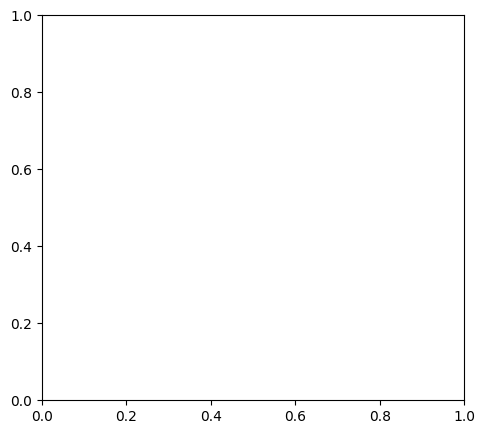

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Before handling
plt.subplot(1, 2, 1)
sns.histplot(df['concentration'], bins=30)
plt.title('Before Detection Limit Handling')
plt.axvline(x=0.5, color='red', linestyle='--', label='LOD')
plt.legend()

# After handling (using LOD/2)
plt.subplot(1, 2, 2)
sns.histplot(df_cleaned['concentration'], bins=30)
plt.title('After Detection Limit Handling')
plt.axvline(x=0.5, color='red', linestyle='--', label='LOD')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create sample data
np.random.seed(42)
sample_data = {
    'measurement_1': np.random.normal(5, 2, 100),
    'measurement_2': np.random.exponential(3, 100),
    'measurement_3': np.random.uniform(0, 10, 100),
    'category': np.random.choice(['A', 'B', 'C'], 100),
    'id': range(1, 101)
}

# Introduce some missing values and outliers
sample_data['measurement_1'][:5] = np.nan
sample_data['measurement_2'][10:15] = np.nan
sample_data['measurement_3'][20:25] = np.nan
sample_data['measurement_1'][30:35] = 100  # outliers
sample_data['measurement_2'][40:45] = 50   # outliers

df = pd.DataFrame(sample_data)

# Now use any of the visualization functions
print("Available columns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nSample data:\n", df.head())

# Method 1: Auto-detect and visualize
visualize_detection_limits(df)

# Method 2: Complete EDA
complete_eda_visualization(df)

# Method 3: Interactive (uncomment if using Jupyter Notebook)
# interactive_detection_limits(df)

Available columns: ['measurement_1', 'measurement_2', 'measurement_3', 'category', 'id']

Data types:
 measurement_1    float64
measurement_2    float64
measurement_3    float64
category          object
id                 int64
dtype: object

Sample data:
    measurement_1  measurement_2  measurement_3 category  id
0            NaN       1.620820       7.948113        C   1
1            NaN       0.753502       5.026371        A   2
2            NaN       0.383041       5.769039        B   3
3            NaN       1.235726       4.925177        A   4
4            NaN       8.589363       1.952430        A   5


NameError: name 'visualize_detection_limits' is not defined

In [5]:
def safe_column_access(df, column_name):
    """
    Safe way to access columns with error handling
    """
    if column_name not in df.columns:
        # Find similar columns
        similar_cols = [col for col in df.columns if column_name.lower() in col.lower()]
        if similar_cols:
            print(f"Column '{column_name}' not found. Did you mean: {similar_cols[:3]}?")
            return df[similar_cols[0]] if similar_cols else None
        else:
            print(f"Column '{column_name}' not found. Available columns: {df.columns.tolist()}")
            return None
    return df[column_name]

📊 DATASET INFORMATION
Available columns: ['measurement_1', 'measurement_2', 'measurement_3', 'concentration', 'category', 'id']

Data types:
 measurement_1    float64
measurement_2    float64
measurement_3    float64
concentration    float64
category          object
id                 int64
dtype: object

Sample data (first 5 rows):
    measurement_1  measurement_2  measurement_3  concentration category  id
0            NaN       1.620820       7.948113       2.633456        A   1
1            NaN       0.753502       5.026371       1.646165        B   2
2            NaN       0.383041       5.769039       2.221910        B   3
3            NaN       1.235726       4.925177       2.387317        B   4
4            NaN       8.589363       1.952430       1.536535        A   5


🔍 METHOD 1: Detection Limits Visualization
----------------------------------------
Using column: 'measurement_1' for demonstration
Available numeric columns: ['measurement_1', 'measurement_2', 'measurement_3', '

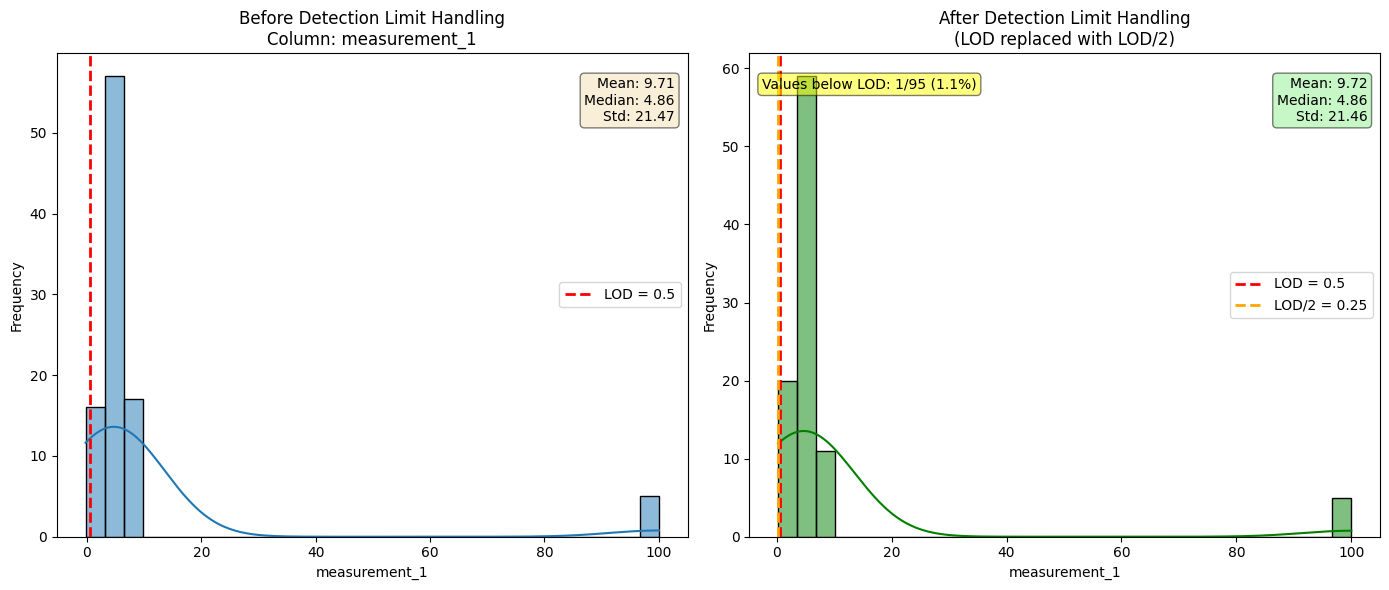


📈 METHOD 2: Complete EDA Visualization
----------------------------------------


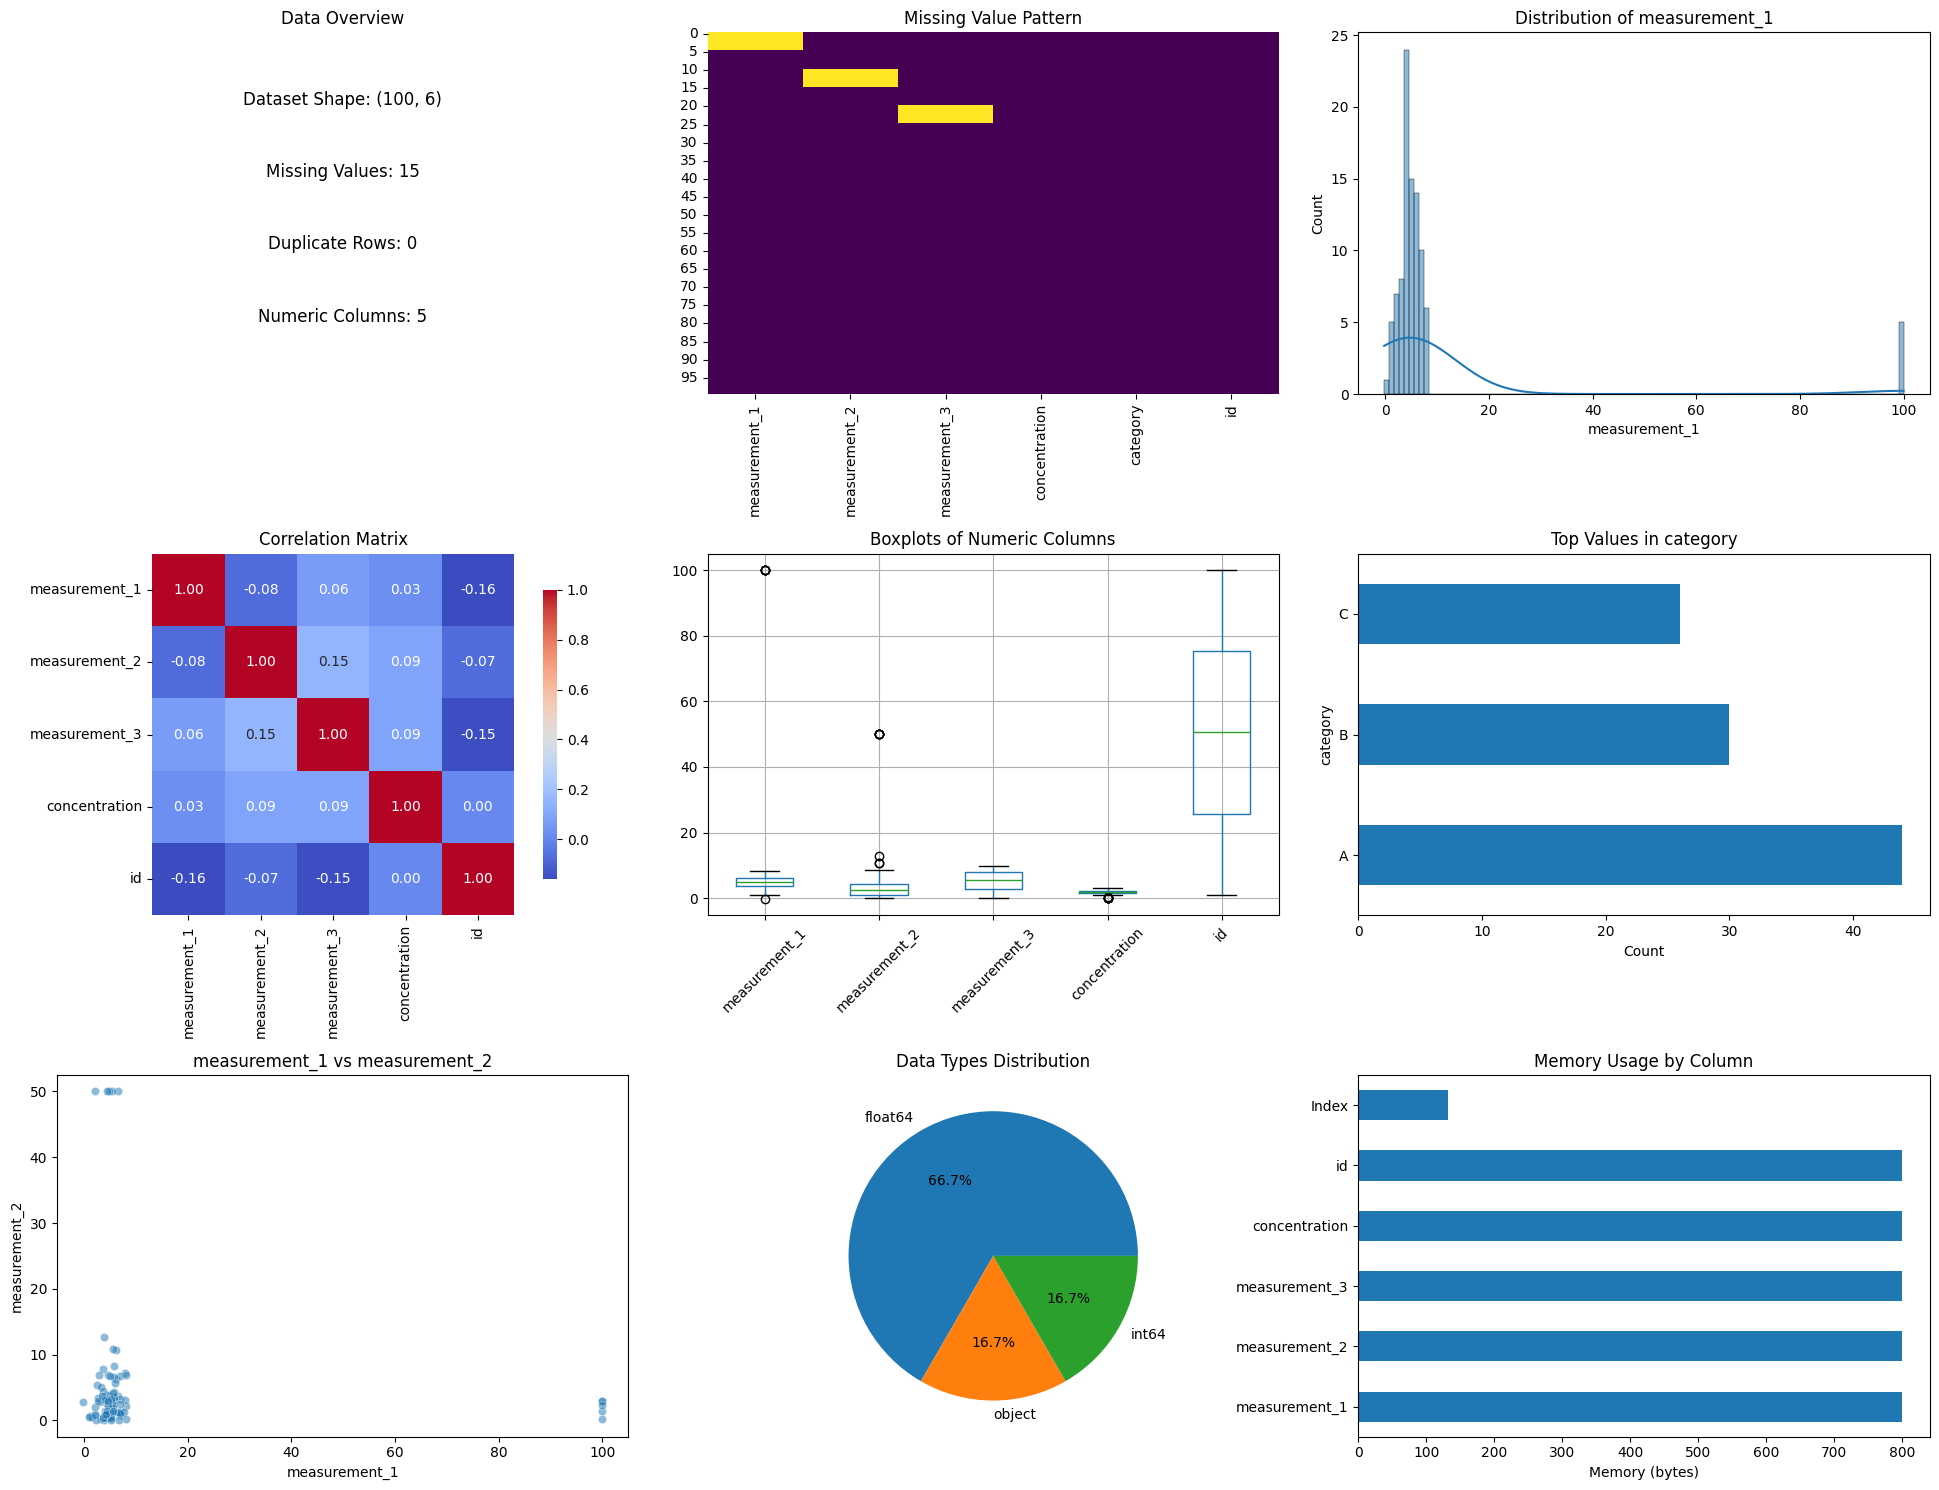


📊 **DATASET SUMMARY**
Total Rows: 100
Total Columns: 6
Missing Values: 15
Duplicate Rows: 0
Numeric Columns: 5
Categorical Columns: 1

📈 Numeric Column Statistics:
       measurement_1  measurement_2  measurement_3  concentration          id
count      95.000000      95.000000      95.000000     100.000000  100.000000
mean        9.711967       5.343771       5.348645       1.906957   50.500000
std        21.465479      10.907042       2.887457       0.608231   29.011492
min        -0.239490       0.015223       0.154566       0.100000    1.000000
25%         3.837074       0.831033       2.900665       1.644818   25.750000
50%         4.855980       2.387094       5.543541       1.992184   50.500000
75%         6.055827       4.209368       7.824024       2.312588   75.250000
max       100.000000      50.000000       9.900539       3.066517  100.000000


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, widgets
import warnings
warnings.filterwarnings('ignore')

# ============================================
# FUNCTION 1: Visualize Detection Limits
# ============================================
def visualize_detection_limits(df, lod_value=0.5):
    """
    Automatically detect and visualize detection limits in numeric columns
    """
    # Find all numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("No numeric columns found in the dataset!")
        return
    
    # For demonstration, use the first numeric column
    col_to_plot = numeric_cols[0]
    
    print(f"Using column: '{col_to_plot}' for demonstration")
    print(f"Available numeric columns: {numeric_cols}")
    
    # Before handling - show original distribution
    plt.figure(figsize=(14, 6))
    
    plt.subplot(1, 2, 1)
    # Clean the data: remove NaN and infinite values
    clean_data = df[col_to_plot].replace([np.inf, -np.inf], np.nan).dropna()
    
    if len(clean_data) > 0:
        sns.histplot(clean_data, bins=30, kde=True)
        plt.title(f'Before Detection Limit Handling\nColumn: {col_to_plot}')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info
        stats_text = f'Mean: {clean_data.mean():.2f}\nMedian: {clean_data.median():.2f}\nStd: {clean_data.std():.2f}'
        plt.text(0.98, 0.95, stats_text, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data to plot', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    # After handling - simulate handling detection limits
    plt.subplot(1, 2, 2)
    
    # Apply LOD/2 handling to values below LOD
    data_after = clean_data.copy()
    # Replace values below LOD with LOD/2
    mask_below_lod = data_after < lod_value
    data_after[mask_below_lod] = lod_value / 2
    
    if len(data_after) > 0:
        sns.histplot(data_after, bins=30, kde=True, color='green')
        plt.title(f'After Detection Limit Handling\n(LOD replaced with LOD/2)')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.axvline(x=lod_value/2, color='orange', linestyle='--', linewidth=2, label=f'LOD/2 = {lod_value/2}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info after handling
        stats_text_after = f'Mean: {data_after.mean():.2f}\nMedian: {data_after.median():.2f}\nStd: {data_after.std():.2f}'
        plt.text(0.98, 0.95, stats_text_after, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
        
        # Show how many values were affected
        affected_count = mask_below_lod.sum()
        total_count = len(data_after)
        plt.text(0.02, 0.95, f'Values below LOD: {affected_count}/{total_count} ({affected_count/total_count*100:.1f}%)',
                transform=plt.gca().transAxes, verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data after processing', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    plt.tight_layout()
    plt.show()
    
    return numeric_cols

# ============================================
# FUNCTION 2: Complete EDA Visualization
# ============================================
def complete_eda_visualization(df):
    """
    Complete EDA visualization showing all important aspects
    """
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Data Overview
    ax1 = plt.subplot(3, 3, 1)
    ax1.text(0.5, 0.8, f"Dataset Shape: {df.shape}", ha='center', fontsize=12)
    ax1.text(0.5, 0.6, f"Missing Values: {df.isnull().sum().sum()}", ha='center', fontsize=12)
    ax1.text(0.5, 0.4, f"Duplicate Rows: {df.duplicated().sum()}", ha='center', fontsize=12)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    ax1.text(0.5, 0.2, f"Numeric Columns: {len(numeric_cols)}", ha='center', fontsize=12)
    ax1.set_title('Data Overview')
    ax1.axis('off')
    
    # 2. Missing Values Heatmap
    ax2 = plt.subplot(3, 3, 2)
    if df.isnull().sum().sum() > 0:
        sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=ax2)
        ax2.set_title('Missing Value Pattern')
    else:
        ax2.text(0.5, 0.5, 'No Missing Values', ha='center', va='center')
        ax2.set_title('Missing Value Pattern')
        ax2.axis('off')
    
    # 3. Numeric Columns Distribution
    ax3 = plt.subplot(3, 3, 3)
    if numeric_cols:
        # Show distribution of first numeric column
        first_col = numeric_cols[0]
        clean_data = df[first_col].replace([np.inf, -np.inf], np.nan).dropna()
        if len(clean_data) > 0:
            sns.histplot(clean_data, kde=True, ax=ax3)
            ax3.set_title(f'Distribution of {first_col}')
            ax3.set_xlabel(first_col)
    
    # 4. Correlation Matrix
    ax4 = plt.subplot(3, 3, 4)
    if len(numeric_cols) >= 2:
        corr = df[numeric_cols].corr()
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
                   square=True, ax=ax4, cbar_kws={'shrink': 0.8})
        ax4.set_title('Correlation Matrix')
    
    # 5. Box Plots for Numeric Columns
    ax5 = plt.subplot(3, 3, 5)
    if numeric_cols:
        # Show boxplots for first few numeric columns
        cols_to_plot = numeric_cols[:min(5, len(numeric_cols))]
        data_for_box = df[cols_to_plot].replace([np.inf, -np.inf], np.nan)
        if len(data_for_box.columns) > 0:
            data_for_box.boxplot(ax=ax5, rot=45)
            ax5.set_title('Boxplots of Numeric Columns')
    
    # 6. Value Counts for Categorical Columns
    ax6 = plt.subplot(3, 3, 6)
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if cat_cols:
        # Show first categorical column
        first_cat = cat_cols[0]
        top_categories = df[first_cat].value_counts().head(10)
        if len(top_categories) > 0:
            top_categories.plot(kind='barh', ax=ax6)
            ax6.set_title(f'Top Values in {first_cat}')
            ax6.set_xlabel('Count')
    
    # 7. Scatter Plot (if at least 2 numeric columns)
    ax7 = plt.subplot(3, 3, 7)
    if len(numeric_cols) >= 2:
        col1, col2 = numeric_cols[0], numeric_cols[1] if len(numeric_cols) > 1 else numeric_cols[0]
        if col1 != col2:
            # Clean data for scatter
            scatter_data = df[[col1, col2]].replace([np.inf, -np.inf], np.nan).dropna()
            if len(scatter_data) > 0:
                sns.scatterplot(data=scatter_data, x=col1, y=col2, ax=ax7, alpha=0.5)
                ax7.set_title(f'{col1} vs {col2}')
    
    # 8. Data Types Distribution
    ax8 = plt.subplot(3, 3, 8)
    dtypes = df.dtypes.value_counts()
    dtypes.plot(kind='pie', ax=ax8, autopct='%1.1f%%')
    ax8.set_title('Data Types Distribution')
    ax8.set_ylabel('')
    
    # 9. Memory Usage
    ax9 = plt.subplot(3, 3, 9)
    memory_usage = df.memory_usage(deep=True)
    # Show top memory consumers
    top_memory = memory_usage.sort_values(ascending=False).head(10)
    if len(top_memory) > 1:
        top_memory[1:].plot(kind='barh', ax=ax9)
        ax9.set_title('Memory Usage by Column')
        ax9.set_xlabel('Memory (bytes)')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n📊 **DATASET SUMMARY**")
    print("="*50)
    print(f"Total Rows: {len(df)}")
    print(f"Total Columns: {len(df.columns)}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    print(f"Numeric Columns: {len(numeric_cols)}")
    print(f"Categorical Columns: {len(cat_cols)}")
    
    if numeric_cols:
        print("\n📈 Numeric Column Statistics:")
        print(df[numeric_cols].describe().to_string())

# ============================================
# FUNCTION 3: Interactive Detection Limits
# ============================================
def interactive_detection_limits(df):
    """
    Interactive visualization with column selection
    """
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("No numeric columns found!")
        return
    
    def plot_column(col_name, lod_value=0.5, handling_method='LOD/2'):
        clean_data = df[col_name].replace([np.inf, -np.inf], np.nan).dropna()
        
        if len(clean_data) == 0:
            print(f"No valid data in column: {col_name}")
            return
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        # Before
        axes[0].hist(clean_data, bins=30, alpha=0.7, edgecolor='black')
        axes[0].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        axes[0].set_title(f'Before Handling\n{col_name}')
        axes[0].set_xlabel(col_name)
        axes[0].set_ylabel('Frequency')
        axes[0].legend()
        
        # After
        data_after = clean_data.copy()
        if handling_method == 'LOD/2':
            data_after[data_after < lod_value] = lod_value / 2
            label = f'LOD/2 = {lod_value/2}'
        elif handling_method == 'LOD/√2':
            data_after[data_after < lod_value] = lod_value / np.sqrt(2)
            label = f'LOD/√2 = {lod_value/np.sqrt(2):.3f}'
        else:  # Remove below LOD
            data_after = data_after[data_after >= lod_value]
            label = f'Remove < LOD'
        
        axes[1].hist(data_after, bins=30, alpha=0.7, color='green', edgecolor='black')
        axes[1].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        if handling_method in ['LOD/2', 'LOD/√2']:
            axes[1].axvline(x=lod_value/2, color='orange', linestyle='--', 
                          linewidth=2, label=label)
        axes[1].set_title(f'After Handling\n{col_name}')
        axes[1].set_xlabel(col_name)
        axes[1].set_ylabel('Frequency')
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print(f"\n📊 Statistics for '{col_name}':")
        print(f"Before: Mean={clean_data.mean():.3f}, Median={clean_data.median():.3f}, "
              f"Std={clean_data.std():.3f}")
        print(f"After:  Mean={data_after.mean():.3f}, Median={data_after.median():.3f}, "
              f"Std={data_after.std():.3f}")
        if isinstance(data_after, pd.Series):
            print(f"Values changed: {len(clean_data) - len(data_after)} ({100*(1-len(data_after)/len(clean_data)):.1f}%)")
    
    # Create interactive widgets
    interact(plot_column,
             col_name=widgets.Dropdown(options=numeric_cols, description='Column:'),
             lod_value=widgets.FloatSlider(min=0.1, max=10, step=0.1, value=0.5, description='LOD Value:'),
             handling_method=widgets.Dropdown(options=['LOD/2', 'LOD/√2', 'Remove'], 
                                             description='Method:'))

# ============================================
# FUNCTION 4: Safe Column Access Helper
# ============================================
def safe_column_access(df, column_name):
    """
    Safe way to access columns with error handling
    """
    if column_name not in df.columns:
        # Find similar columns
        similar_cols = [col for col in df.columns if column_name.lower() in col.lower()]
        if similar_cols:
            print(f"Column '{column_name}' not found. Did you mean: {similar_cols[:3]}?")
            return df[similar_cols[0]] if similar_cols else None
        else:
            print(f"Column '{column_name}' not found. Available columns: {df.columns.tolist()}")
            return None
    return df[column_name]

# ============================================
# MAIN EXECUTION CODE
# ============================================
if __name__ == "__main__":
    # Create sample data
    np.random.seed(42)
    sample_data = {
        'measurement_1': np.random.normal(5, 2, 100),
        'measurement_2': np.random.exponential(3, 100),
        'measurement_3': np.random.uniform(0, 10, 100),
        'concentration': np.random.normal(2, 0.5, 100),  # Added this for demonstration
        'category': np.random.choice(['A', 'B', 'C'], 100),
        'id': range(1, 101)
    }

    # Introduce some missing values and outliers
    sample_data['measurement_1'][:5] = np.nan
    sample_data['measurement_2'][10:15] = np.nan
    sample_data['measurement_3'][20:25] = np.nan
    sample_data['measurement_1'][30:35] = 100  # outliers
    sample_data['measurement_2'][40:45] = 50   # outliers
    sample_data['concentration'][50:55] = 0.1  # below detection limit

    df = pd.DataFrame(sample_data)

    print("="*60)
    print("📊 DATASET INFORMATION")
    print("="*60)
    print("Available columns:", df.columns.tolist())
    print("\nData types:\n", df.dtypes)
    print("\nSample data (first 5 rows):\n", df.head())
    print("\n" + "="*60)

    # METHOD 1: Auto-detect and visualize detection limits
    print("\n🔍 METHOD 1: Detection Limits Visualization")
    print("-"*40)
    visualize_detection_limits(df, lod_value=0.5)

    # METHOD 2: Complete EDA
    print("\n📈 METHOD 2: Complete EDA Visualization")
    print("-"*40)
    complete_eda_visualization(df)

    # METHOD 3: Interactive (uncomment if using Jupyter Notebook)
    # print("\n🎮 METHOD 3: Interactive Visualization")
    # print("-"*40)
    # interactive_detection_limits(df)

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# ============================================
# FUNCTION 1: Load Data from File Path
# ============================================
def load_data(file_path, file_type=None, **kwargs):
    """
    Load data from various file formats based on file path
    
    Parameters:
    -----------
    file_path : str or Path
        Path to the data file
    file_type : str, optional
        Type of file (csv, excel, json, parquet, etc.)
        If None, it will be inferred from file extension
    **kwargs : additional arguments passed to the read function
    
    Returns:
    --------
    pandas.DataFrame : Loaded data
    """
    file_path = Path(file_path)
    
    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}")
    
    # Infer file type from extension if not specified
    if file_type is None:
        file_type = file_path.suffix.lower().replace('.', '')
    
    print(f"📂 Loading file: {file_path.name}")
    print(f"📁 File type: {file_type}")
    
    try:
        # Load based on file type
        if file_type in ['csv', 'tsv', 'txt']:
            # Handle different delimiters
            if file_type == 'csv':
                df = pd.read_csv(file_path, **kwargs)
            elif file_type == 'tsv':
                df = pd.read_csv(file_path, sep='\t', **kwargs)
            else:  # txt - try to auto-detect delimiter
                df = pd.read_csv(file_path, sep=None, engine='python', **kwargs)
                
        elif file_type in ['xlsx', 'xls']:
            df = pd.read_excel(file_path, **kwargs)
            
        elif file_type == 'json':
            df = pd.read_json(file_path, **kwargs)
            
        elif file_type == 'parquet':
            df = pd.read_parquet(file_path, **kwargs)
            
        elif file_type == 'feather':
            df = pd.read_feather(file_path, **kwargs)
            
        elif file_type == 'pickle' or file_type == 'pkl':
            df = pd.read_pickle(file_path, **kwargs)
            
        else:
            raise ValueError(f"Unsupported file type: {file_type}")
        
        print(f"✅ Successfully loaded {len(df)} rows and {len(df.columns)} columns")
        return df
        
    except Exception as e:
        print(f"❌ Error loading file: {e}")
        raise

# ============================================
# FUNCTION 2: Visualize Detection Limits
# ============================================
def visualize_detection_limits(df, lod_value=0.5, column=None):
    """
    Automatically detect and visualize detection limits in numeric columns
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataset
    lod_value : float
        Limit of Detection value
    column : str, optional
        Specific column to visualize. If None, uses first numeric column
    """
    # Find all numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("⚠️ No numeric columns found in the dataset!")
        return
    
    # Use specified column or first numeric column
    if column is not None and column in numeric_cols:
        col_to_plot = column
    else:
        col_to_plot = numeric_cols[0]
        if column is not None:
            print(f"⚠️ Column '{column}' not found or not numeric. Using '{col_to_plot}' instead")
    
    print(f"\n🔍 Visualizing detection limits for column: '{col_to_plot}'")
    print(f"📊 Available numeric columns: {numeric_cols}")
    
    # Before handling - show original distribution
    plt.figure(figsize=(14, 6))
    
    plt.subplot(1, 2, 1)
    # Clean the data: remove NaN and infinite values
    clean_data = df[col_to_plot].replace([np.inf, -np.inf], np.nan).dropna()
    
    if len(clean_data) > 0:
        sns.histplot(clean_data, bins=30, kde=True)
        plt.title(f'Before Detection Limit Handling\nColumn: {col_to_plot}')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info
        stats_text = f'Mean: {clean_data.mean():.2f}\nMedian: {clean_data.median():.2f}\nStd: {clean_data.std():.2f}\nN: {len(clean_data)}'
        plt.text(0.98, 0.95, stats_text, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data to plot', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    # After handling - simulate handling detection limits
    plt.subplot(1, 2, 2)
    
    # Apply LOD/2 handling to values below LOD
    data_after = clean_data.copy()
    # Replace values below LOD with LOD/2
    mask_below_lod = data_after < lod_value
    data_after[mask_below_lod] = lod_value / 2
    
    if len(data_after) > 0:
        sns.histplot(data_after, bins=30, kde=True, color='green')
        plt.title(f'After Detection Limit Handling\n(LOD replaced with LOD/2)')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.axvline(x=lod_value/2, color='orange', linestyle='--', linewidth=2, label=f'LOD/2 = {lod_value/2}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info after handling
        stats_text_after = f'Mean: {data_after.mean():.2f}\nMedian: {data_after.median():.2f}\nStd: {data_after.std():.2f}\nN: {len(data_after)}'
        plt.text(0.98, 0.95, stats_text_after, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
        
        # Show how many values were affected
        affected_count = mask_below_lod.sum()
        total_count = len(data_after)
        plt.text(0.02, 0.95, f'Values below LOD: {affected_count}/{total_count} ({affected_count/total_count*100:.1f}%)',
                transform=plt.gca().transAxes, verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data after processing', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    plt.tight_layout()
    plt.show()
    
    return numeric_cols

# ============================================
# FUNCTION 3: Complete EDA Visualization
# ============================================
def complete_eda_visualization(df, output_dir=None):
    """
    Complete EDA visualization showing all important aspects
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataset
    output_dir : str, optional
        Directory to save figures. If None, figures are displayed but not saved
    """
    if output_dir:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Data Overview
    ax1 = plt.subplot(3, 3, 1)
    ax1.text(0.5, 0.8, f"Dataset Shape: {df.shape}", ha='center', fontsize=12)
    ax1.text(0.5, 0.6, f"Missing Values: {df.isnull().sum().sum()}", ha='center', fontsize=12)
    ax1.text(0.5, 0.4, f"Duplicate Rows: {df.duplicated().sum()}", ha='center', fontsize=12)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    ax1.text(0.5, 0.2, f"Numeric Columns: {len(numeric_cols)}", ha='center', fontsize=12)
    ax1.set_title('Data Overview')
    ax1.axis('off')
    
    # 2. Missing Values Heatmap
    ax2 = plt.subplot(3, 3, 2)
    if df.isnull().sum().sum() > 0:
        sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=ax2)
        ax2.set_title('Missing Value Pattern')
    else:
        ax2.text(0.5, 0.5, 'No Missing Values', ha='center', va='center')
        ax2.set_title('Missing Value Pattern')
        ax2.axis('off')
    
    # 3. Numeric Columns Distribution
    ax3 = plt.subplot(3, 3, 3)
    if numeric_cols:
        # Show distribution of first numeric column
        first_col = numeric_cols[0]
        clean_data = df[first_col].replace([np.inf, -np.inf], np.nan).dropna()
        if len(clean_data) > 0:
            sns.histplot(clean_data, kde=True, ax=ax3)
            ax3.set_title(f'Distribution of {first_col}')
            ax3.set_xlabel(first_col)
    
    # 4. Correlation Matrix
    ax4 = plt.subplot(3, 3, 4)
    if len(numeric_cols) >= 2:
        corr = df[numeric_cols].corr()
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
                   square=True, ax=ax4, cbar_kws={'shrink': 0.8})
        ax4.set_title('Correlation Matrix')
    
    # 5. Box Plots for Numeric Columns
    ax5 = plt.subplot(3, 3, 5)
    if numeric_cols:
        # Show boxplots for first few numeric columns
        cols_to_plot = numeric_cols[:min(5, len(numeric_cols))]
        data_for_box = df[cols_to_plot].replace([np.inf, -np.inf], np.nan)
        if len(data_for_box.columns) > 0:
            data_for_box.boxplot(ax=ax5, rot=45)
            ax5.set_title('Boxplots of Numeric Columns')
    
    # 6. Value Counts for Categorical Columns
    ax6 = plt.subplot(3, 3, 6)
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if cat_cols:
        # Show first categorical column
        first_cat = cat_cols[0]
        top_categories = df[first_cat].value_counts().head(10)
        if len(top_categories) > 0:
            top_categories.plot(kind='barh', ax=ax6)
            ax6.set_title(f'Top Values in {first_cat}')
            ax6.set_xlabel('Count')
    
    # 7. Scatter Plot (if at least 2 numeric columns)
    ax7 = plt.subplot(3, 3, 7)
    if len(numeric_cols) >= 2:
        col1, col2 = numeric_cols[0], numeric_cols[1] if len(numeric_cols) > 1 else numeric_cols[0]
        if col1 != col2:
            # Clean data for scatter
            scatter_data = df[[col1, col2]].replace([np.inf, -np.inf], np.nan).dropna()
            if len(scatter_data) > 0:
                sns.scatterplot(data=scatter_data, x=col1, y=col2, ax=ax7, alpha=0.5)
                ax7.set_title(f'{col1} vs {col2}')
    
    # 8. Data Types Distribution
    ax8 = plt.subplot(3, 3, 8)
    dtypes = df.dtypes.value_counts()
    dtypes.plot(kind='pie', ax=ax8, autopct='%1.1f%%')
    ax8.set_title('Data Types Distribution')
    ax8.set_ylabel('')
    
    # 9. Memory Usage
    ax9 = plt.subplot(3, 3, 9)
    memory_usage = df.memory_usage(deep=True)
    # Show top memory consumers
    top_memory = memory_usage.sort_values(ascending=False).head(10)
    if len(top_memory) > 1:
        top_memory[1:].plot(kind='barh', ax=ax9)
        ax9.set_title('Memory Usage by Column')
        ax9.set_xlabel('Memory (bytes)')
    
    plt.tight_layout()
    
    # Save figure if output directory is specified
    if output_dir:
        fig_path = output_dir / 'eda_visualization.png'
        plt.savefig(fig_path, dpi=300, bbox_inches='tight')
        print(f"💾 Figure saved to: {fig_path}")
    
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("📊 DATASET SUMMARY")
    print("="*60)
    print(f"Total Rows: {len(df)}")
    print(f"Total Columns: {len(df.columns)}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    print(f"Numeric Columns: {len(numeric_cols)}")
    print(f"Categorical Columns: {len(cat_cols)}")
    
    if numeric_cols:
        print("\n📈 Numeric Column Statistics:")
        print(df[numeric_cols].describe().to_string())
    
    # Save summary to file if output directory specified
    if output_dir:
        summary_path = output_dir / 'data_summary.txt'
        with open(summary_path, 'w') as f:
            f.write("DATA SUMMARY\n")
            f.write("="*60 + "\n")
            f.write(f"Total Rows: {len(df)}\n")
            f.write(f"Total Columns: {len(df.columns)}\n")
            f.write(f"Missing Values: {df.isnull().sum().sum()}\n")
            f.write(f"Duplicate Rows: {df.duplicated().sum()}\n")
            f.write(f"Numeric Columns: {len(numeric_cols)}\n")
            f.write(f"Categorical Columns: {len(cat_cols)}\n\n")
            if numeric_cols:
                f.write("Numeric Column Statistics:\n")
                f.write(df[numeric_cols].describe().to_string())
        print(f"💾 Summary saved to: {summary_path}")

# ============================================
# FUNCTION 4: Interactive Detection Limits
# ============================================
def interactive_detection_limits(df):
    """
    Interactive visualization with column selection (Jupyter only)
    """
    from ipywidgets import interact, widgets
    
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("No numeric columns found!")
        return
    
    def plot_column(col_name, lod_value=0.5, handling_method='LOD/2'):
        clean_data = df[col_name].replace([np.inf, -np.inf], np.nan).dropna()
        
        if len(clean_data) == 0:
            print(f"No valid data in column: {col_name}")
            return
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        # Before
        axes[0].hist(clean_data, bins=30, alpha=0.7, edgecolor='black')
        axes[0].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        axes[0].set_title(f'Before Handling\n{col_name}')
        axes[0].set_xlabel(col_name)
        axes[0].set_ylabel('Frequency')
        axes[0].legend()
        
        # After
        data_after = clean_data.copy()
        if handling_method == 'LOD/2':
            data_after[data_after < lod_value] = lod_value / 2
            label = f'LOD/2 = {lod_value/2}'
        elif handling_method == 'LOD/√2':
            data_after[data_after < lod_value] = lod_value / np.sqrt(2)
            label = f'LOD/√2 = {lod_value/np.sqrt(2):.3f}'
        else:  # Remove below LOD
            data_after = data_after[data_after >= lod_value]
            label = f'Remove < LOD'
        
        axes[1].hist(data_after, bins=30, alpha=0.7, color='green', edgecolor='black')
        axes[1].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        if handling_method in ['LOD/2', 'LOD/√2']:
            axes[1].axvline(x=lod_value/2, color='orange', linestyle='--', 
                          linewidth=2, label=label)
        axes[1].set_title(f'After Handling\n{col_name}')
        axes[1].set_xlabel(col_name)
        axes[1].set_ylabel('Frequency')
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print(f"\n📊 Statistics for '{col_name}':")
        print(f"Before: Mean={clean_data.mean():.3f}, Median={clean_data.median():.3f}, "
              f"Std={clean_data.std():.3f}")
        print(f"After:  Mean={data_after.mean():.3f}, Median={data_after.median():.3f}, "
              f"Std={data_after.std():.3f}")
        if isinstance(data_after, pd.Series):
            print(f"Values changed: {len(clean_data) - len(data_after)} ({100*(1-len(data_after)/len(clean_data)):.1f}%)")
    
    # Create interactive widgets
    interact(plot_column,
             col_name=widgets.Dropdown(options=numeric_cols, description='Column:'),
             lod_value=widgets.FloatSlider(min=0.1, max=10, step=0.1, value=0.5, description='LOD Value:'),
             handling_method=widgets.Dropdown(options=['LOD/2', 'LOD/√2', 'Remove'], 
                                             description='Method:'))

# ============================================
# FUNCTION 5: Main Pipeline
# ============================================
def run_analysis_pipeline(file_path, lod_value=0.5, column=None, output_dir=None, 
                          file_type=None, **kwargs):
    """
    Complete analysis pipeline: load data, visualize, and save results
    
    Parameters:
    -----------
    file_path : str or Path
        Path to the data file
    lod_value : float
        Limit of Detection value
    column : str, optional
        Specific column to visualize for detection limits
    output_dir : str, optional
        Directory to save results
    file_type : str, optional
        Type of file (csv, excel, json, etc.)
    **kwargs : additional arguments passed to the read function
    
    Returns:
    --------
    pandas.DataFrame : Loaded and analyzed data
    """
    print("="*70)
    print("🚀 STARTING DATA ANALYSIS PIPELINE")
    print("="*70)
    
    # Step 1: Load Data
    print("\n📂 STEP 1: Loading Data")
    print("-"*40)
    df = load_data(file_path, file_type, **kwargs)
    
    if df is None or df.empty:
        print("❌ No data loaded. Exiting pipeline.")
        return None
    
    print(f"\n✅ Data loaded successfully!")
    print(f"   Shape: {df.shape}")
    print(f"   Columns: {df.columns.tolist()}")
    
    # Step 2: Detection Limits Visualization
    print("\n📊 STEP 2: Detection Limits Visualization")
    print("-"*40)
    numeric_cols = visualize_detection_limits(df, lod_value, column)
    
    # Step 3: Complete EDA
    print("\n📈 STEP 3: Complete EDA")
    print("-"*40)
    complete_eda_visualization(df, output_dir)
    
    print("\n" + "="*70)
    print("✅ ANALYSIS COMPLETE!")
    print("="*70)
    
    return df

# ============================================
# MAIN EXECUTION
# ============================================
if __name__ == "__main__":
    # ==========================================
    # CONFIGURATION - SET YOUR FILE PATH HERE
    # ==========================================
    
    # Option 1: Use a sample dataset (no file needed)
    # This will create a sample dataset for demonstration
    USE_SAMPLE_DATA = True
    
    # Option 2: Specify your file path
    # Uncomment and set your file path below
    # USE_SAMPLE_DATA = False
    # FILE_PATH = "C:/Users/YourName/Downloads/your_data.csv"  # Windows
    # FILE_PATH = "/home/username/data/your_data.csv"          # Linux/Mac
    # FILE_PATH = "data/your_data.xlsx"                        # Relative path
    
    # Optional: Configure additional parameters
    LOD_VALUE = 0.5
    COLUMN = None  # Set to specific column name or None for auto-detection
    OUTPUT_DIR = "analysis_results"  # Directory to save results
    FILE_TYPE = None  # Auto-detect from extension, or specify: 'csv', 'excel', 'json', etc.
    
    # Additional kwargs for read functions
    READ_KWARGS = {}  # e.g., {'sheet_name': 'Sheet1'} for Excel files
    
    print("="*70)
    print("📊 DATA ANALYSIS PIPELINE CONFIGURATION")
    print("="*70)
    
    if USE_SAMPLE_DATA:
        print("🎯 Using sample dataset for demonstration")
        print("-"*40)
        
        # Create sample data
        np.random.seed(42)
        sample_data = {
            'measurement_1': np.random.normal(5, 2, 100),
            'measurement_2': np.random.exponential(3, 100),
            'measurement_3': np.random.uniform(0, 10, 100),
            'concentration': np.random.normal(2, 0.5, 100),
            'category': np.random.choice(['A', 'B', 'C'], 100),
            'id': range(1, 101)
        }

        # Introduce some missing values and outliers
        sample_data['measurement_1'][:5] = np.nan
        sample_data['measurement_2'][10:15] = np.nan
        sample_data['measurement_3'][20:25] = np.nan
        sample_data['measurement_1'][30:35] = 100
        sample_data['measurement_2'][40:45] = 50
        sample_data['concentration'][50:55] = 0.1

        df = pd.DataFrame(sample_data)
        print(f"📊 Created sample dataset with {len(df)} rows and {len(df.columns)} columns")
        
        # Run analysis on sample data
        run_analysis_pipeline(
            file_path=None,  # Not needed for sample data
            lod_value=LOD_VALUE,
            column=COLUMN,
            output_dir=OUTPUT_DIR
        )
        
    else:
        # Use the specified file path
        try:
            df = run_analysis_pipeline(
                file_path=FILE_PATH,
                lod_value=LOD_VALUE,
                column=COLUMN,
                output_dir=OUTPUT_DIR,
                file_type=FILE_TYPE,
                **READ_KWARGS
            )
        except Exception as e:
            print(f"\n❌ Error in analysis pipeline: {e}")
            print("\nPlease check your file path and configuration.")

📊 DATA ANALYSIS PIPELINE CONFIGURATION
🎯 Using sample dataset for demonstration
----------------------------------------
📊 Created sample dataset with 100 rows and 6 columns
🚀 STARTING DATA ANALYSIS PIPELINE

📂 STEP 1: Loading Data
----------------------------------------


TypeError: argument should be a str or an os.PathLike object where __fspath__ returns a str, not 'NoneType'

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# ============================================
# FUNCTION 1: Load Data from File Path
# ============================================
def load_data(file_path, file_type=None, **kwargs):
    """
    Load data from various file formats based on file path
    
    Parameters:
    -----------
    file_path : str or Path
        Path to the data file
    file_type : str, optional
        Type of file (csv, excel, json, parquet, etc.)
        If None, it will be inferred from file extension
    **kwargs : additional arguments passed to the read function
    
    Returns:
    --------
    pandas.DataFrame : Loaded data
    """
    # Check if file_path is None or empty
    if file_path is None:
        raise ValueError("❌ File path cannot be None. Please provide a valid file path.")
    
    file_path = Path(file_path)
    
    if not file_path.exists():
        raise FileNotFoundError(f"❌ File not found: {file_path}")
    
    # Infer file type from extension if not specified
    if file_type is None:
        file_type = file_path.suffix.lower().replace('.', '')
    
    print(f"📂 Loading file: {file_path.name}")
    print(f"📁 File type: {file_type}")
    
    try:
        # Load based on file type
        if file_type in ['csv', 'tsv', 'txt']:
            # Handle different delimiters
            if file_type == 'csv':
                df = pd.read_csv(file_path, **kwargs)
            elif file_type == 'tsv':
                df = pd.read_csv(file_path, sep='\t', **kwargs)
            else:  # txt - try to auto-detect delimiter
                df = pd.read_csv(file_path, sep=None, engine='python', **kwargs)
                
        elif file_type in ['xlsx', 'xls']:
            df = pd.read_excel(file_path, **kwargs)
            
        elif file_type == 'json':
            df = pd.read_json(file_path, **kwargs)
            
        elif file_type == 'parquet':
            df = pd.read_parquet(file_path, **kwargs)
            
        elif file_type == 'feather':
            df = pd.read_feather(file_path, **kwargs)
            
        elif file_type == 'pickle' or file_type == 'pkl':
            df = pd.read_pickle(file_path, **kwargs)
            
        else:
            raise ValueError(f"Unsupported file type: {file_type}")
        
        print(f"✅ Successfully loaded {len(df)} rows and {len(df.columns)} columns")
        print(f"📋 Columns: {df.columns.tolist()}")
        return df
        
    except Exception as e:
        print(f"❌ Error loading file: {e}")
        raise

# ============================================
# FUNCTION 2: Visualize Detection Limits
# ============================================
def visualize_detection_limits(df, lod_value=0.5, column=None):
    """
    Automatically detect and visualize detection limits in numeric columns
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataset
    lod_value : float
        Limit of Detection value
    column : str, optional
        Specific column to visualize. If None, uses first numeric column
    """
    # Find all numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("⚠️ No numeric columns found in the dataset!")
        return
    
    # Use specified column or first numeric column
    if column is not None and column in numeric_cols:
        col_to_plot = column
    else:
        col_to_plot = numeric_cols[0]
        if column is not None:
            print(f"⚠️ Column '{column}' not found or not numeric. Using '{col_to_plot}' instead")
    
    print(f"\n🔍 Visualizing detection limits for column: '{col_to_plot}'")
    print(f"📊 Available numeric columns: {numeric_cols}")
    
    # Before handling - show original distribution
    plt.figure(figsize=(14, 6))
    
    plt.subplot(1, 2, 1)
    # Clean the data: remove NaN and infinite values
    clean_data = df[col_to_plot].replace([np.inf, -np.inf], np.nan).dropna()
    
    if len(clean_data) > 0:
        sns.histplot(clean_data, bins=30, kde=True)
        plt.title(f'Before Detection Limit Handling\nColumn: {col_to_plot}')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info
        stats_text = f'Mean: {clean_data.mean():.2f}\nMedian: {clean_data.median():.2f}\nStd: {clean_data.std():.2f}\nN: {len(clean_data)}'
        plt.text(0.98, 0.95, stats_text, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data to plot', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    # After handling - simulate handling detection limits
    plt.subplot(1, 2, 2)
    
    # Apply LOD/2 handling to values below LOD
    data_after = clean_data.copy()
    # Replace values below LOD with LOD/2
    mask_below_lod = data_after < lod_value
    data_after[mask_below_lod] = lod_value / 2
    
    if len(data_after) > 0:
        sns.histplot(data_after, bins=30, kde=True, color='green')
        plt.title(f'After Detection Limit Handling\n(LOD replaced with LOD/2)')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.axvline(x=lod_value/2, color='orange', linestyle='--', linewidth=2, label=f'LOD/2 = {lod_value/2}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        # Add statistical info after handling
        stats_text_after = f'Mean: {data_after.mean():.2f}\nMedian: {data_after.median():.2f}\nStd: {data_after.std():.2f}\nN: {len(data_after)}'
        plt.text(0.98, 0.95, stats_text_after, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
        
        # Show how many values were affected
        affected_count = mask_below_lod.sum()
        total_count = len(data_after)
        plt.text(0.02, 0.95, f'Values below LOD: {affected_count}/{total_count} ({affected_count/total_count*100:.1f}%)',
                transform=plt.gca().transAxes, verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data after processing', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    plt.tight_layout()
    plt.show()
    
    return numeric_cols

# ============================================
# FUNCTION 3: Complete EDA Visualization
# ============================================
def complete_eda_visualization(df, output_dir=None):
    """
    Complete EDA visualization showing all important aspects
    
    Parameters:
    -----------
    df : pandas.DataFrame
        The dataset
    output_dir : str, optional
        Directory to save figures. If None, figures are displayed but not saved
    """
    if output_dir:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Data Overview
    ax1 = plt.subplot(3, 3, 1)
    ax1.text(0.5, 0.8, f"Dataset Shape: {df.shape}", ha='center', fontsize=12)
    ax1.text(0.5, 0.6, f"Missing Values: {df.isnull().sum().sum()}", ha='center', fontsize=12)
    ax1.text(0.5, 0.4, f"Duplicate Rows: {df.duplicated().sum()}", ha='center', fontsize=12)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    ax1.text(0.5, 0.2, f"Numeric Columns: {len(numeric_cols)}", ha='center', fontsize=12)
    ax1.set_title('Data Overview')
    ax1.axis('off')
    
    # 2. Missing Values Heatmap
    ax2 = plt.subplot(3, 3, 2)
    if df.isnull().sum().sum() > 0:
        sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=ax2)
        ax2.set_title('Missing Value Pattern')
    else:
        ax2.text(0.5, 0.5, 'No Missing Values', ha='center', va='center')
        ax2.set_title('Missing Value Pattern')
        ax2.axis('off')
    
    # 3. Numeric Columns Distribution
    ax3 = plt.subplot(3, 3, 3)
    if numeric_cols:
        # Show distribution of first numeric column
        first_col = numeric_cols[0]
        clean_data = df[first_col].replace([np.inf, -np.inf], np.nan).dropna()
        if len(clean_data) > 0:
            sns.histplot(clean_data, kde=True, ax=ax3)
            ax3.set_title(f'Distribution of {first_col}')
            ax3.set_xlabel(first_col)
    
    # 4. Correlation Matrix
    ax4 = plt.subplot(3, 3, 4)
    if len(numeric_cols) >= 2:
        corr = df[numeric_cols].corr()
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
                   square=True, ax=ax4, cbar_kws={'shrink': 0.8})
        ax4.set_title('Correlation Matrix')
    
    # 5. Box Plots for Numeric Columns
    ax5 = plt.subplot(3, 3, 5)
    if numeric_cols:
        # Show boxplots for first few numeric columns
        cols_to_plot = numeric_cols[:min(5, len(numeric_cols))]
        data_for_box = df[cols_to_plot].replace([np.inf, -np.inf], np.nan)
        if len(data_for_box.columns) > 0:
            data_for_box.boxplot(ax=ax5, rot=45)
            ax5.set_title('Boxplots of Numeric Columns')
    
    # 6. Value Counts for Categorical Columns
    ax6 = plt.subplot(3, 3, 6)
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if cat_cols:
        # Show first categorical column
        first_cat = cat_cols[0]
        top_categories = df[first_cat].value_counts().head(10)
        if len(top_categories) > 0:
            top_categories.plot(kind='barh', ax=ax6)
            ax6.set_title(f'Top Values in {first_cat}')
            ax6.set_xlabel('Count')
    
    # 7. Scatter Plot (if at least 2 numeric columns)
    ax7 = plt.subplot(3, 3, 7)
    if len(numeric_cols) >= 2:
        col1, col2 = numeric_cols[0], numeric_cols[1] if len(numeric_cols) > 1 else numeric_cols[0]
        if col1 != col2:
            # Clean data for scatter
            scatter_data = df[[col1, col2]].replace([np.inf, -np.inf], np.nan).dropna()
            if len(scatter_data) > 0:
                sns.scatterplot(data=scatter_data, x=col1, y=col2, ax=ax7, alpha=0.5)
                ax7.set_title(f'{col1} vs {col2}')
    
    # 8. Data Types Distribution
    ax8 = plt.subplot(3, 3, 8)
    dtypes = df.dtypes.value_counts()
    dtypes.plot(kind='pie', ax=ax8, autopct='%1.1f%%')
    ax8.set_title('Data Types Distribution')
    ax8.set_ylabel('')
    
    # 9. Memory Usage
    ax9 = plt.subplot(3, 3, 9)
    memory_usage = df.memory_usage(deep=True)
    # Show top memory consumers
    top_memory = memory_usage.sort_values(ascending=False).head(10)
    if len(top_memory) > 1:
        top_memory[1:].plot(kind='barh', ax=ax9)
        ax9.set_title('Memory Usage by Column')
        ax9.set_xlabel('Memory (bytes)')
    
    plt.tight_layout()
    
    # Save figure if output directory is specified
    if output_dir:
        fig_path = output_dir / 'eda_visualization.png'
        plt.savefig(fig_path, dpi=300, bbox_inches='tight')
        print(f"💾 Figure saved to: {fig_path}")
    
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("📊 DATASET SUMMARY")
    print("="*60)
    print(f"Total Rows: {len(df)}")
    print(f"Total Columns: {len(df.columns)}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    print(f"Numeric Columns: {len(numeric_cols)}")
    print(f"Categorical Columns: {len(cat_cols)}")
    
    if numeric_cols:
        print("\n📈 Numeric Column Statistics:")
        print(df[numeric_cols].describe().to_string())
    
    # Save summary to file if output directory specified
    if output_dir:
        summary_path = output_dir / 'data_summary.txt'
        with open(summary_path, 'w') as f:
            f.write("DATA SUMMARY\n")
            f.write("="*60 + "\n")
            f.write(f"Total Rows: {len(df)}\n")
            f.write(f"Total Columns: {len(df.columns)}\n")
            f.write(f"Missing Values: {df.isnull().sum().sum()}\n")
            f.write(f"Duplicate Rows: {df.duplicated().sum()}\n")
            f.write(f"Numeric Columns: {len(numeric_cols)}\n")
            f.write(f"Categorical Columns: {len(cat_cols)}\n\n")
            if numeric_cols:
                f.write("Numeric Column Statistics:\n")
                f.write(df[numeric_cols].describe().to_string())
        print(f"💾 Summary saved to: {summary_path}")

# ============================================
# FUNCTION 4: Interactive Detection Limits (Jupyter only)
# ============================================
def interactive_detection_limits(df):
    """
    Interactive visualization with column selection (Jupyter only)
    """
    try:
        from ipywidgets import interact, widgets
    except ImportError:
        print("⚠️ ipywidgets not installed. Run: pip install ipywidgets")
        return
    
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("No numeric columns found!")
        return
    
    def plot_column(col_name, lod_value=0.5, handling_method='LOD/2'):
        clean_data = df[col_name].replace([np.inf, -np.inf], np.nan).dropna()
        
        if len(clean_data) == 0:
            print(f"No valid data in column: {col_name}")
            return
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        # Before
        axes[0].hist(clean_data, bins=30, alpha=0.7, edgecolor='black')
        axes[0].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        axes[0].set_title(f'Before Handling\n{col_name}')
        axes[0].set_xlabel(col_name)
        axes[0].set_ylabel('Frequency')
        axes[0].legend()
        
        # After
        data_after = clean_data.copy()
        if handling_method == 'LOD/2':
            data_after[data_after < lod_value] = lod_value / 2
            label = f'LOD/2 = {lod_value/2}'
        elif handling_method == 'LOD/√2':
            data_after[data_after < lod_value] = lod_value / np.sqrt(2)
            label = f'LOD/√2 = {lod_value/np.sqrt(2):.3f}'
        else:  # Remove below LOD
            data_after = data_after[data_after >= lod_value]
            label = f'Remove < LOD'
        
        axes[1].hist(data_after, bins=30, alpha=0.7, color='green', edgecolor='black')
        axes[1].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        if handling_method in ['LOD/2', 'LOD/√2']:
            axes[1].axvline(x=lod_value/2, color='orange', linestyle='--', 
                          linewidth=2, label=label)
        axes[1].set_title(f'After Handling\n{col_name}')
        axes[1].set_xlabel(col_name)
        axes[1].set_ylabel('Frequency')
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()
        
        # Print statistics
        print(f"\n📊 Statistics for '{col_name}':")
        print(f"Before: Mean={clean_data.mean():.3f}, Median={clean_data.median():.3f}, "
              f"Std={clean_data.std():.3f}")
        print(f"After:  Mean={data_after.mean():.3f}, Median={data_after.median():.3f}, "
              f"Std={data_after.std():.3f}")
        if isinstance(data_after, pd.Series):
            print(f"Values changed: {len(clean_data) - len(data_after)} ({100*(1-len(data_after)/len(clean_data)):.1f}%)")
    
    # Create interactive widgets
    interact(plot_column,
             col_name=widgets.Dropdown(options=numeric_cols, description='Column:'),
             lod_value=widgets.FloatSlider(min=0.1, max=10, step=0.1, value=0.5, description='LOD Value:'),
             handling_method=widgets.Dropdown(options=['LOD/2', 'LOD/√2', 'Remove'], 
                                             description='Method:'))

# ============================================
# MAIN EXECUTION - PASTE YOUR FILE PATH HERE
# ============================================

# ==========================================
# STEP 1: SET YOUR FILE PATH
# ==========================================

# PASTE YOUR FILE PATH HERE (Choose one and UNCOMMENT it):

# For Windows:
FILE_PATH = r"C:\Users\YourName\Documents\your_data.csv"

# For Mac/Linux:
# FILE_PATH = "/Users/username/data/your_file.csv"

# For relative path (file in same folder):
# FILE_PATH = "your_data.csv"

# ==========================================
# STEP 2: CONFIGURE OPTIONS
# ==========================================

# LOD Value (Limit of Detection)
LOD_VALUE = 0.5

# Column to visualize for detection limits (None = auto-detect)
COLUMN = None  # Example: "concentration" or "measurement"

# Output directory for saving results (None = don't save)
OUTPUT_DIR = "analysis_results"

# File type (None = auto-detect from extension)
FILE_TYPE = None  # Example: "csv", "excel", "json", "parquet"

# Additional options for reading files
READ_KWARGS = {}  # Example: {'sheet_name': 'Sheet1', 'encoding': 'utf-8'}

# ==========================================
# STEP 3: RUN THE ANALYSIS
# ==========================================

# Choose ONE option below and UNCOMMENT it:

# OPTION A: Full Analysis (Load data + Detection Limits + EDA)
# -------------------------------------------------------------------
df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)
visualize_detection_limits(df, LOD_VALUE, COLUMN)
complete_eda_visualization(df, OUTPUT_DIR)


# OPTION B: Just load data and see basic info
# -------------------------------------------------------------------
# df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)
# print("\n📊 Data Info:")
# print(df.info())
# print("\n📈 Statistical Summary:")
# print(df.describe())


# OPTION C: Just visualize detection limits (after loading data)
# -------------------------------------------------------------------
# df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)
# visualize_detection_limits(df, LOD_VALUE, COLUMN)


# OPTION D: Just complete EDA (after loading data)
# -------------------------------------------------------------------
# df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)
# complete_eda_visualization(df, OUTPUT_DIR)


# OPTION E: Interactive visualization (Jupyter Notebook only)
# -------------------------------------------------------------------
# df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)
# interactive_detection_limits(df)


# ==========================================
# STEP 4: MANUAL EXPLORATION (Alternative)
# ==========================================

# If you want to manually explore your data, uncomment this:
"""
df = load_data(FILE_PATH, FILE_TYPE, **READ_KWARGS)

# Check basic info
print(df.head())
print(df.info())
print(df.describe())

# Check column names
print("Columns:", df.columns.tolist())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Visualize specific column
plt.figure(figsize=(10, 6))
df['your_column_name'].hist(bins=30)
plt.title('Distribution of your_column_name')
plt.show()
"""

FileNotFoundError: ❌ File not found: C:\Users\YourName\Documents\your_data.csv

🚀 DATA ANALYSIS PIPELINE

This tool will help you analyze your dataset with:
  • Detection limits visualization
  • Complete Exploratory Data Analysis (EDA)
  • Data quality metrics and statistics


📂 Please enter the path to your data file:
   (Examples: C:\Users\YourName\data.csv or /home/user/data.xlsx)



👉 File path:  Brazildata.csv



📊 Please enter the Limit of Detection (LOD) value:
   (Default: 0.5)


👉 LOD value (press Enter for default):  0.5



📊 Would you like to specify a column for detection limits visualization?
   (Press Enter to auto-detect numeric columns)


...


💾 Would you like to save the results?
   (Press Enter for default 'analysis_results' folder)


👉 Output directory (optional):  



🔍 What would you like to do?
   1. Full Analysis (Load + Detection Limits + Complete EDA)
   2. Just Load Data and Show Summary
   3. Detection Limits Visualization Only
   4. Complete EDA Only
   5. Interactive Visualization (Jupyter only)
   6. Custom Analysis (load data and explore manually)



👉 Enter your choice (1-6):  1




📂 Loading file: Brazildata.csv
📁 File type: csv
✅ Successfully loaded 267 rows and 4 columns
📋 Columns: ['Sample', 'Cu', 'Pb', 'Zn']

📋 First 5 rows of your data:
   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40

🔍 Running Full Analysis...
⚠️ No numeric columns found in the dataset!
💾 Figure saved to: analysis_results\eda_visualization.png


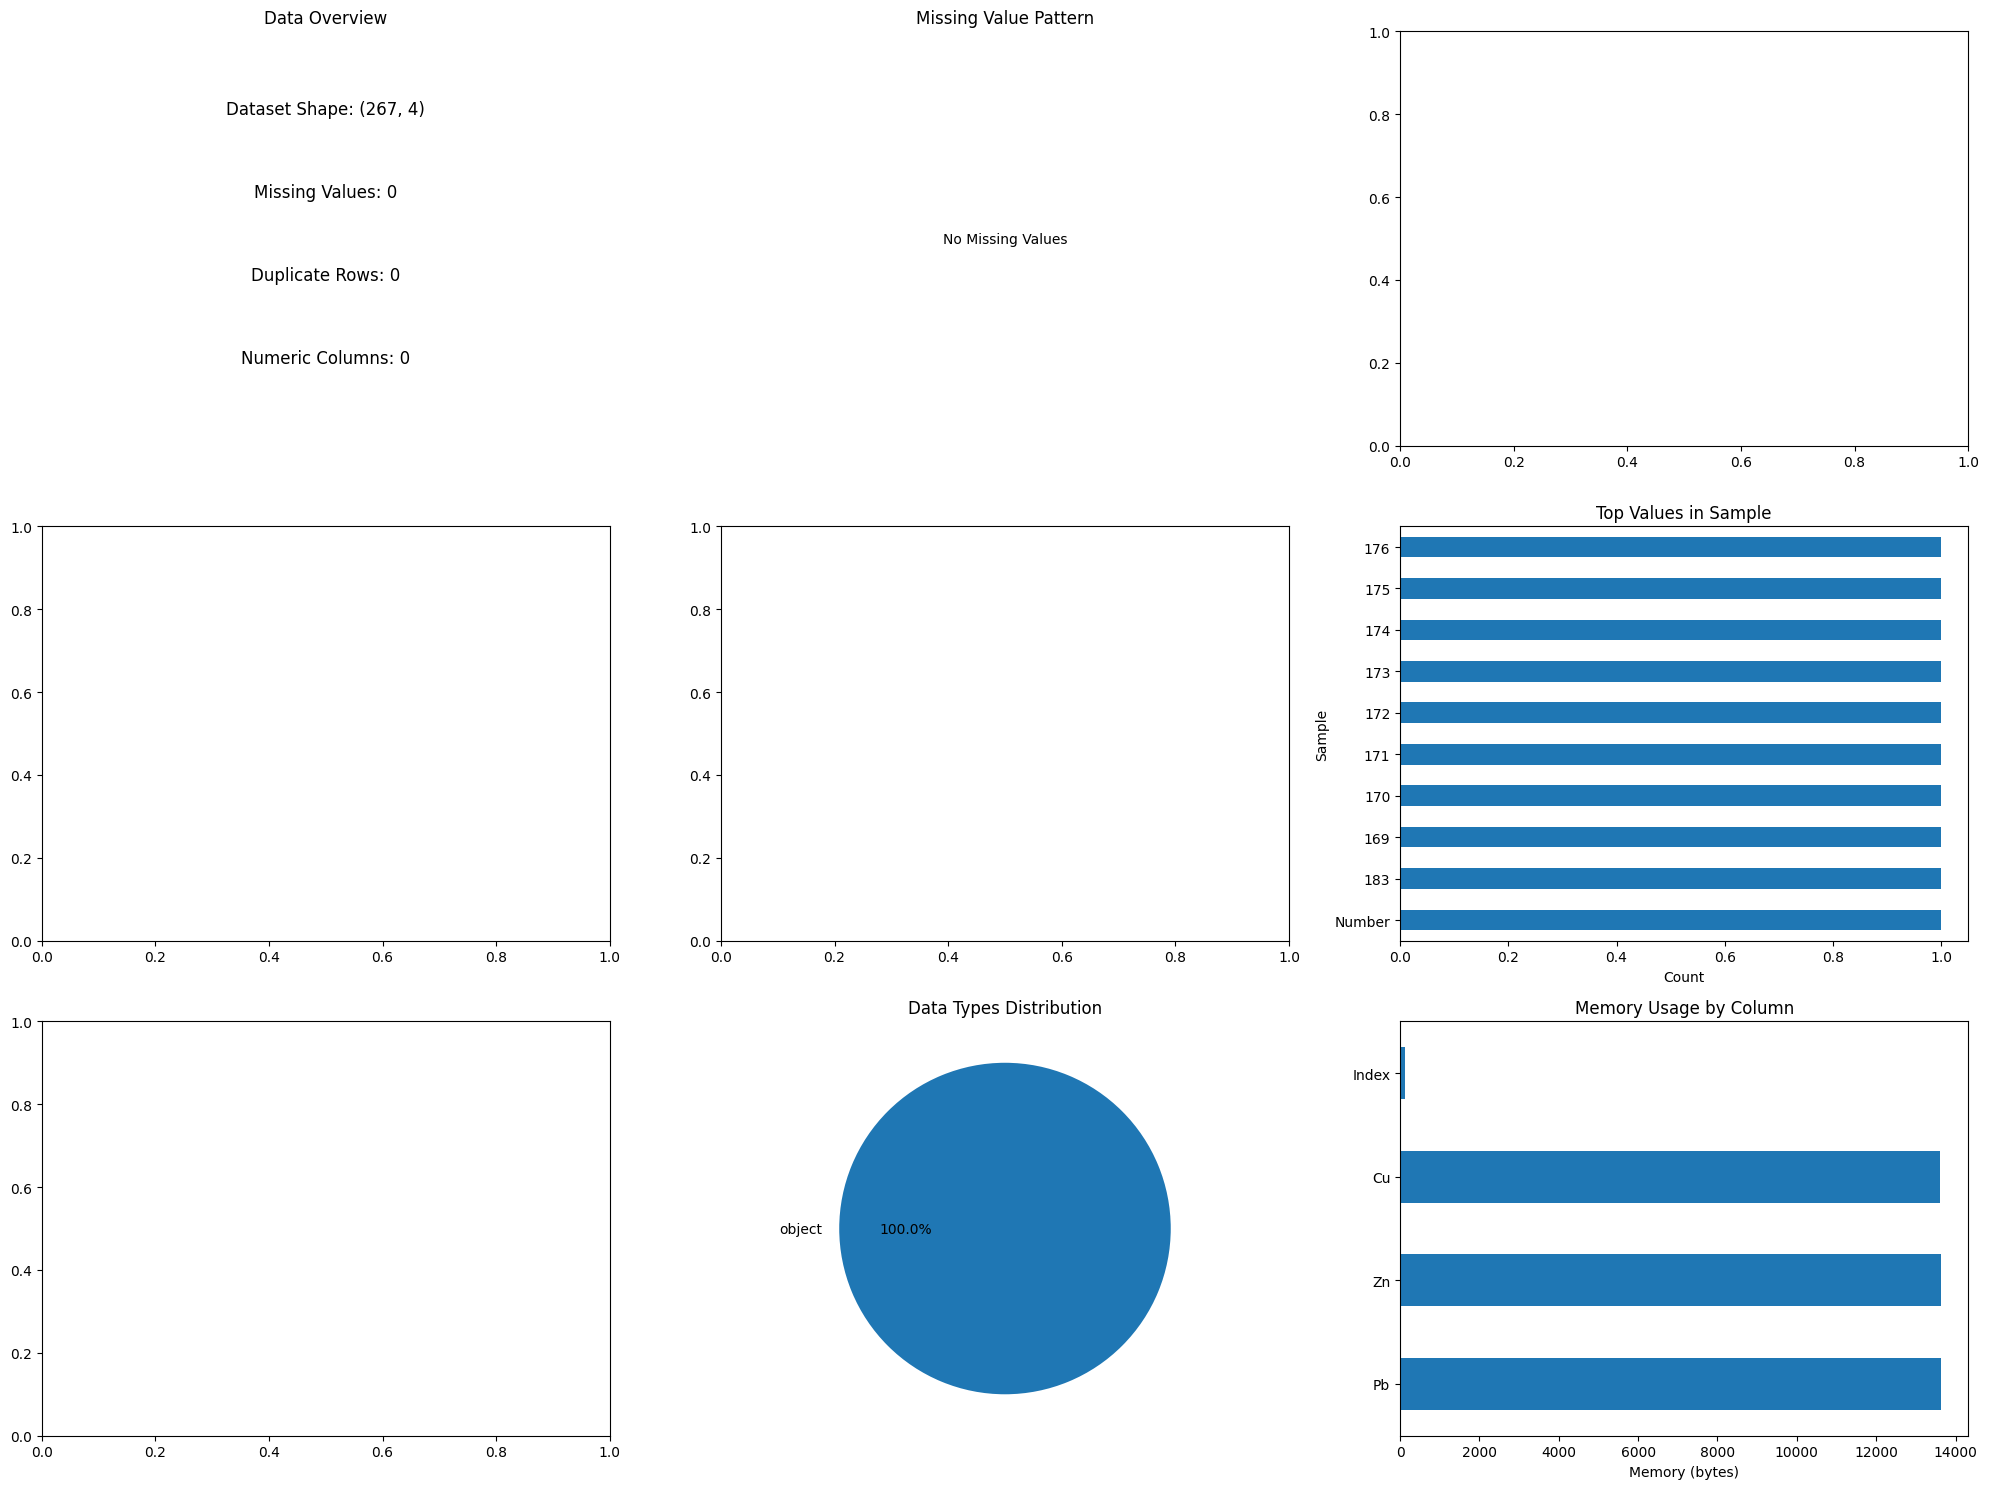


📊 DATASET SUMMARY
Total Rows: 267
Total Columns: 4
Missing Values: 0
Duplicate Rows: 0
Numeric Columns: 0
Categorical Columns: 4
💾 Summary saved to: analysis_results\data_summary.txt


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# ============================================
# FUNCTION 1: Load Data from File Path
# ============================================
def load_data(file_path, file_type=None, **kwargs):
    """
    Load data from various file formats based on file path
    """
    if file_path is None or file_path.strip() == "":
        raise ValueError("❌ File path cannot be empty. Please provide a valid file path.")
    
    file_path = Path(file_path.strip())
    
    if not file_path.exists():
        raise FileNotFoundError(f"❌ File not found: {file_path}")
    
    # Infer file type from extension if not specified
    if file_type is None:
        file_type = file_path.suffix.lower().replace('.', '')
    
    print(f"\n📂 Loading file: {file_path.name}")
    print(f"📁 File type: {file_type}")
    
    try:
        # Load based on file type
        if file_type in ['csv', 'tsv', 'txt']:
            if file_type == 'csv':
                df = pd.read_csv(file_path, **kwargs)
            elif file_type == 'tsv':
                df = pd.read_csv(file_path, sep='\t', **kwargs)
            else:
                df = pd.read_csv(file_path, sep=None, engine='python', **kwargs)
                
        elif file_type in ['xlsx', 'xls']:
            df = pd.read_excel(file_path, **kwargs)
            
        elif file_type == 'json':
            df = pd.read_json(file_path, **kwargs)
            
        elif file_type == 'parquet':
            df = pd.read_parquet(file_path, **kwargs)
            
        elif file_type == 'feather':
            df = pd.read_feather(file_path, **kwargs)
            
        elif file_type == 'pickle' or file_type == 'pkl':
            df = pd.read_pickle(file_path, **kwargs)
            
        else:
            raise ValueError(f"Unsupported file type: {file_type}")
        
        print(f"✅ Successfully loaded {len(df)} rows and {len(df.columns)} columns")
        print(f"📋 Columns: {df.columns.tolist()}")
        return df
        
    except Exception as e:
        print(f"❌ Error loading file: {e}")
        raise

# ============================================
# FUNCTION 2: Visualize Detection Limits
# ============================================
def visualize_detection_limits(df, lod_value=0.5, column=None):
    """
    Automatically detect and visualize detection limits in numeric columns
    """
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("⚠️ No numeric columns found in the dataset!")
        return
    
    if column is not None and column in numeric_cols:
        col_to_plot = column
    else:
        col_to_plot = numeric_cols[0]
        if column is not None:
            print(f"⚠️ Column '{column}' not found or not numeric. Using '{col_to_plot}' instead")
    
    print(f"\n🔍 Visualizing detection limits for column: '{col_to_plot}'")
    
    plt.figure(figsize=(14, 6))
    
    # Before handling
    plt.subplot(1, 2, 1)
    clean_data = df[col_to_plot].replace([np.inf, -np.inf], np.nan).dropna()
    
    if len(clean_data) > 0:
        sns.histplot(clean_data, bins=30, kde=True)
        plt.title(f'Before Detection Limit Handling\nColumn: {col_to_plot}')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        stats_text = f'Mean: {clean_data.mean():.2f}\nMedian: {clean_data.median():.2f}\nStd: {clean_data.std():.2f}\nN: {len(clean_data)}'
        plt.text(0.98, 0.95, stats_text, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data to plot', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    # After handling
    plt.subplot(1, 2, 2)
    data_after = clean_data.copy()
    mask_below_lod = data_after < lod_value
    data_after[mask_below_lod] = lod_value / 2
    
    if len(data_after) > 0:
        sns.histplot(data_after, bins=30, kde=True, color='green')
        plt.title(f'After Detection Limit Handling\n(LOD replaced with LOD/2)')
        plt.axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        plt.axvline(x=lod_value/2, color='orange', linestyle='--', linewidth=2, label=f'LOD/2 = {lod_value/2}')
        plt.xlabel(col_to_plot)
        plt.ylabel('Frequency')
        plt.legend()
        
        stats_text_after = f'Mean: {data_after.mean():.2f}\nMedian: {data_after.median():.2f}\nStd: {data_after.std():.2f}\nN: {len(data_after)}'
        plt.text(0.98, 0.95, stats_text_after, transform=plt.gca().transAxes, 
                verticalalignment='top', horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
        
        affected_count = mask_below_lod.sum()
        total_count = len(data_after)
        plt.text(0.02, 0.95, f'Values below LOD: {affected_count}/{total_count} ({affected_count/total_count*100:.1f}%)',
                transform=plt.gca().transAxes, verticalalignment='top', 
                bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
    else:
        plt.text(0.5, 0.5, 'No valid data after processing', ha='center', va='center')
        plt.title(f'Column: {col_to_plot} - No Data')
    
    plt.tight_layout()
    plt.show()
    
    return numeric_cols

# ============================================
# FUNCTION 3: Complete EDA Visualization
# ============================================
def complete_eda_visualization(df, output_dir=None):
    """
    Complete EDA visualization showing all important aspects
    """
    if output_dir:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
    
    fig = plt.figure(figsize=(20, 15))
    
    # 1. Data Overview
    ax1 = plt.subplot(3, 3, 1)
    ax1.text(0.5, 0.8, f"Dataset Shape: {df.shape}", ha='center', fontsize=12)
    ax1.text(0.5, 0.6, f"Missing Values: {df.isnull().sum().sum()}", ha='center', fontsize=12)
    ax1.text(0.5, 0.4, f"Duplicate Rows: {df.duplicated().sum()}", ha='center', fontsize=12)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    ax1.text(0.5, 0.2, f"Numeric Columns: {len(numeric_cols)}", ha='center', fontsize=12)
    ax1.set_title('Data Overview')
    ax1.axis('off')
    
    # 2. Missing Values Heatmap
    ax2 = plt.subplot(3, 3, 2)
    if df.isnull().sum().sum() > 0:
        sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=ax2)
        ax2.set_title('Missing Value Pattern')
    else:
        ax2.text(0.5, 0.5, 'No Missing Values', ha='center', va='center')
        ax2.set_title('Missing Value Pattern')
        ax2.axis('off')
    
    # 3. Numeric Columns Distribution
    ax3 = plt.subplot(3, 3, 3)
    if numeric_cols:
        first_col = numeric_cols[0]
        clean_data = df[first_col].replace([np.inf, -np.inf], np.nan).dropna()
        if len(clean_data) > 0:
            sns.histplot(clean_data, kde=True, ax=ax3)
            ax3.set_title(f'Distribution of {first_col}')
            ax3.set_xlabel(first_col)
    
    # 4. Correlation Matrix
    ax4 = plt.subplot(3, 3, 4)
    if len(numeric_cols) >= 2:
        corr = df[numeric_cols].corr()
        sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', 
                   square=True, ax=ax4, cbar_kws={'shrink': 0.8})
        ax4.set_title('Correlation Matrix')
    
    # 5. Box Plots for Numeric Columns
    ax5 = plt.subplot(3, 3, 5)
    if numeric_cols:
        cols_to_plot = numeric_cols[:min(5, len(numeric_cols))]
        data_for_box = df[cols_to_plot].replace([np.inf, -np.inf], np.nan)
        if len(data_for_box.columns) > 0:
            data_for_box.boxplot(ax=ax5, rot=45)
            ax5.set_title('Boxplots of Numeric Columns')
    
    # 6. Value Counts for Categorical Columns
    ax6 = plt.subplot(3, 3, 6)
    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    if cat_cols:
        first_cat = cat_cols[0]
        top_categories = df[first_cat].value_counts().head(10)
        if len(top_categories) > 0:
            top_categories.plot(kind='barh', ax=ax6)
            ax6.set_title(f'Top Values in {first_cat}')
            ax6.set_xlabel('Count')
    
    # 7. Scatter Plot
    ax7 = plt.subplot(3, 3, 7)
    if len(numeric_cols) >= 2:
        col1, col2 = numeric_cols[0], numeric_cols[1] if len(numeric_cols) > 1 else numeric_cols[0]
        if col1 != col2:
            scatter_data = df[[col1, col2]].replace([np.inf, -np.inf], np.nan).dropna()
            if len(scatter_data) > 0:
                sns.scatterplot(data=scatter_data, x=col1, y=col2, ax=ax7, alpha=0.5)
                ax7.set_title(f'{col1} vs {col2}')
    
    # 8. Data Types Distribution
    ax8 = plt.subplot(3, 3, 8)
    dtypes = df.dtypes.value_counts()
    dtypes.plot(kind='pie', ax=ax8, autopct='%1.1f%%')
    ax8.set_title('Data Types Distribution')
    ax8.set_ylabel('')
    
    # 9. Memory Usage
    ax9 = plt.subplot(3, 3, 9)
    memory_usage = df.memory_usage(deep=True)
    top_memory = memory_usage.sort_values(ascending=False).head(10)
    if len(top_memory) > 1:
        top_memory[1:].plot(kind='barh', ax=ax9)
        ax9.set_title('Memory Usage by Column')
        ax9.set_xlabel('Memory (bytes)')
    
    plt.tight_layout()
    
    if output_dir:
        fig_path = output_dir / 'eda_visualization.png'
        plt.savefig(fig_path, dpi=300, bbox_inches='tight')
        print(f"💾 Figure saved to: {fig_path}")
    
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("📊 DATASET SUMMARY")
    print("="*60)
    print(f"Total Rows: {len(df)}")
    print(f"Total Columns: {len(df.columns)}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    print(f"Numeric Columns: {len(numeric_cols)}")
    print(f"Categorical Columns: {len(cat_cols)}")
    
    if numeric_cols:
        print("\n📈 Numeric Column Statistics:")
        print(df[numeric_cols].describe().to_string())
    
    if output_dir:
        summary_path = output_dir / 'data_summary.txt'
        with open(summary_path, 'w') as f:
            f.write("DATA SUMMARY\n")
            f.write("="*60 + "\n")
            f.write(f"Total Rows: {len(df)}\n")
            f.write(f"Total Columns: {len(df.columns)}\n")
            f.write(f"Missing Values: {df.isnull().sum().sum()}\n")
            f.write(f"Duplicate Rows: {df.duplicated().sum()}\n")
            f.write(f"Numeric Columns: {len(numeric_cols)}\n")
            f.write(f"Categorical Columns: {len(cat_cols)}\n\n")
            if numeric_cols:
                f.write("Numeric Column Statistics:\n")
                f.write(df[numeric_cols].describe().to_string())
        print(f"💾 Summary saved to: {summary_path}")

# ============================================
# FUNCTION 4: Interactive Detection Limits (Jupyter only)
# ============================================
def interactive_detection_limits(df):
    """
    Interactive visualization with column selection (Jupyter only)
    """
    try:
        from ipywidgets import interact, widgets
    except ImportError:
        print("⚠️ ipywidgets not installed. Run: pip install ipywidgets")
        return
    
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    
    if not numeric_cols:
        print("No numeric columns found!")
        return
    
    def plot_column(col_name, lod_value=0.5, handling_method='LOD/2'):
        clean_data = df[col_name].replace([np.inf, -np.inf], np.nan).dropna()
        
        if len(clean_data) == 0:
            print(f"No valid data in column: {col_name}")
            return
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        axes[0].hist(clean_data, bins=30, alpha=0.7, edgecolor='black')
        axes[0].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        axes[0].set_title(f'Before Handling\n{col_name}')
        axes[0].set_xlabel(col_name)
        axes[0].set_ylabel('Frequency')
        axes[0].legend()
        
        data_after = clean_data.copy()
        if handling_method == 'LOD/2':
            data_after[data_after < lod_value] = lod_value / 2
            label = f'LOD/2 = {lod_value/2}'
        elif handling_method == 'LOD/√2':
            data_after[data_after < lod_value] = lod_value / np.sqrt(2)
            label = f'LOD/√2 = {lod_value/np.sqrt(2):.3f}'
        else:
            data_after = data_after[data_after >= lod_value]
            label = f'Remove < LOD'
        
        axes[1].hist(data_after, bins=30, alpha=0.7, color='green', edgecolor='black')
        axes[1].axvline(x=lod_value, color='red', linestyle='--', linewidth=2, label=f'LOD = {lod_value}')
        if handling_method in ['LOD/2', 'LOD/√2']:
            axes[1].axvline(x=lod_value/2, color='orange', linestyle='--', 
                          linewidth=2, label=label)
        axes[1].set_title(f'After Handling\n{col_name}')
        axes[1].set_xlabel(col_name)
        axes[1].set_ylabel('Frequency')
        axes[1].legend()
        
        plt.tight_layout()
        plt.show()
        
        print(f"\n📊 Statistics for '{col_name}':")
        print(f"Before: Mean={clean_data.mean():.3f}, Median={clean_data.median():.3f}, "
              f"Std={clean_data.std():.3f}")
        print(f"After:  Mean={data_after.mean():.3f}, Median={data_after.median():.3f}, "
              f"Std={data_after.std():.3f}")
        if isinstance(data_after, pd.Series):
            print(f"Values changed: {len(clean_data) - len(data_after)} ({100*(1-len(data_after)/len(clean_data)):.1f}%)")
    
    interact(plot_column,
             col_name=widgets.Dropdown(options=numeric_cols, description='Column:'),
             lod_value=widgets.FloatSlider(min=0.1, max=10, step=0.1, value=0.5, description='LOD Value:'),
             handling_method=widgets.Dropdown(options=['LOD/2', 'LOD/√2', 'Remove'], 
                                             description='Method:'))

# ============================================
# MAIN EXECUTION - Interactive Prompts
# ============================================

def main():
    """
    Main function that interactively prompts for file path and runs analysis
    """
    print("="*70)
    print("🚀 DATA ANALYSIS PIPELINE")
    print("="*70)
    print("\nThis tool will help you analyze your dataset with:")
    print("  • Detection limits visualization")
    print("  • Complete Exploratory Data Analysis (EDA)")
    print("  • Data quality metrics and statistics")
    print("\n" + "="*70)
    
    # Get file path from user
    print("\n📂 Please enter the path to your data file:")
    print("   (Examples: C:\\Users\\YourName\\data.csv or /home/user/data.xlsx)")
    
    while True:
        file_path = input("\n👉 File path: ").strip()
        
        if file_path == "":
            print("❌ File path cannot be empty. Please try again.")
            continue
        
        # Remove quotes if present
        file_path = file_path.strip('"').strip("'")
        
        # Check if file exists
        if not Path(file_path).exists():
            print(f"❌ File not found: {file_path}")
            print("   Please check the path and try again.")
            retry = input("   Try again? (y/n): ").strip().lower()
            if retry != 'y':
                print("❌ Analysis cancelled.")
                return
            continue
        
        break
    
    # Ask for LOD value
    print("\n📊 Please enter the Limit of Detection (LOD) value:")
    print("   (Default: 0.5)")
    lod_input = input("👉 LOD value (press Enter for default): ").strip()
    lod_value = float(lod_input) if lod_input else 0.5
    
    # Ask for specific column (optional)
    print("\n📊 Would you like to specify a column for detection limits visualization?")
    print("   (Press Enter to auto-detect numeric columns)")
    column = input("👉 Column name (optional): ").strip()
    column = column if column else None
    
    # Ask for output directory
    print("\n💾 Would you like to save the results?")
    print("   (Press Enter for default 'analysis_results' folder)")
    output_dir = input("👉 Output directory (optional): ").strip()
    output_dir = output_dir if output_dir else "analysis_results"
    
    # Ask for analysis type
    print("\n🔍 What would you like to do?")
    print("   1. Full Analysis (Load + Detection Limits + Complete EDA)")
    print("   2. Just Load Data and Show Summary")
    print("   3. Detection Limits Visualization Only")
    print("   4. Complete EDA Only")
    print("   5. Interactive Visualization (Jupyter only)")
    print("   6. Custom Analysis (load data and explore manually)")
    
    choice = input("\n👉 Enter your choice (1-6): ").strip()
    
    try:
        # Load data
        print("\n" + "="*70)
        df = load_data(file_path)
        
        if df is None or df.empty:
            print("❌ No data loaded. Exiting.")
            return
        
        # Print first few rows
        print("\n📋 First 5 rows of your data:")
        print(df.head())
        
        # Execute based on choice
        if choice == "1":
            print("\n" + "="*70)
            print("🔍 Running Full Analysis...")
            print("="*70)
            visualize_detection_limits(df, lod_value, column)
            complete_eda_visualization(df, output_dir)
            
        elif choice == "2":
            print("\n" + "="*70)
            print("📊 Data Summary")
            print("="*70)
            print(f"\nShape: {df.shape}")
            print(f"\nColumns: {df.columns.tolist()}")
            print(f"\nData Types:\n{df.dtypes}")
            print(f"\nMissing Values:\n{df.isnull().sum()}")
            print(f"\nStatistical Summary:\n{df.describe()}")
            
        elif choice == "3":
            print("\n" + "="*70)
            print("🔍 Detection Limits Visualization")
            print("="*70)
            visualize_detection_limits(df, lod_value, column)
            
        elif choice == "4":
            print("\n" + "="*70)
            print("📊 Complete EDA")
            print("="*70)
            complete_eda_visualization(df, output_dir)
            
        elif choice == "5":
            print("\n" + "="*70)
            print("🎮 Interactive Visualization")
            print("="*70)
            interactive_detection_limits(df)
            
        elif choice == "6":
            print("\n" + "="*70)
            print("🔧 Custom Analysis Mode")
            print("="*70)
            print("\n✅ Data loaded successfully!")
            print(f"   Shape: {df.shape}")
            print(f"   Columns: {df.columns.tolist()}")
            print("\n💡 You can now explore the data manually using the 'df' variable")
            print("   Example commands:")
            print("   - df.head()")
            print("   - df.info()")
            print("   - df.describe()")
            print("   - df['column_name'].hist()")
            
        else:
            print("❌ Invalid choice. Please run again and select 1-6.")
            
    except Exception as e:
        print(f"\n❌ Error: {e}")
        print("\nPlease check your file and try again.")

# ============================================
# RUN THE PROGRAM
# ============================================

if __name__ == "__main__":
    main()

In [17]:
# Windows example:
FILE_PATH = "Brazildata.csv"

